<a href="https://colab.research.google.com/github/SofiaP2002/SeminarioDeGradoII/blob/main/Versi%C3%B3n_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import json

filepath_version = '/content/version_dos_component.json'
try:
    # Intentar cargar directamente con pandas
    df_version = pd.read_json(filepath_version)
    print("El dataset de componentes y versiones se ha cargado exitosamente.")
    display(df_version.head())
except Exception as e:
    print(f"Ocurrió un error al cargar el JSON: {e}")

El dataset de componentes y versiones se ha cargado exitosamente.


,change_id,issue_id,Change_Type,Field,From_String,To_String,Creation_Date,Author_ID
0,111316,7759,OTHER,Component,None,Documentation,2015-04-03 23:45:09,1586
1,111329,7760,OTHER,Component,None,Documentation,2015-04-03 22:31:37,1586
2,111371,7763,OTHER,Component,None,Documentation,2015-04-03 22:11:44,1586
3,111392,7764,OTHER,Component,Chapter: Introduction,None,2009-09-10 23:10:18,2096
4,111417,7764,OTHER,Component,Front Matter,None,2014-12-16 21:41:50,1586


In [ ]:
pip install sentence-transformers

In [ ]:
import pandas as pd

# Filtrar df_version para asegurar que el componente (To_String) no sea nulo ni vacío
df_valid_components = df_version[df_version['To_String'].notna() & (df_version['To_String'] != 'None') & (df_version['To_String'].astype(str).str.strip() != '')]

# Obtener el primer componente cronológicamente para cada issue_id
df_first_component = df_valid_components.sort_values(by='Creation_Date').groupby('issue_id').first().reset_index()

# Mantener únicamente las columnas de identificación e interés
df_first_component = df_first_component[['issue_id', 'To_String']].rename(columns={'To_String': 'First_Component'})

print("Primeros componentes válidos por cada issue_id filtrados exitosamente.")
display(df_first_component.head())

Primeros componentes válidos por cada issue_id filtrados exitosamente.


,issue_id,First_Component
0,999,Documentation
1,1148,Packaging
2,3474,CLI
3,3765,Runtime
4,3768,Analytics


In [ ]:
import pandas as pd
import json

filepath_comments = '/content/version_dos_comentarios.json'
try:
    # Cargar el dataset de comentarios
    df_comments_version = pd.read_json(filepath_comments)
    print("El dataset de comentarios se ha cargado exitosamente. Columnas detectadas:", list(df_comments_version.columns))

    # Identificar la columna de fecha disponible
    date_col = 'Creation_Date' if 'Creation_Date' in df_comments_version.columns else ('comment_date' if 'comment_date' in df_comments_version.columns else None)

    # Filtrar para asegurar que el comentario no sea nulo ni vacío
    df_valid_comments = df_comments_version[
        df_comments_version['Comment'].notna() &
        (df_comments_version['Comment'].astype(str).str.strip() != '')
    ]

    # Obtener el primer comentario para cada issue_id ordenando por fecha si existe
    if date_col:
        df_first_comment = df_valid_comments.sort_values(by=date_col).groupby('issue_id').first().reset_index()
    else:
        df_first_comment = df_valid_comments.groupby('issue_id').first().reset_index()

    # Mantener únicamente las columnas de identificación e interés
    df_first_comment = df_first_comment[['issue_id', 'Comment']].rename(columns={'Comment': 'First_Comment'})

    print("Primeros comentarios válidos por cada issue_id filtrados exitosamente.")
    display(df_first_comment.head())
except Exception as e:
    print(f"Ocurrió un error al procesar el JSON de comentarios: {e}")

El dataset de comentarios se ha cargado exitosamente. Columnas detectadas: ['comment_id', 'issue_id', 'Comment', 'Comment_Text', 'Comment_Code', 'Creation_Date', 'Author_ID']
Primeros comentarios válidos por cada issue_id filtrados exitosamente.


,issue_id,First_Comment
0,999,If you use a dependency management tool such a...
1,3752,Based on the current performance test setup fo...
2,3758,main requirement here is a websocket sink (but...
3,6489,{quote}If the current responses of endpoints a...
4,6563,[~<EMAIL>] See http://books.sonatype.com/nexus...


## 1. Carga del Dataset


In [ ]:
import pandas as pd

filepath = '/content/version_dos_consolidado.json'
try:
    df = pd.read_json(filepath)
    print(f"El dataset consolidado '{filepath}' se ha cargado exitosamente.")
    display(df.head())
except FileNotFoundError:
    print(f"Error: El archivo '{filepath}' no se encontró. Asegúrate de que está en el directorio correcto.")
except Exception as e:
    print(f"Ocurrió un error al cargar o procesar el dataset: {e}")

El dataset consolidado '/content/version_dos_consolidado.json' se ha cargado exitosamente.


,ID,Jira_ID,Issue_Key,URL,Project_ID,Project_Key,project_name,Creator_ID,Creation_Date,fecha_estimacion_efectiva,...,description,priority,assignee_id,reporter_id,sprint_nombre,sprint_id,sprint_start_date,sprint_end_date,story_point_final,target
0,3760,48134,XD-15,https://jira.spring.io/rest/api/2/issue/48134,1,XD,Spring XD,72,2013-04-12 06:49:47,2013-04-12 06:49:47,...,,Minor,72.0,72.0,None,NaN,None,None,NaN,0
1,4626,758169,NEXUS-25307,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,472,2020-09-16 22:10:36,2020-09-16 22:10:36,...,"""A NXRM PM likes to ensure customers cannot de...",Major,NaN,472.0,None,NaN,None,None,NaN,0
2,4638,757438,NEXUS-25239,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,492,2020-09-10 11:37:34,2020-09-10 11:37:34,...,p2 artifact repositories contain blocks which ...,Major,NaN,492.0,None,NaN,None,None,NaN,0
3,4639,757437,NEXUS-25238,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,492,2020-09-10 11:36:04,2020-09-10 11:36:04,...,Github issue: [https://github.com/sonatype-nex...,Major,NaN,492.0,None,NaN,None,None,NaN,0
4,4640,757436,NEXUS-25237,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,492,2020-09-10 11:32:32,2020-09-10 11:32:32,...,"""Github issue: [https://github.com/sonatype-ne...",Major,NaN,492.0,None,NaN,None,None,NaN,0


In [ ]:
import pandas as pd

# 1. Agrupar y concatenar todos los componentes por issue_id
df_valid_components = df_version[df_version['To_String'].notna() & (df_version['To_String'] != 'None') & (df_version['To_String'].astype(str).str.strip() != '')]
df_all_components = df_valid_components.groupby('issue_id')['To_String'].apply(lambda x: ', '.join(x.astype(str).unique())).reset_index()
df_all_components.rename(columns={'To_String': 'All_Components'}, inplace=True)

# 2. Agrupar y concatenar todos los comentarios por issue_id
df_valid_comments = df_comments_version[df_comments_version['Comment'].notna() & (df_comments_version['Comment'].astype(str).str.strip() != '')]
df_all_comments = df_valid_comments.groupby('issue_id')['Comment'].apply(lambda x: ' | '.join(x.astype(str))).reset_index()
df_all_comments.rename(columns={'Comment': 'All_Comments'}, inplace=True)

# 3. Unir ambos conjuntos agrupados al DataFrame consolidado principal
df = df.merge(df_all_components, left_on='ID', right_on='issue_id', how='left').drop(columns=['issue_id'], errors='ignore')
df = df.merge(df_all_comments, left_on='ID', right_on='issue_id', how='left').drop(columns=['issue_id'], errors='ignore')

print("Unión de todos los componentes y comentarios completada con éxito.")
print(f"Nuevas columnas disponibles: 'All_Components' y 'All_Comments'")
display(df[['ID', 'All_Components', 'All_Comments']].head(10))

Unión de todos los componentes y comentarios completada con éxito.
Nuevas columnas disponibles: 'All_Components' y 'All_Comments'


,ID,All_Components,All_Comments
0,3760,NaN,NaN
1,4626,NaN,NaN
2,4638,NaN,NaN
3,4639,NaN,NaN
4,4640,NaN,NaN
5,4644,NaN,NaN
6,4663,NaN,NaN
7,4699,NaN,NaN
8,4700,NaN,NaN
9,4738,NaN,NaN


In [ ]:
# Unir el primer componente filtrado al DataFrame consolidado ('df' usa la columna 'ID' como identificador del issue)
df = df.merge(df_first_component, left_on='ID', right_on='issue_id', how='left').drop(columns=['issue_id', 'Components_Lista'], errors='ignore')

# Unir el primer comentario filtrado al DataFrame consolidado
df = df.merge(df_first_comment, left_on='ID', right_on='issue_id', how='left').drop(columns=['issue_id'], errors='ignore')

print("Columnas del DataFrame consolidado tras integrar los datos:")
print(df.columns.tolist())

print("\nCantidad de valores no nulos en las nuevas columnas incorporadas:")
print(df[['First_Component', 'First_Comment']].notna().sum())

display(df[['ID', 'First_Component', 'First_Comment']].head(10))

Columnas del DataFrame consolidado tras integrar los datos:
['ID', 'Jira_ID', 'Issue_Key', 'URL', 'Project_ID', 'Project_Key', 'project_name', 'Creator_ID', 'Creation_Date', 'fecha_estimacion_efectiva', 'story_point_inicial', 'estado_al_corte', 'resolucion_al_corte', 'resolution_date_al_corte', 'title', 'description', 'priority', 'assignee_id', 'reporter_id', 'sprint_nombre', 'sprint_id', 'sprint_start_date', 'sprint_end_date', 'story_point_final', 'target', 'First_Component', 'First_Comment']

Cantidad de valores no nulos en las nuevas columnas incorporadas:
First_Component     707
First_Comment      2922
dtype: int64


,ID,First_Component,First_Comment
0,3760,NaN,NaN
1,4626,NaN,NaN
2,4638,NaN,NaN
3,4639,NaN,NaN
4,4640,NaN,NaN
5,4644,NaN,NaN
6,4663,NaN,NaN
7,4699,NaN,NaN
8,4700,NaN,NaN
9,4738,NaN,NaN


In [ ]:
import pandas as pd

# Asegurar que la fecha de estimación efectiva sea de tipo datetime para ordenar cronológicamente
df['fecha_estimacion_efectiva'] = pd.to_datetime(df['fecha_estimacion_efectiva'])

# Ordenar el DataFrame cronológicamente
df = df.sort_values(by='fecha_estimacion_efectiva').reset_index(drop=True)

# Crear la variable 'experiencia_en_proyecto': conteo acumulativo de tareas previas por asignado en cada proyecto
# Usamos cumcount() que inicia en 0 (la primera tarea del desarrollador tendrá experiencia 0, la segunda 1, etc.)
df['experiencia_en_proyecto'] = df.groupby(['Project_ID', 'assignee_id']).cumcount()

# Si no hay un asignado (assignee_id es NaN), rellenamos la experiencia con NaN o 0.
# En este caso, si no está asignado, tiene sentido dejarlo como 0 o mantenerlo como NaN si se prefiere imputar luego.
df.loc[df['assignee_id'].isna(), 'experiencia_en_proyecto'] = 0

print("Característica 'experiencia_en_proyecto' creada exitosamente de forma cronológica.")
display(df[['ID', 'fecha_estimacion_efectiva', 'Project_ID', 'assignee_id', 'experiencia_en_proyecto']].head(15))

Característica 'experiencia_en_proyecto' creada exitosamente de forma cronológica.


,ID,fecha_estimacion_efectiva,Project_ID,assignee_id,experiencia_en_proyecto
0,248745,2009-11-11 16:05:21,29,NaN,0.0
1,248744,2009-11-24 14:51:42,29,NaN,0.0
2,248743,2009-11-24 14:55:56,29,NaN,0.0
3,248740,2009-12-18 02:57:38,29,NaN,0.0
4,248739,2009-12-23 17:32:24,29,NaN,0.0
5,248725,2010-01-04 17:50:45,29,NaN,0.0
6,248723,2010-01-04 17:52:01,29,NaN,0.0
7,248721,2010-01-04 17:55:34,29,NaN,0.0
8,248716,2010-01-04 18:02:59,29,NaN,0.0
9,248715,2010-01-04 18:04:36,29,NaN,0.0


## 2. Visión General del Dataset


In [ ]:
print("Primeras 5 filas del dataset:")
display(df.head())
print("\n--- Información general del dataset ---")
df.info()


Primeras 5 filas del dataset:


,ID,Jira_ID,Issue_Key,URL,Project_ID,Project_Key,project_name,Creator_ID,Creation_Date,fecha_estimacion_efectiva,...,assignee_id,reporter_id,sprint_nombre,sprint_id,sprint_start_date,sprint_end_date,story_point_final,target,All_Components,All_Comments
0,3760,48134,XD-15,https://jira.spring.io/rest/api/2/issue/48134,1,XD,Spring XD,72,2013-04-12 06:49:47,2013-04-12 06:49:47,...,72.0,72.0,None,NaN,None,None,NaN,0,NaN,NaN
1,4626,758169,NEXUS-25307,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,472,2020-09-16 22:10:36,2020-09-16 22:10:36,...,NaN,472.0,None,NaN,None,None,NaN,0,NaN,NaN
2,4638,757438,NEXUS-25239,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,492,2020-09-10 11:37:34,2020-09-10 11:37:34,...,NaN,492.0,None,NaN,None,None,NaN,0,NaN,NaN
3,4639,757437,NEXUS-25238,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,492,2020-09-10 11:36:04,2020-09-10 11:36:04,...,NaN,492.0,None,NaN,None,None,NaN,0,NaN,NaN
4,4640,757436,NEXUS-25237,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,492,2020-09-10 11:32:32,2020-09-10 11:32:32,...,NaN,492.0,None,NaN,None,None,NaN,0,NaN,NaN



--- Información general del dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31394 entries, 0 to 31393
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         31394 non-null  int64  
 1   Jira_ID                    31394 non-null  int64  
 2   Issue_Key                  31394 non-null  object 
 3   URL                        31394 non-null  object 
 4   Project_ID                 31394 non-null  int64  
 5   Project_Key                31394 non-null  object 
 6   project_name               31394 non-null  object 
 7   Creator_ID                 31394 non-null  int64  
 8   Creation_Date              31394 non-null  object 
 9   fecha_estimacion_efectiva  31394 non-null  object 
 10  story_point_inicial        22000 non-null  float64
 11  estado_al_corte            31394 non-null  object 
 12  resolucion_al_corte        2160 non-null   object 
 13  resol

## 3. Estadísticas Descriptivas


In [ ]:
if 'df' in locals() and df is not None:
    print("--- Estadísticas descriptivas del dataset ---")
    display(df.describe())
else:
    print("No se pudieron mostrar las estadísticas descriptivas porque el DataFrame no se cargó correctamente.")

--- Estadísticas descriptivas del dataset ---


,ID,Jira_ID,Project_ID,Creator_ID,story_point_inicial,assignee_id,reporter_id,sprint_id,story_point_final,target
count,31394.000000,3.139400e+04,31394.000000,31394.000000,22000.000000,21748.000000,30524.000000,6699.000000,21733.000000,31394.000000
mean,211776.718927,5.745835e+05,22.826145,124236.869561,4.446890,132925.760300,123827.319060,2752.483206,4.352443,0.131745
std,101790.824102,2.297574e+06,9.600289,54621.252942,12.699831,44129.160963,54886.327828,1093.592960,5.404201,0.338219
min,68.000000,1.124600e+04,1.000000,71.000000,-1.000000,71.000000,71.000000,4.000000,0.000000,0.000000
25%,219818.250000,2.859025e+04,24.000000,144955.000000,1.000000,145723.000000,144921.750000,2910.000000,1.000000,0.000000
50%,230668.500000,6.003150e+04,28.000000,145754.000000,3.000000,145763.000000,145750.000000,3040.000000,3.000000,0.000000
75%,241162.750000,2.554865e+05,28.000000,145825.000000,5.000000,145832.000000,145811.000000,3159.000000,5.000000,0.000000
max,460229.000000,1.327086e+07,42.000000,199934.000000,1010.000000,199275.000000,199934.000000,4970.000000,105.000000,1.000000


## 4. Conteo de Valores Nulos

In [ ]:
print("--- Conteo de valores nulos por columna ---")
print(df.isnull().sum())

--- Conteo de valores nulos por columna ---
title                     0
description               0
priority                  0
story_point_inicial    9394
target                    0
All_Components            0
All_Comments              0
assignee_id            9646
reporter_id             870
Project_ID                0
dtype: int64


## 5. Frecuencia de Columnas Categóricas

In [ ]:
categorical_columns = ['priority', 'sprint_id', 'Project_ID', 'assignee_id', 'reporter_id']

for col in categorical_columns:
  print(f"\n--- Frecuencia de la columna '{col}' ---")

  display(df[col].value_counts().head())



--- Frecuencia de la columna 'priority' ---


,count
priority,
,19341
Medium,3443
Minor,2861
Major,1616
None,1357



--- Frecuencia de la columna 'sprint_id' ---


,count
sprint_id,
3159.0,67
3153.0,50
6.0,48
3143.0,47
3125.0,47



--- Frecuencia de la columna 'Project_ID' ---


,count
Project_ID,
28,19578
24,2748
1,2593
12,1225
13,914



--- Frecuencia de la columna 'assignee_id' ---


,count
assignee_id,
145769.0,691
145726.0,530
145778.0,483
145811.0,450
145720.0,442



--- Frecuencia de la columna 'reporter_id' ---


,count
reporter_id,
145778.0,992
145726.0,876
145807.0,765
145769.0,648
145720.0,602


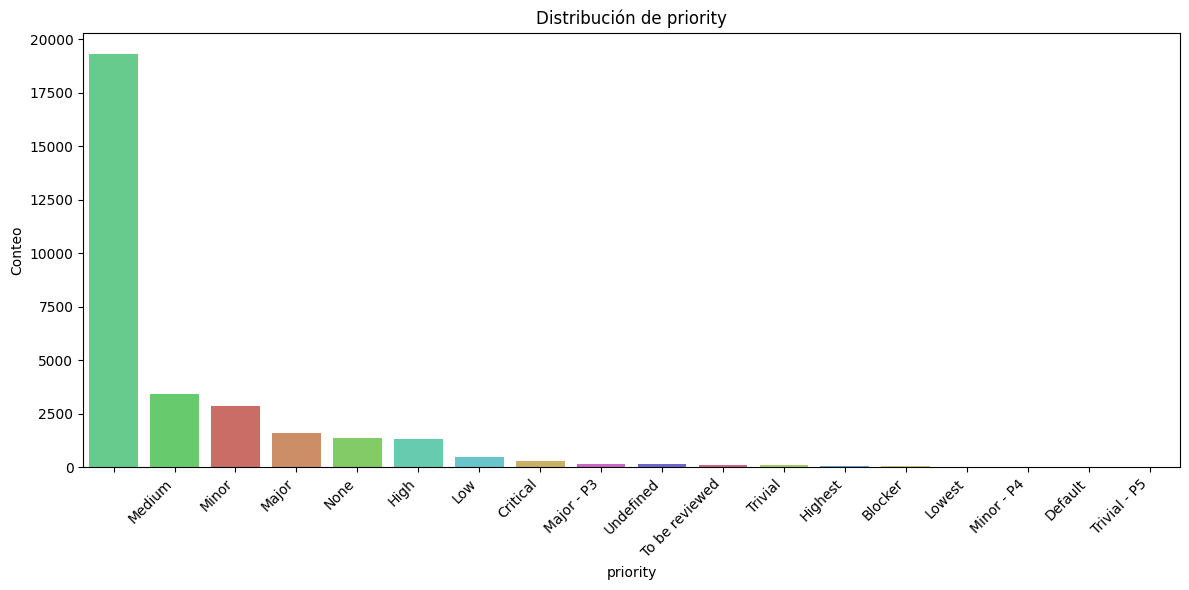

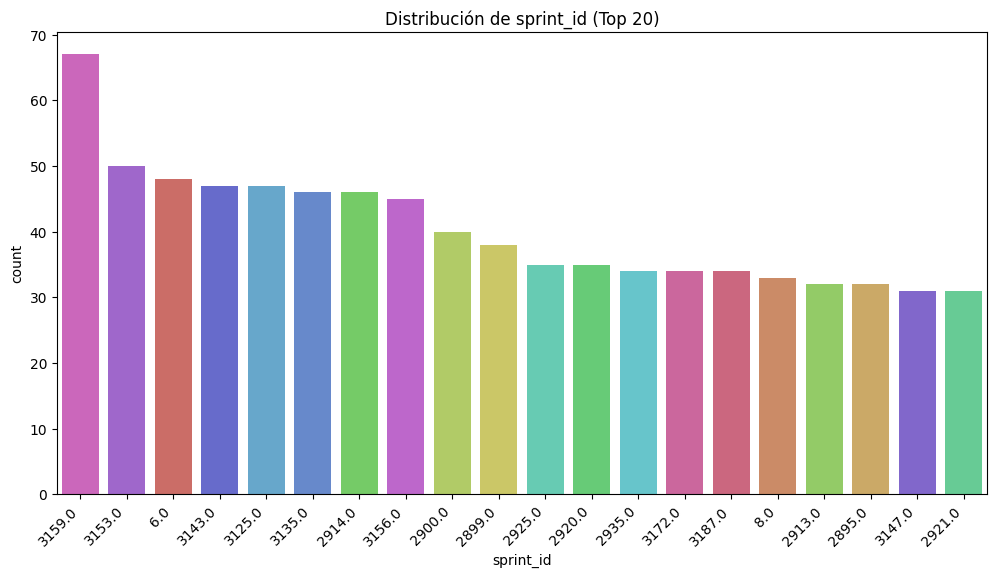

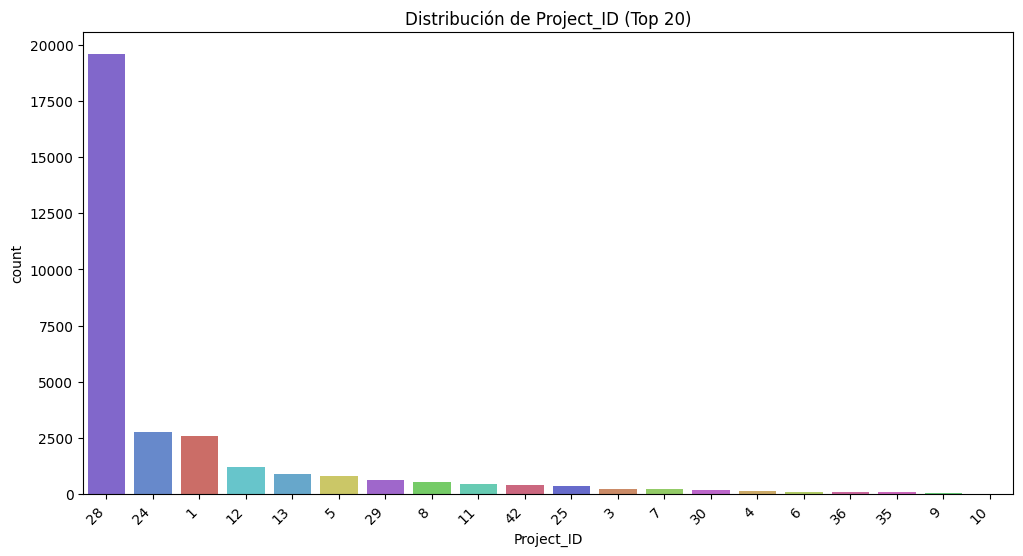

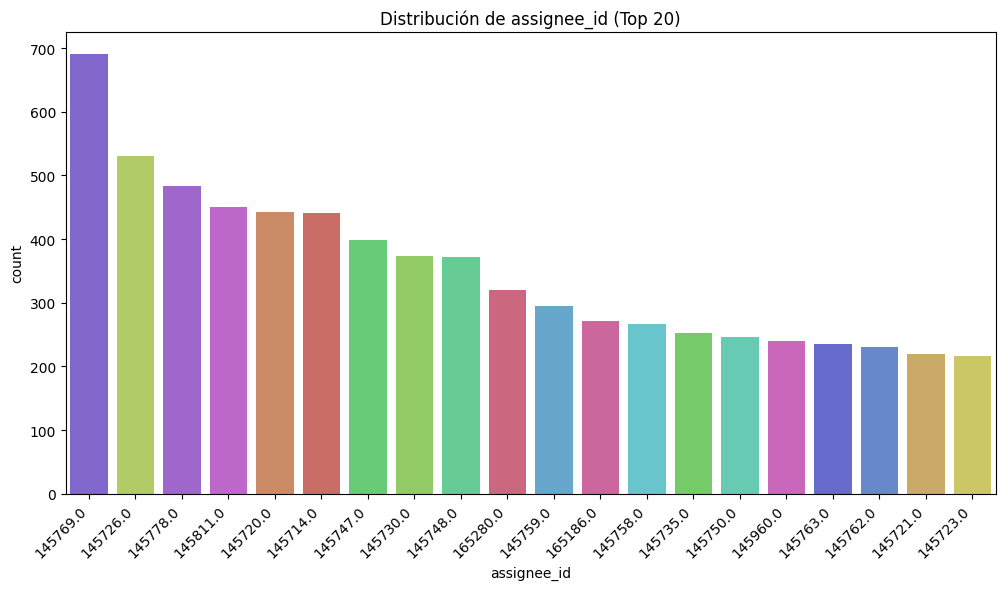

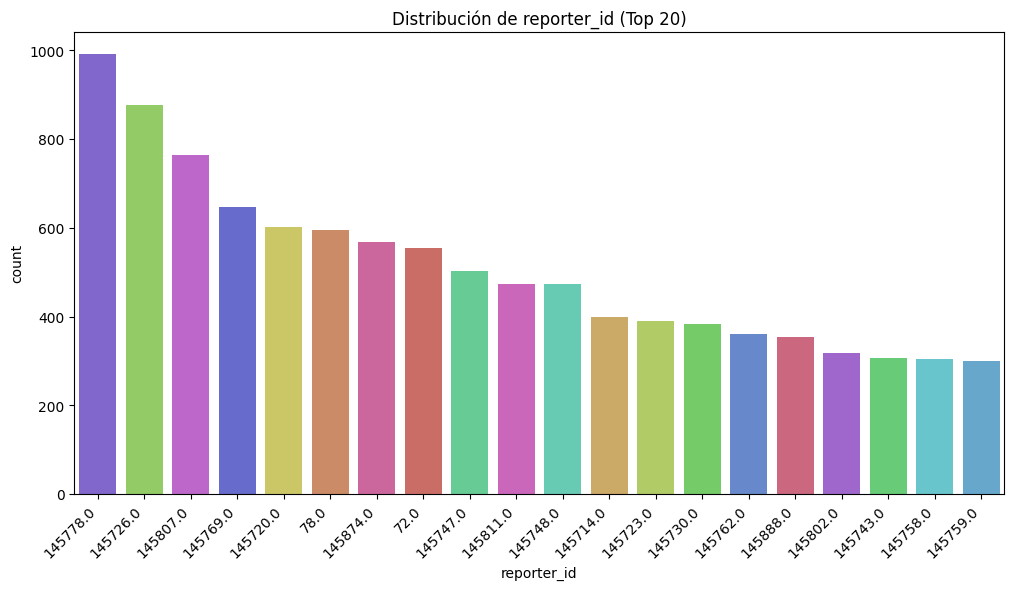

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

categorical_columns = ['priority', 'sprint_id', 'Project_ID', 'assignee_id', 'reporter_id']

for col in categorical_columns:
  plt.figure(figsize=(12, 6))
  if df[col].nunique() > 20:

    top_categories = df[col].value_counts().nlargest(20).index
    n_colors_to_use = len(top_categories)
    current_palette = sns.color_palette("hls", n_colors=n_colors_to_use)
    sns.countplot(data=df[df[col].isin(top_categories)], x=col, order=top_categories, palette=current_palette, hue=col, legend=False)
    plt.title(f'Distribución de {col} (Top 20)')
    plt.xticks(rotation=45, ha='right')
  else:
    n_colors_to_use = df[col].nunique()
    current_palette = sns.color_palette("hls", n_colors=n_colors_to_use)
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette=current_palette, hue=col, legend=False)
    plt.title(f'Distribución de {col}')
    plt.xticks(rotation=45, ha='right')
    plt.xlabel(col)
    plt.ylabel('Conteo')
    plt.tight_layout()
    plt.show()


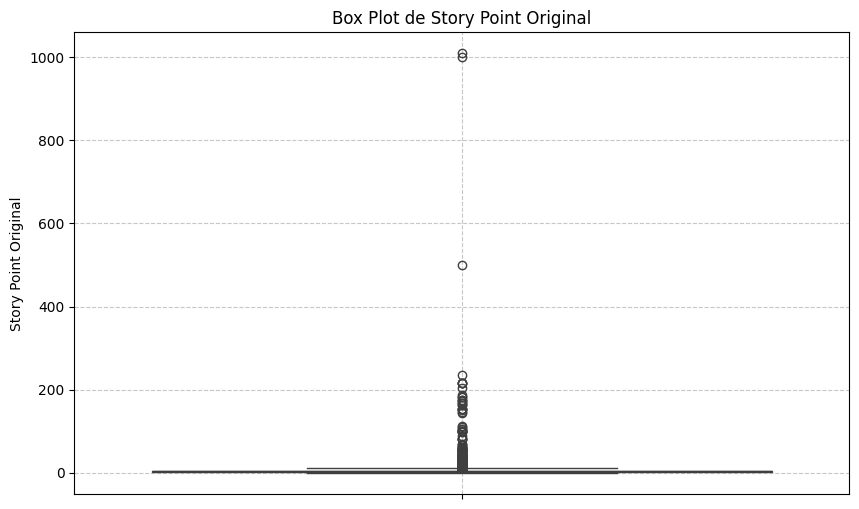

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(y=df['story_point_inicial'])
plt.title('Box Plot de Story Point Original')
plt.ylabel('Story Point Original')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


Generando box plot para 'Story_Point_Original' con escala logarítmica en el eje Y...


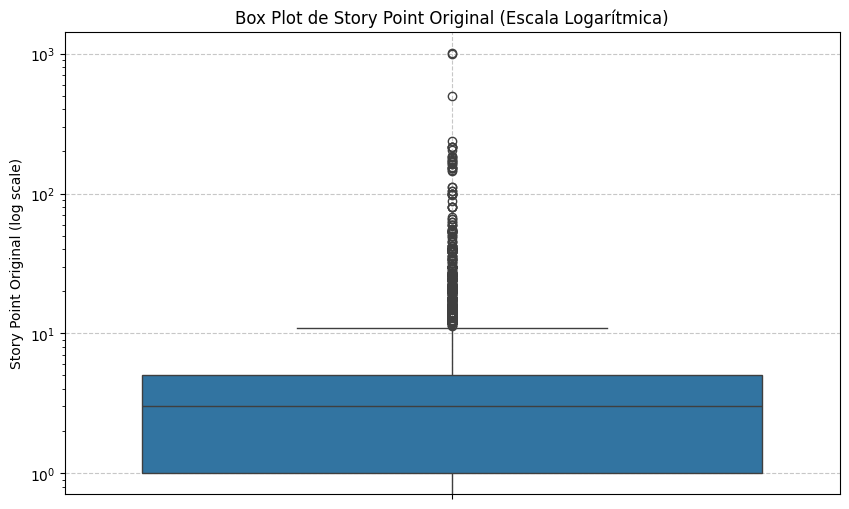

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Generando box plot para 'Story_Point_Original' con escala logarítmica en el eje Y...")
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['story_point_inicial'])
plt.title('Box Plot de Story Point Original (Escala Logarítmica)')
plt.ylabel('Story Point Original (log scale)')
plt.yscale('log') # Aplicar escala logarítmica al eje Y
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


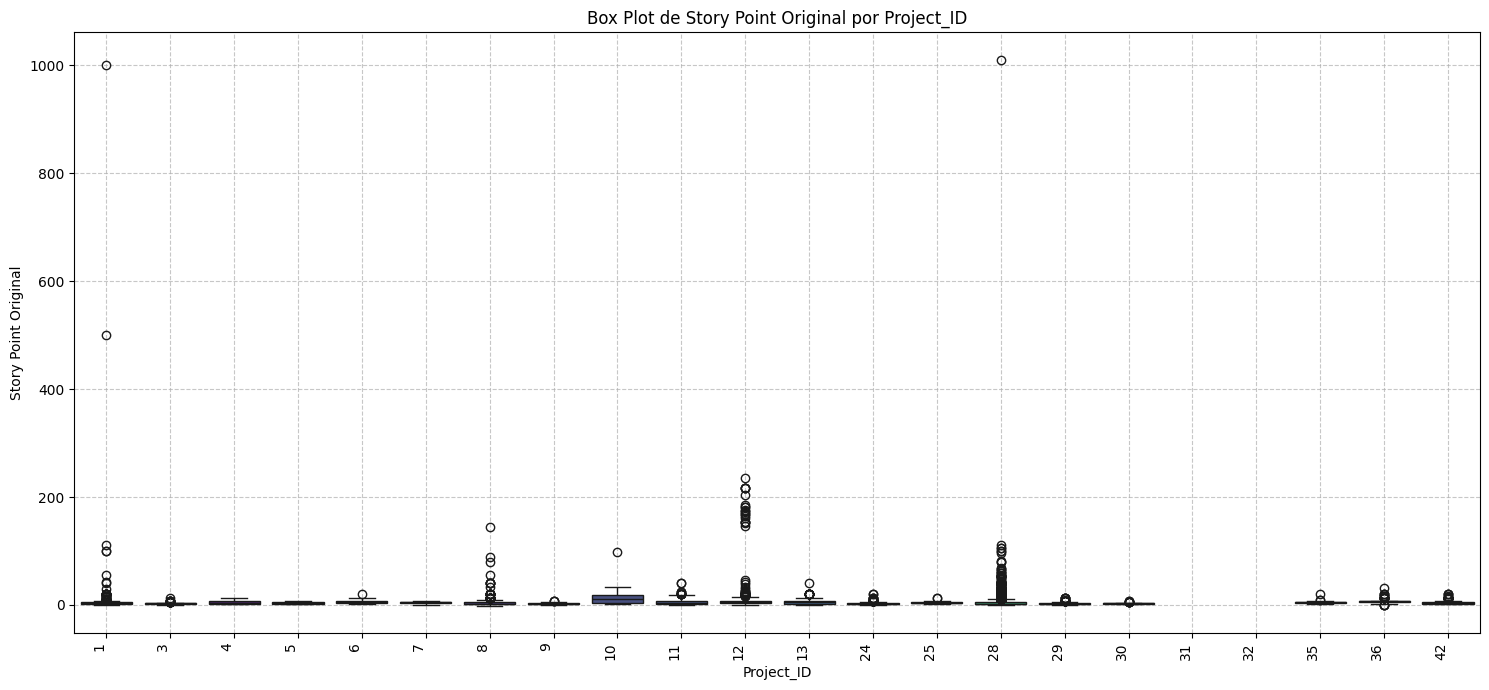

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 7))
sns.boxplot(x='Project_ID', y='story_point_inicial', data=df, palette='viridis', hue='Project_ID', legend=False)
plt.title('Box Plot de Story Point Original por Project_ID')
plt.xlabel('Project_ID')
plt.ylabel('Story Point Original')
plt.xticks(rotation=90, ha='right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


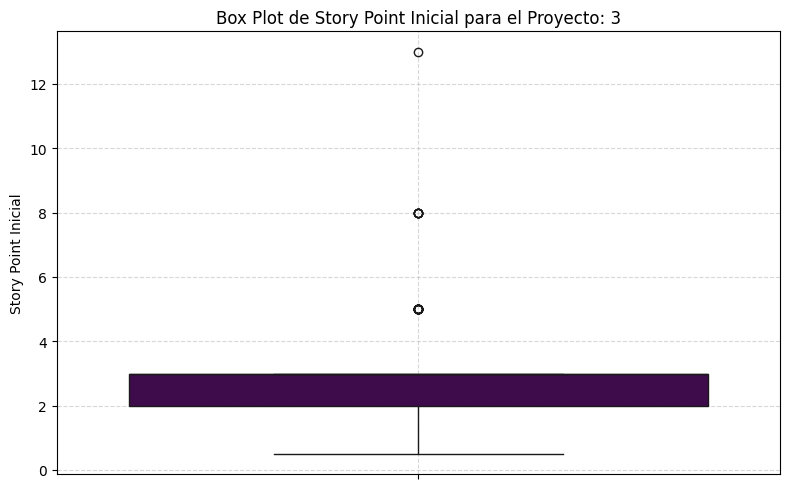

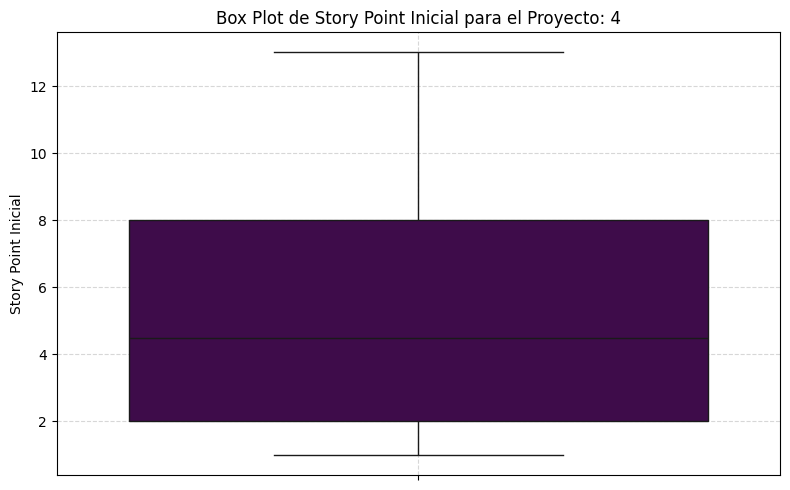

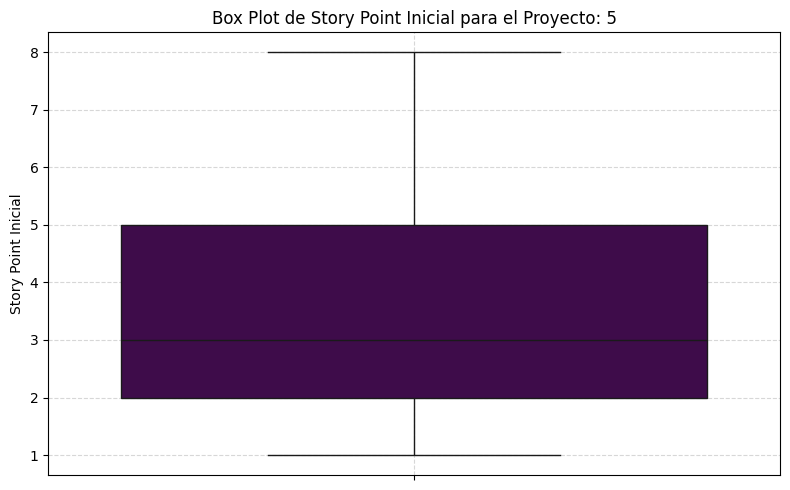

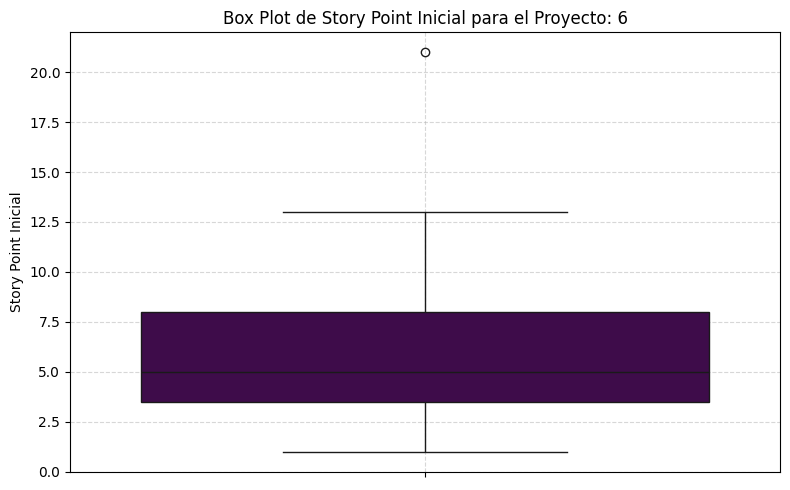

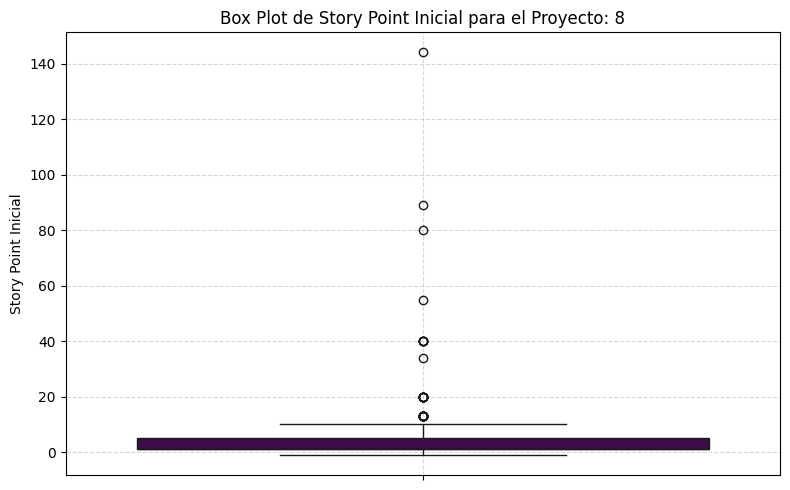

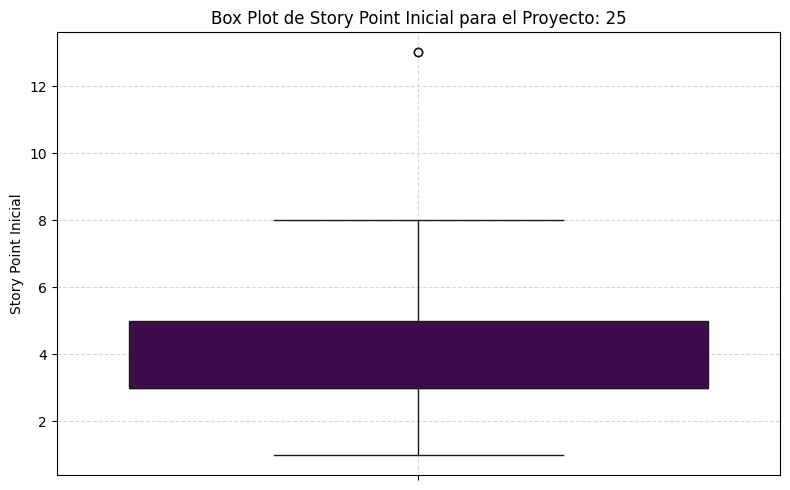

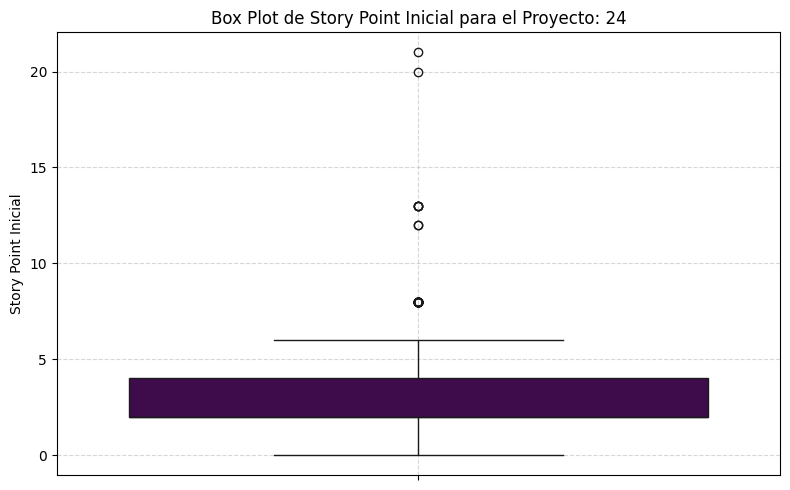

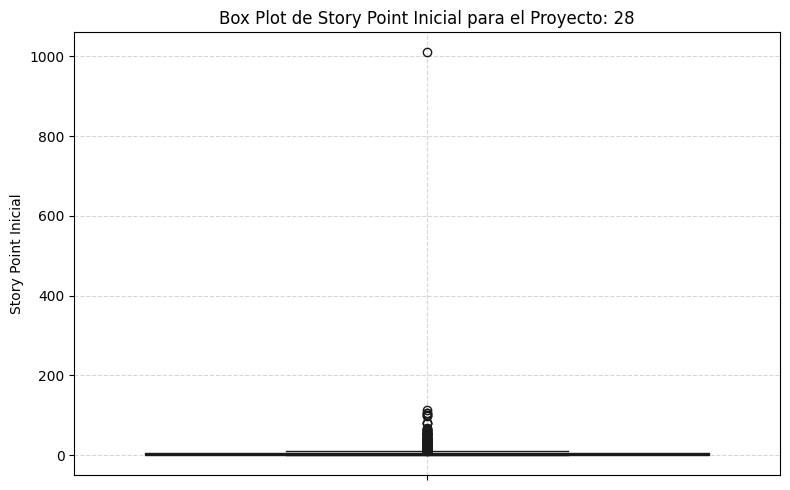

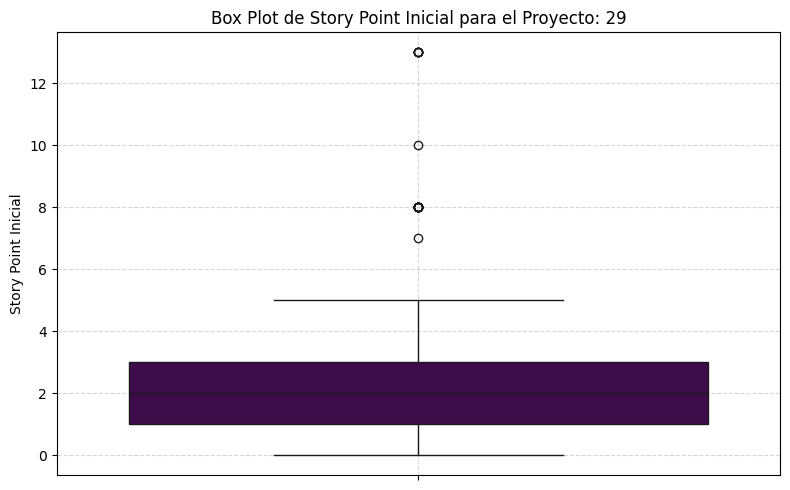

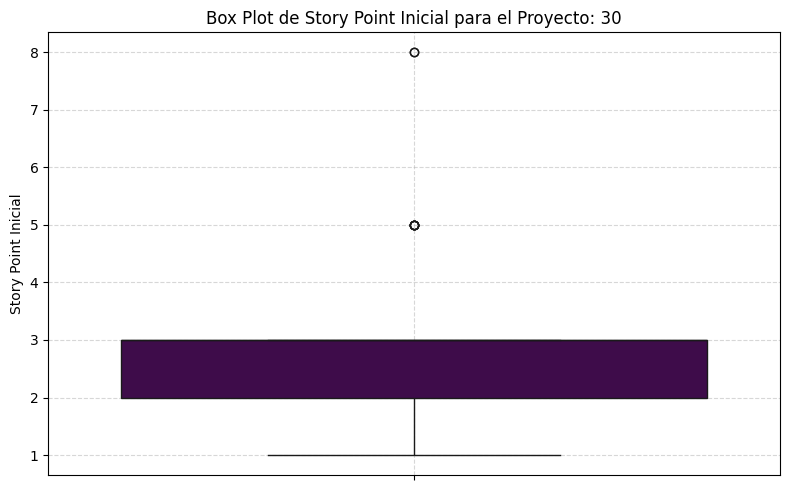

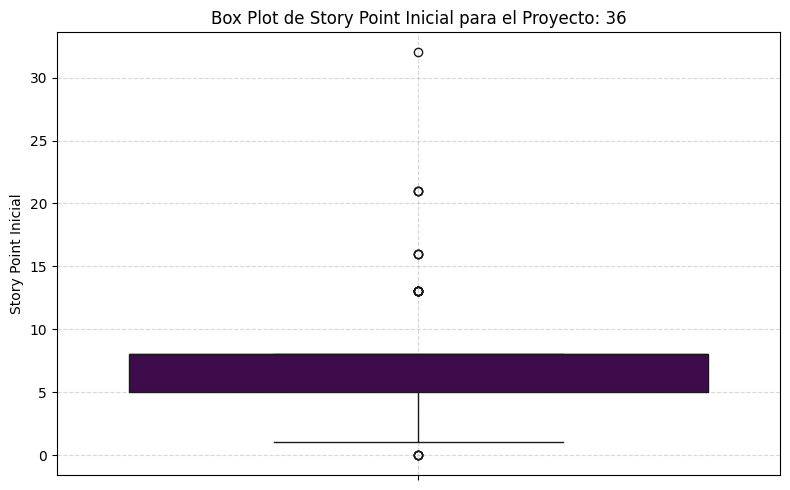

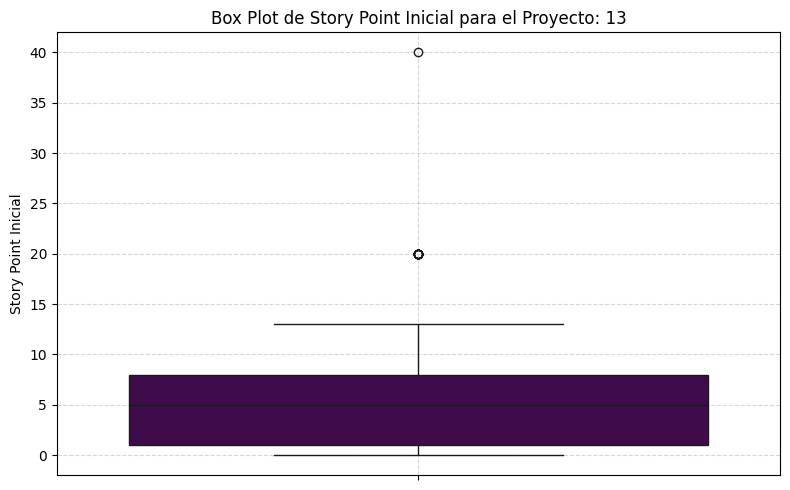

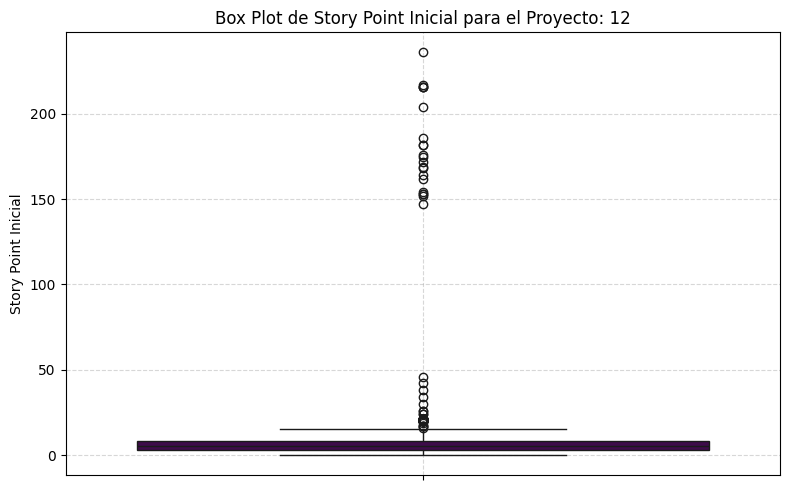

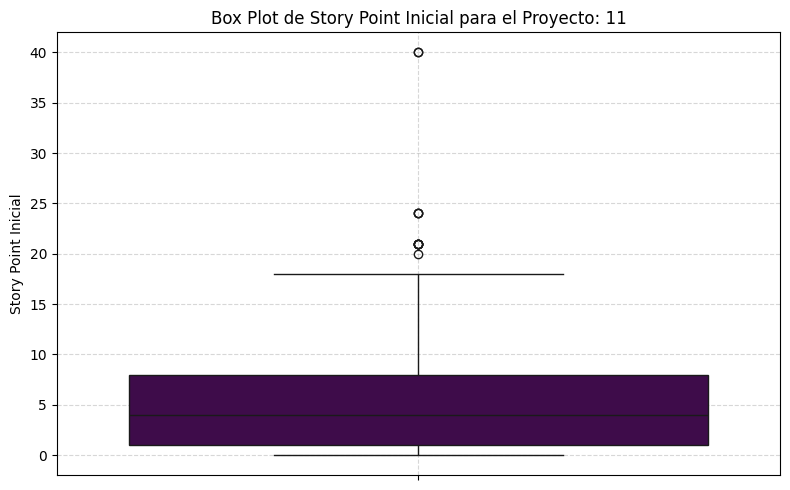

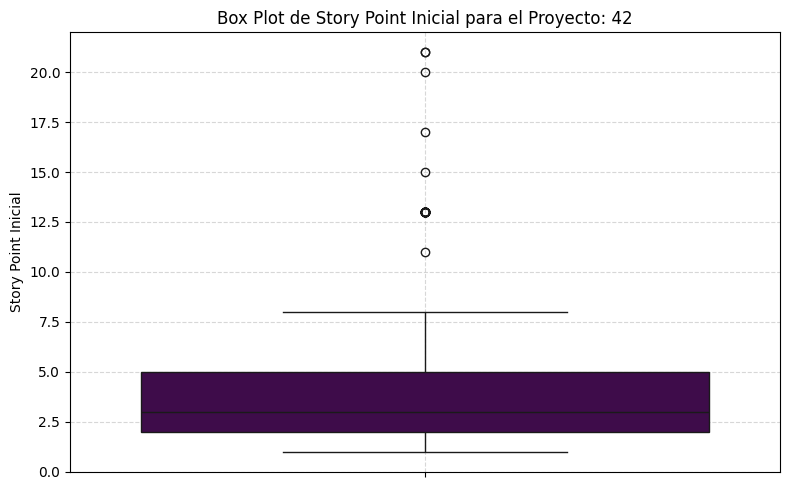

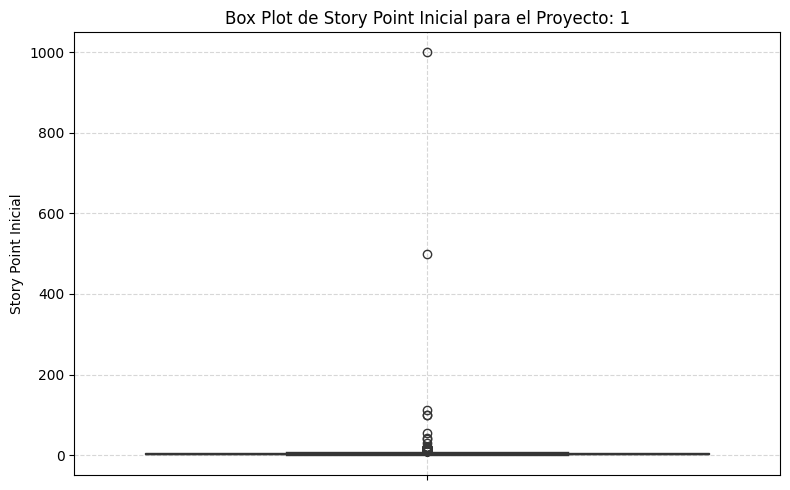

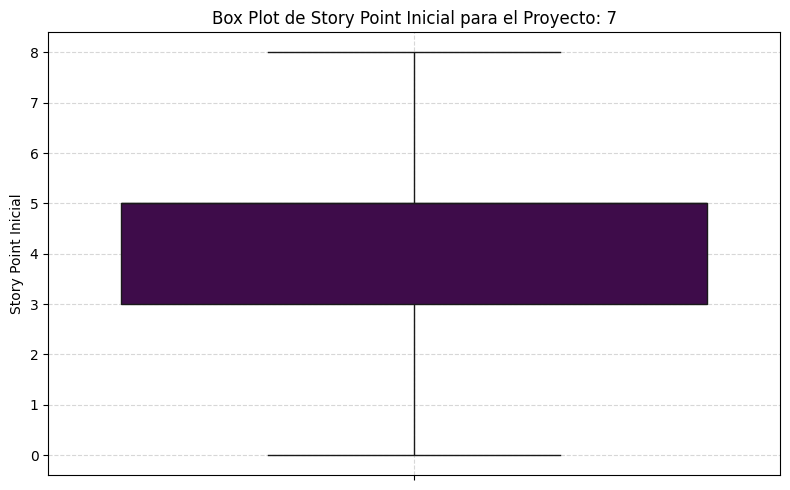

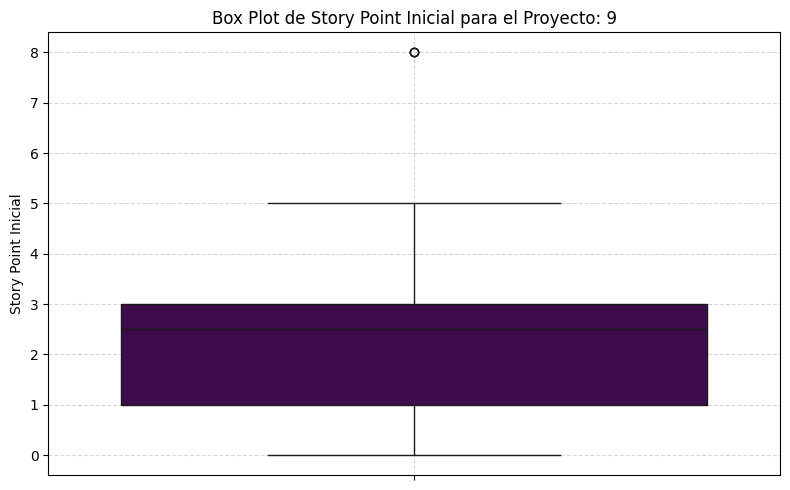

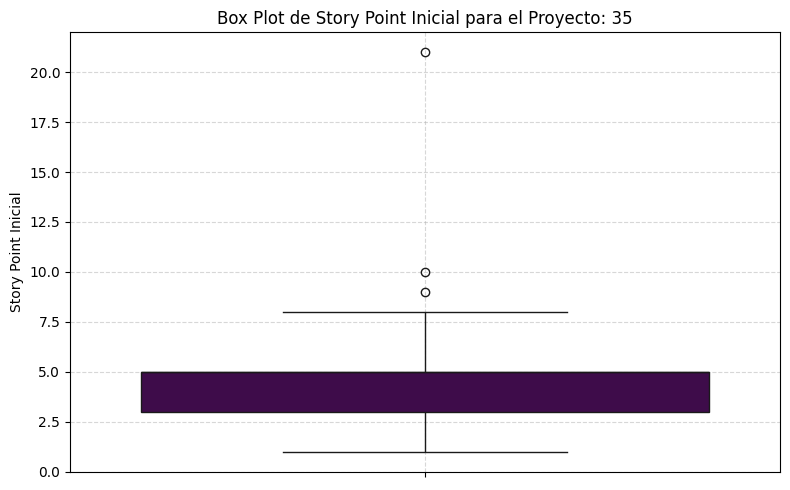

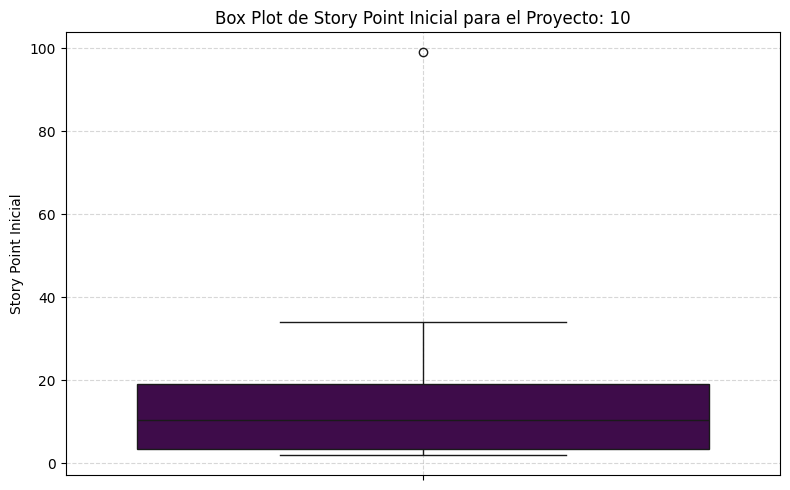

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar filas donde 'story_point_inicial' no sea nulo
df_filtered = df.dropna(subset=['story_point_inicial'])
unique_project_ids = df_filtered['Project_ID'].unique()

for project_id in unique_project_ids:
    subset_df = df_filtered[df_filtered['Project_ID'] == project_id]

    if not subset_df.empty:
        plt.figure(figsize=(8, 5))
        # Graficar individualmente definiendo x o hue para evitar advertencias de Seaborn
        sns.boxplot(y=subset_df['story_point_inicial'], hue=subset_df['Project_ID'], palette='viridis', legend=False)
        plt.title(f'Box Plot de Story Point Inicial para el Proyecto: {project_id}')
        plt.ylabel('Story Point Inicial')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

Generando countplot para la columna 'target'...


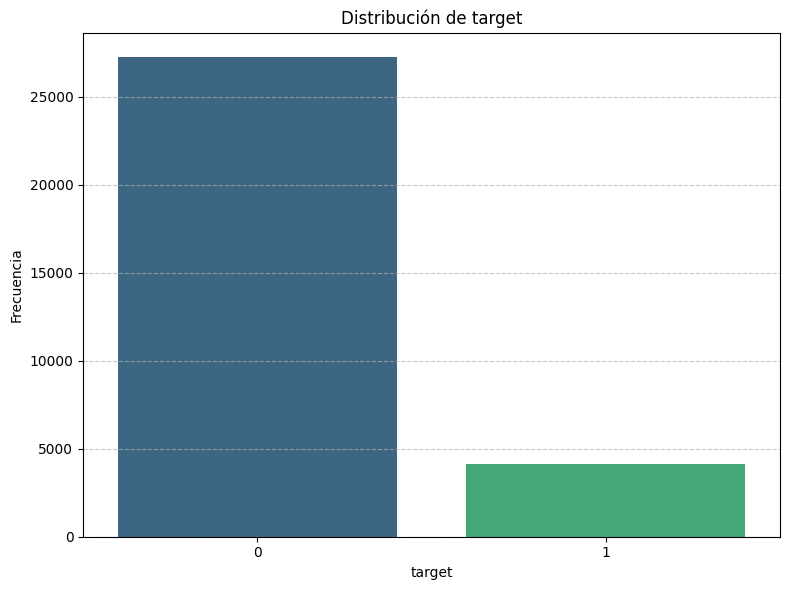

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

column_name = 'target'
print(f"Generando countplot para la columna '{column_name}'...")
plt.figure(figsize=(8, 6))
# Apply the recommended change to address the FutureWarning
sns.countplot(x=column_name, data=df, palette='viridis', hue=column_name, legend=False)
plt.title(f'Distribución de {column_name}')
plt.xlabel(column_name)
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
count_table = df.groupby(['Project_ID', 'target']).size().unstack(fill_value=0)

print("--- Conteo de Story Point Changed After Estimation por Project_ID ---")
display(count_table)


--- Conteo de Story Point Changed After Estimation por Project_ID ---


target,0,1
Project_ID,,
1,2227,366
3,205,38
4,147,4
5,759,46
6,97,4
7,232,1
8,409,122
9,47,1
10,28,0


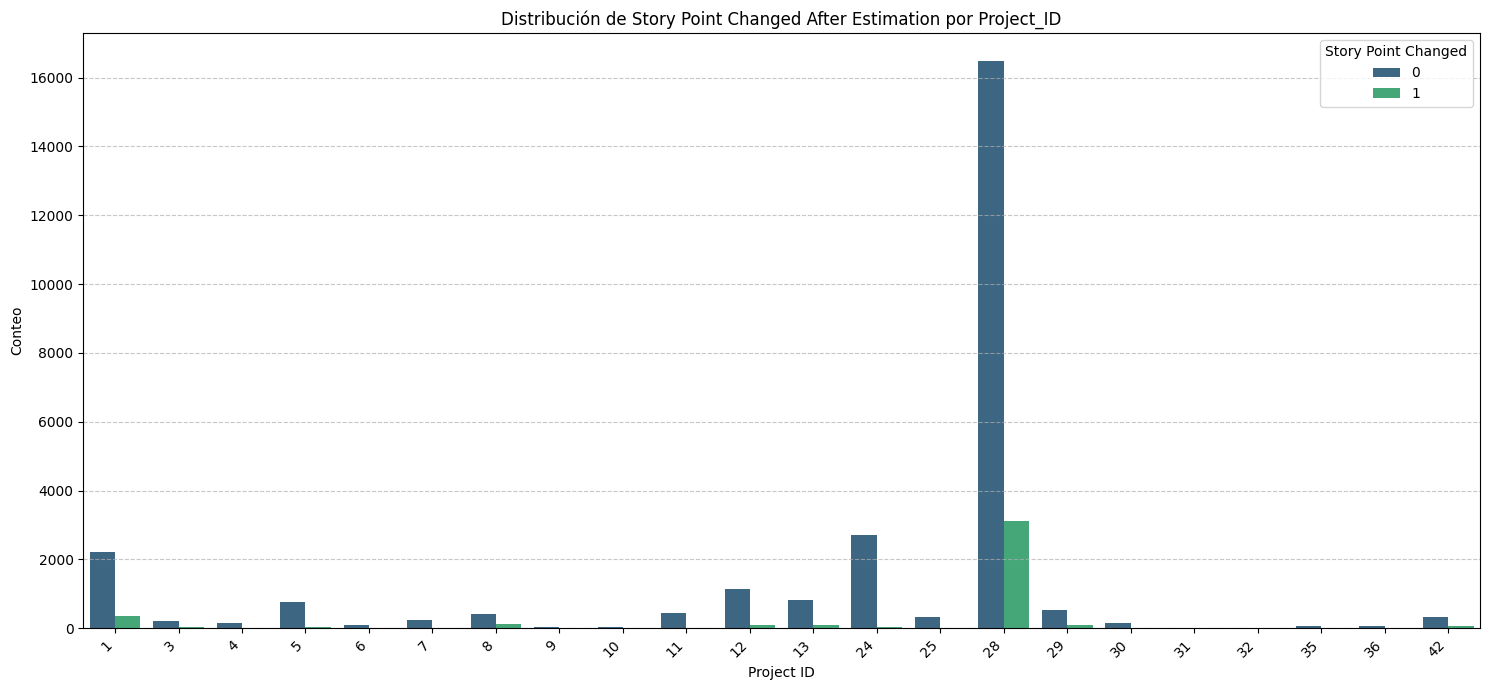

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(15, 7))

sns.countplot(data=df, x='Project_ID', hue='target', palette='viridis')

plt.title('Distribución de Story Point Changed After Estimation por Project_ID')
plt.xlabel('Project ID')
plt.ylabel('Conteo')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Story Point Changed')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


Generando gráficos individuales de distribución de 'Story_Point_Changed_After_Estimation' por cada 'Project_ID'...


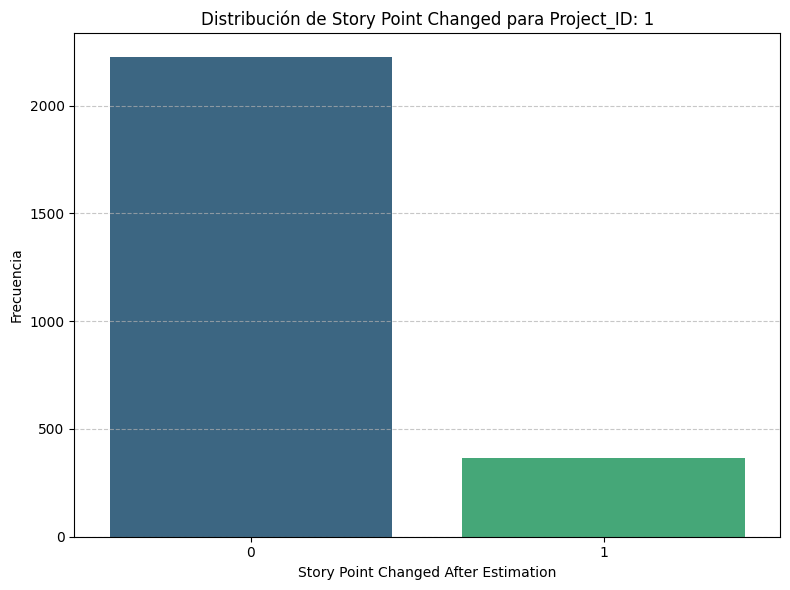

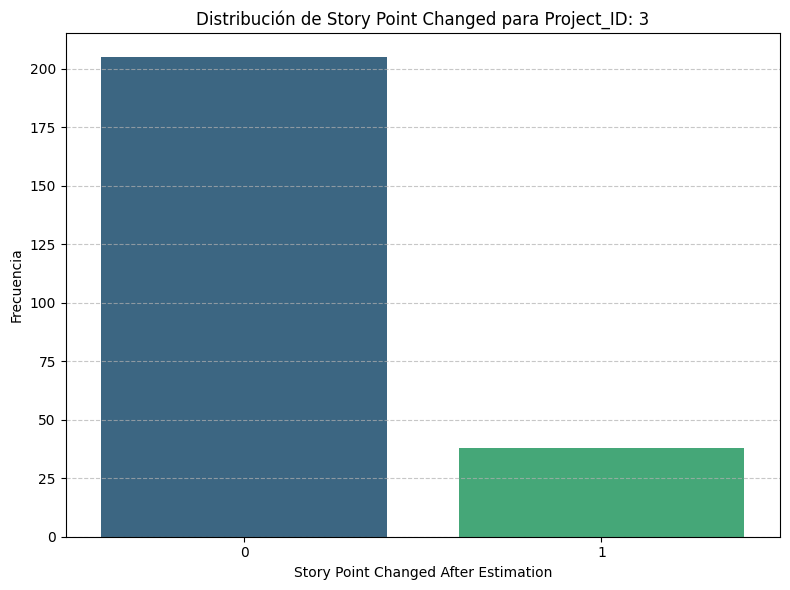

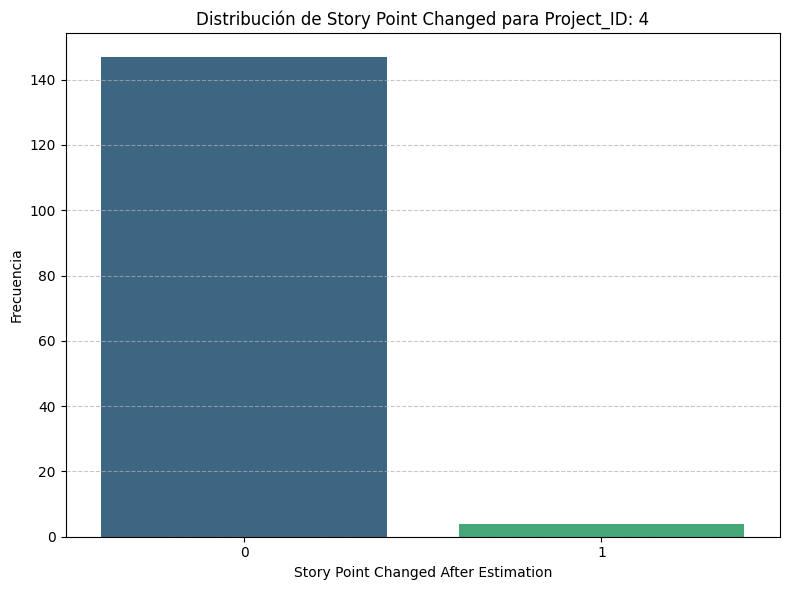

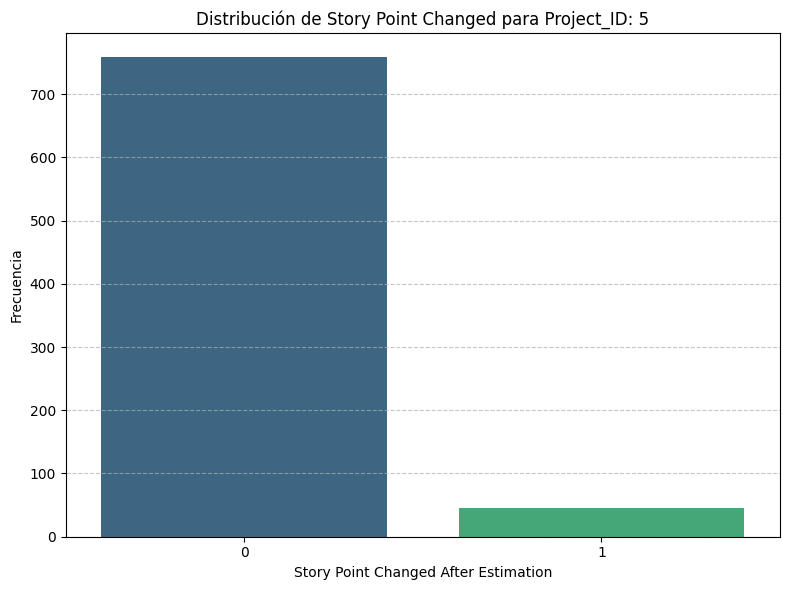

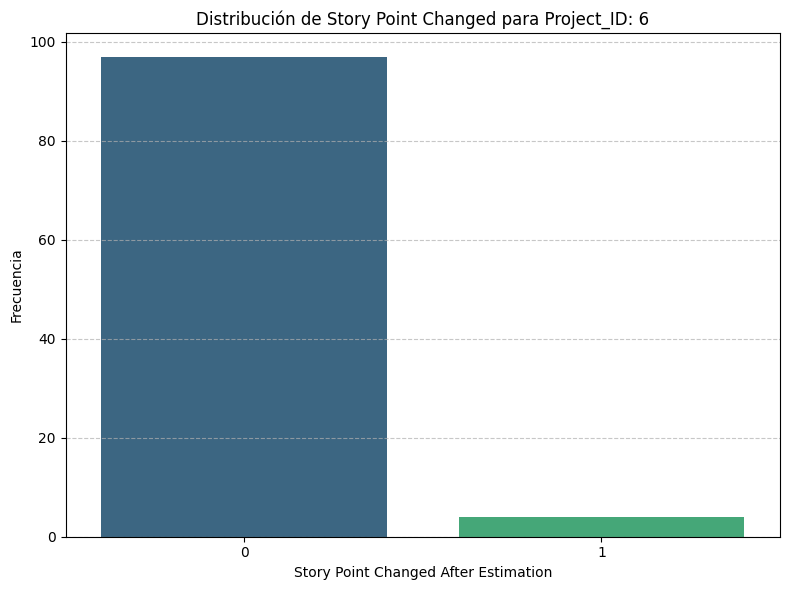

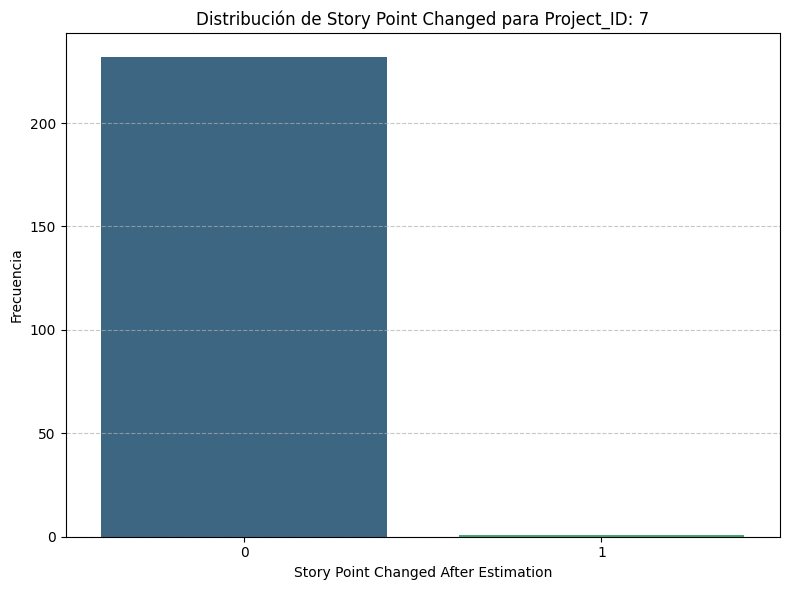

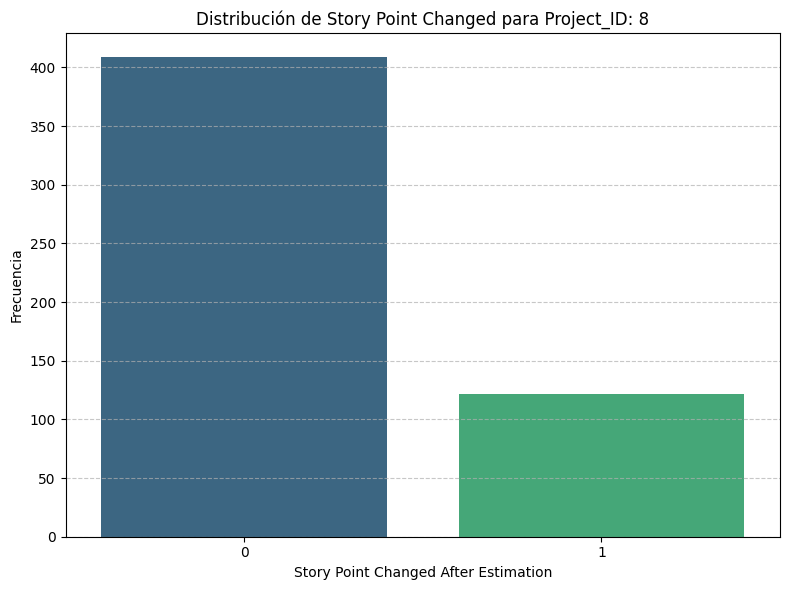

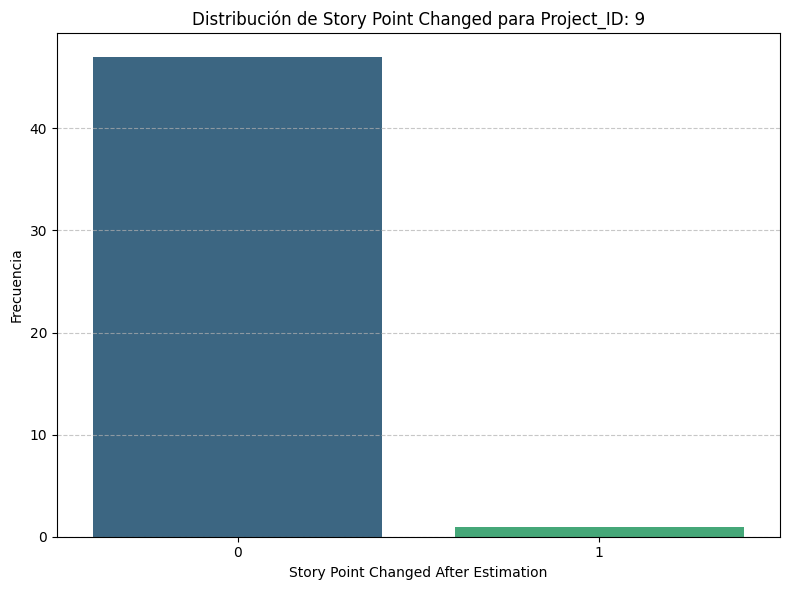

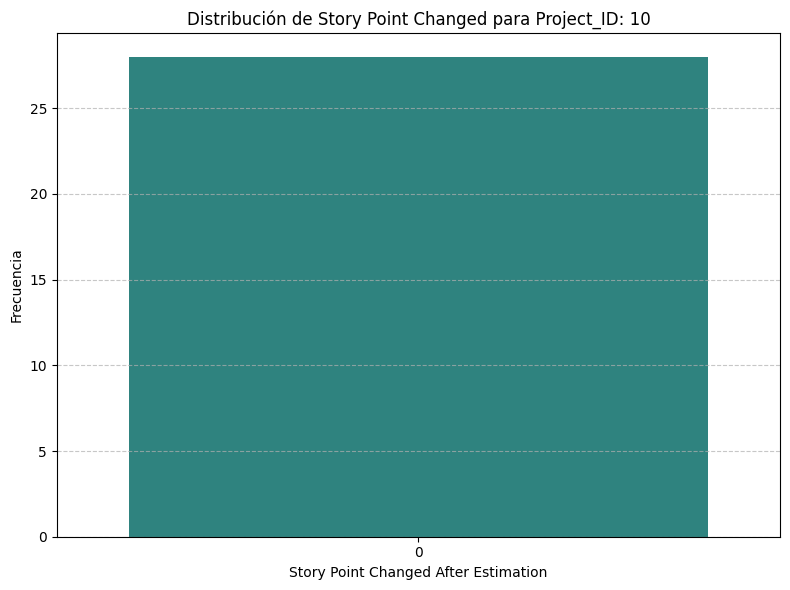

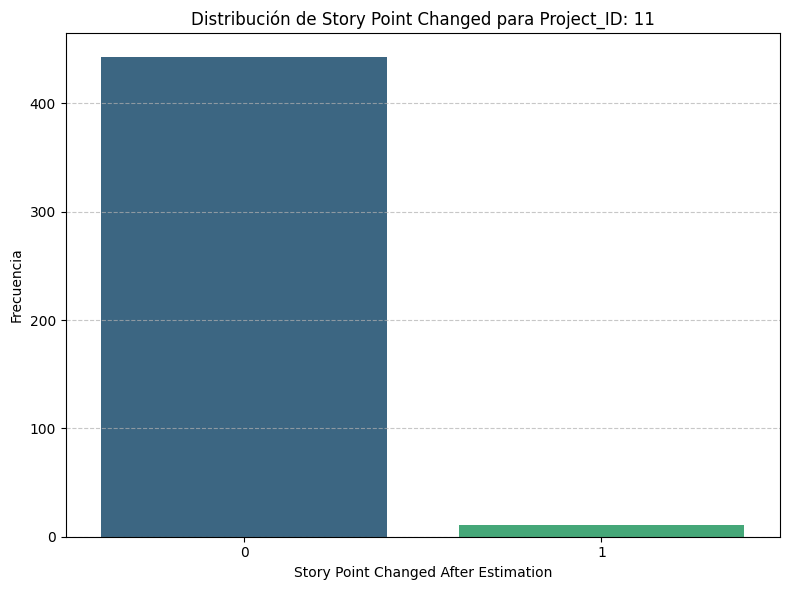

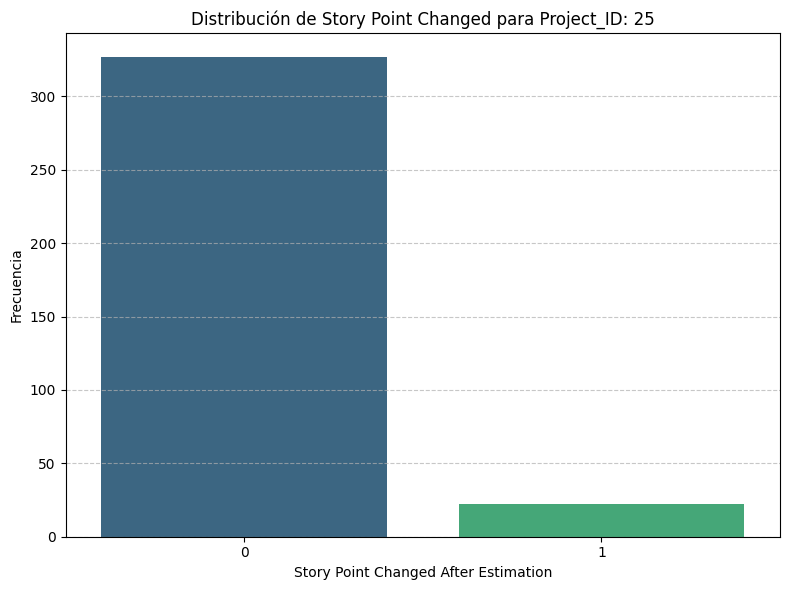

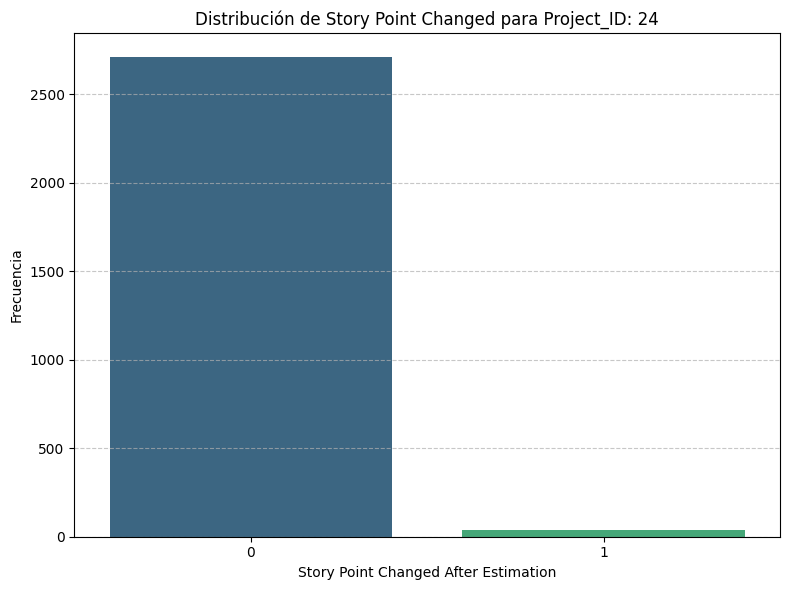

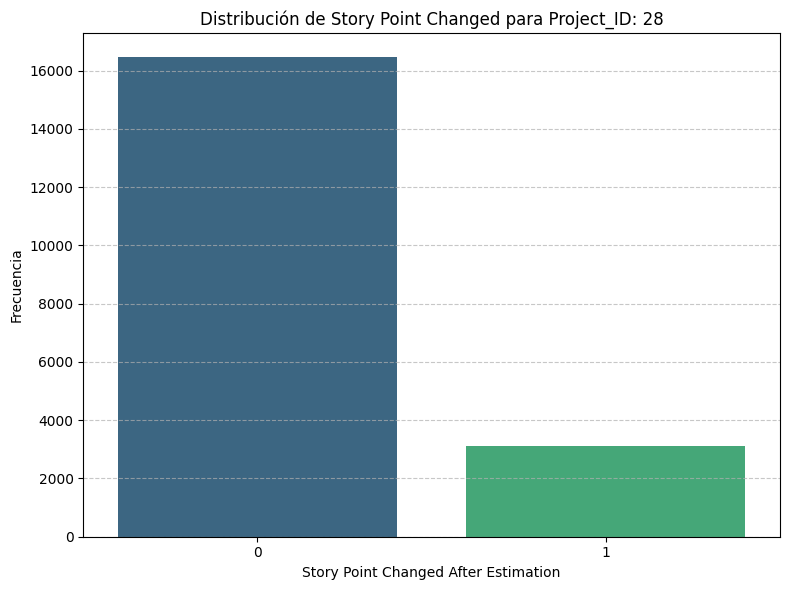

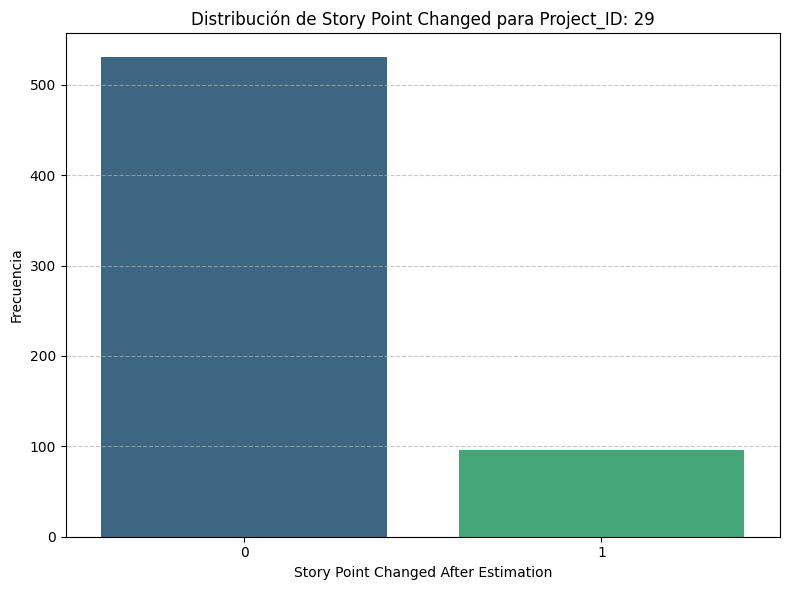

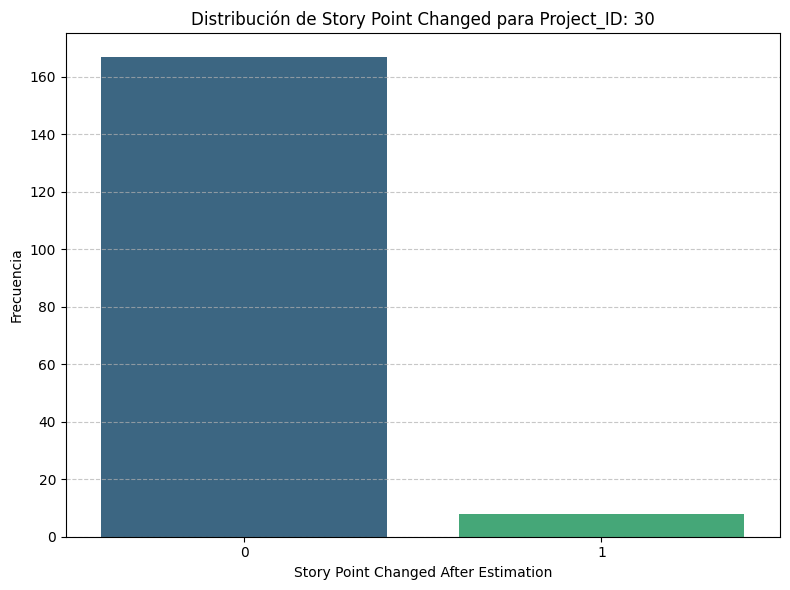

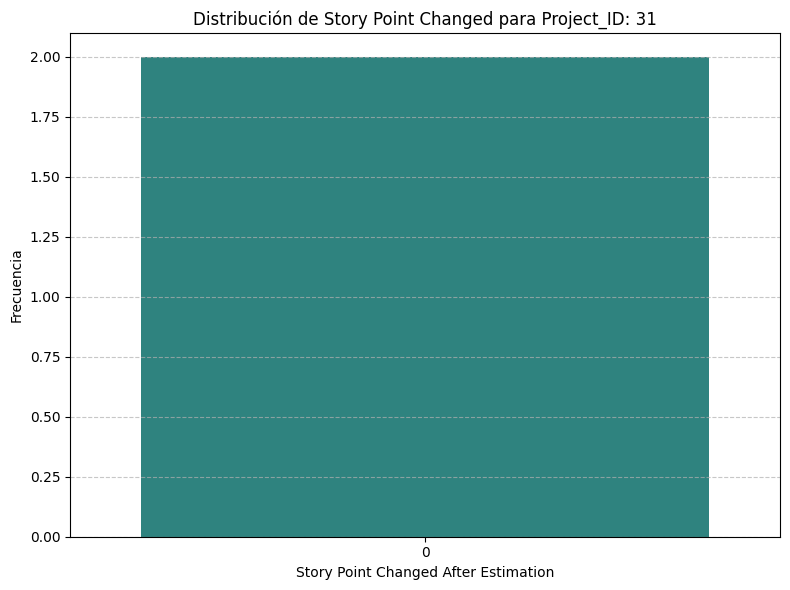

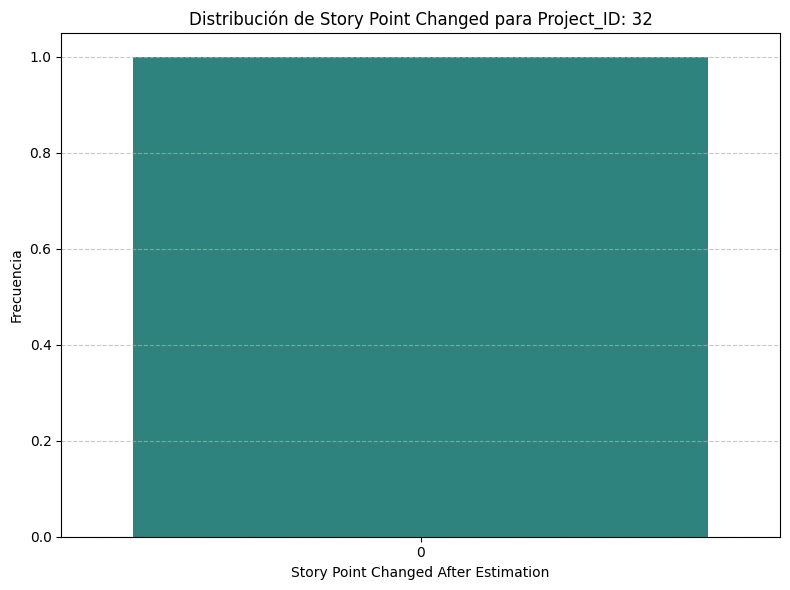

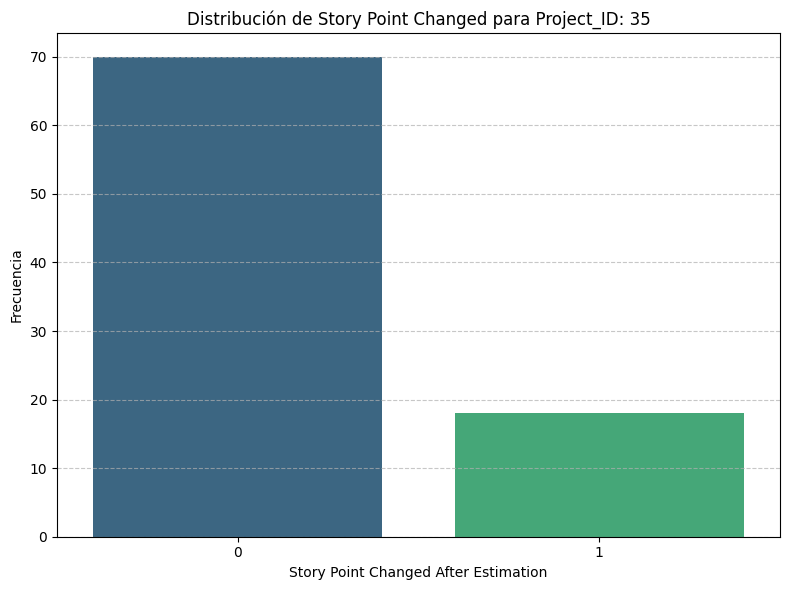

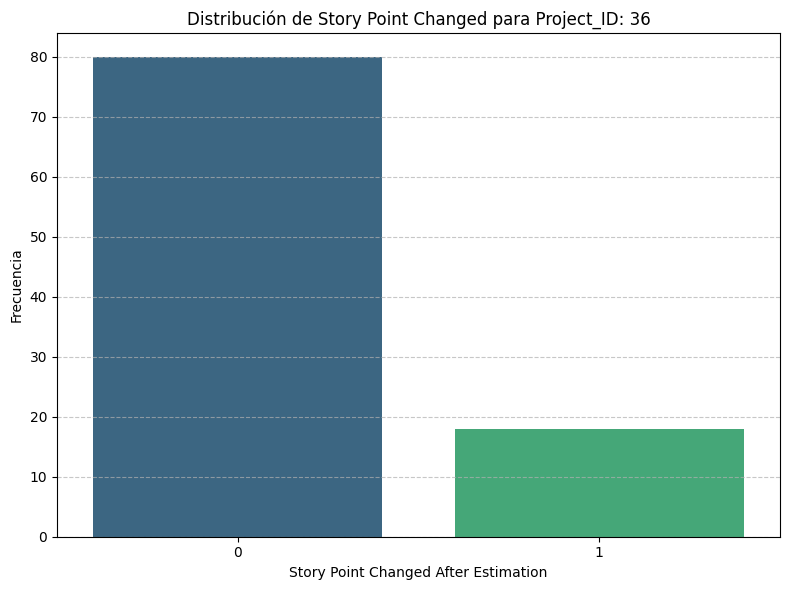

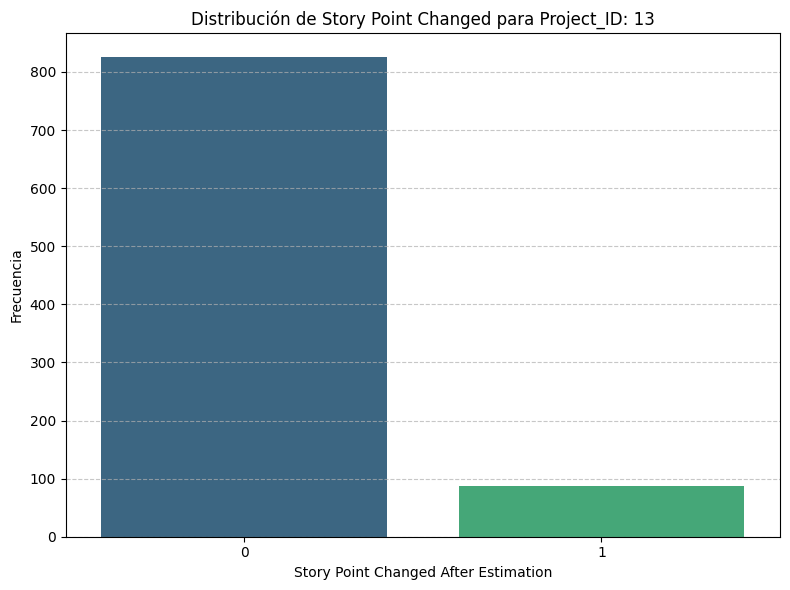

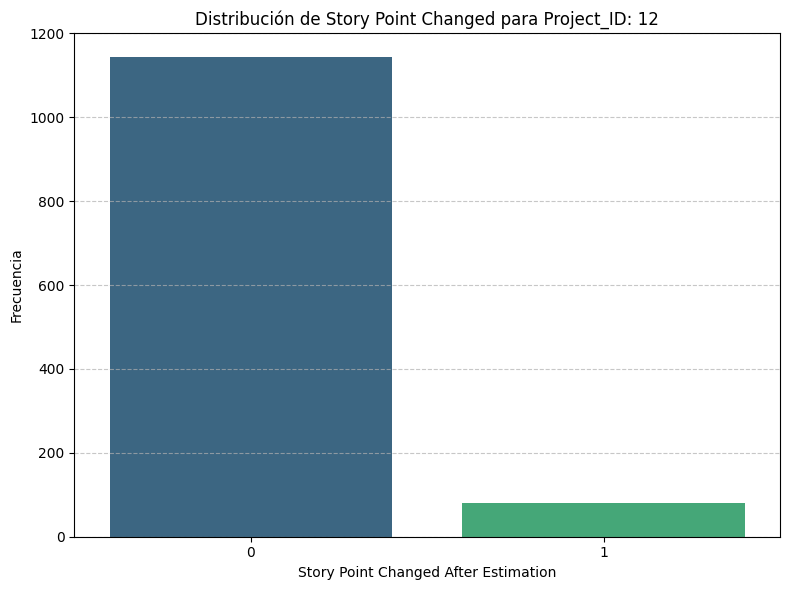

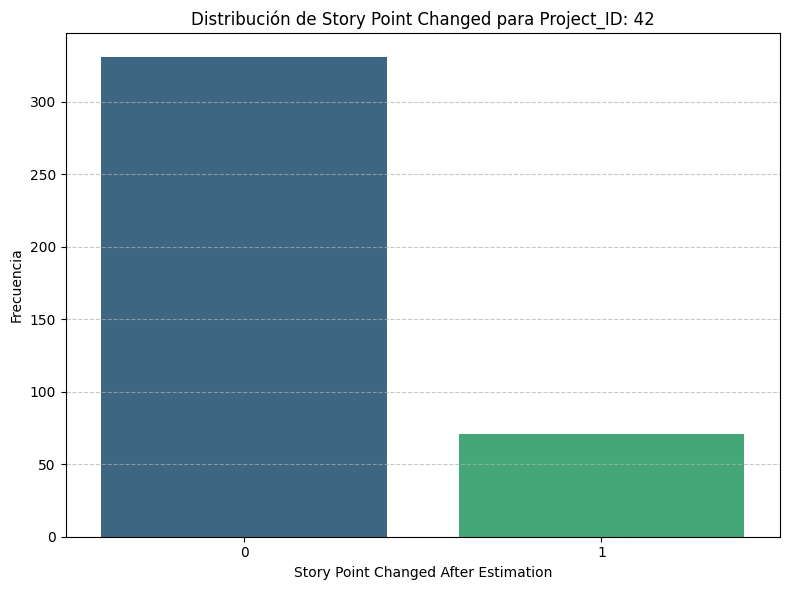

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Generando gráficos individuales de distribución de 'Story_Point_Changed_After_Estimation' por cada 'Project_ID'...")

unique_project_ids = df['Project_ID'].unique()

for project_id in unique_project_ids:
    subset_df = df[df['Project_ID'] == project_id]

    if not subset_df.empty:
        plt.figure(figsize=(8, 6))
        # Use hue and legend=False to comply with future seaborn updates
        sns.countplot(x='target', data=subset_df, palette='viridis', hue='target', legend=False)
        plt.title(f'Distribución de Story Point Changed para Project_ID: {project_id}')
        plt.xlabel('Story Point Changed After Estimation')
        plt.ylabel('Frecuencia')
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()
    else:
        print(f"No hay datos para Project_ID: {project_id}")



In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

variables = ['reporter_id', 'assignee_id', 'priority', 'project_ID']
target = 'target'

# Asegurar que existan en el df
variables_validas = [col for col in variables if col in df.columns]

resultados_cramer = []

for col in variables_validas:
  # Imputar nulos con una categoría constante para mantener la consistencia del análisis anterior
  temp_series = df[col].fillna('No especificado/Nulo').astype(str)

  # Crear tabla de contingencia
  tabla_contingencia = pd.crosstab(temp_series, df[target])

  # Calcular Chi-cuadrado
  chi2, p_val, dof, expected = chi2_contingency(tabla_contingencia)

  # Calcular V de Cramér
  n = tabla_contingencia.sum().sum()
  r, c = tabla_contingencia.shape
  v_cramer = np.sqrt(chi2 / (n * min(r - 1, c - 1)))

  resultados_cramer.append({
            'Variable': col,
            'Chi2 Stat': chi2,
            'p-valor': p_val,
            'V de Cramér': v_cramer
  })

# Crear la tabla y ordenarla una sola vez fuera del bucle
df_cramer = pd.DataFrame(resultados_cramer).sort_values(by='V de Cramér', ascending=False)

print("--- ASOCIACIÓN CON V DE CRAMÉR RESPECTO AL TARGET ---")
display(df_cramer)

--- ASOCIACIÓN CON V DE CRAMÉR RESPECTO AL TARGET ---


,Variable,Chi2 Stat,p-valor,V de Cramér
0,reporter_id,3438.296788,2.627526e-177,0.330939
1,assignee_id,2456.766958,1.502124e-220,0.279743
2,priority,465.932813,1.485623e-87,0.121826


--- ANÁLISIS DE CORRELACIÓN ENTRE STORY POINT ORIGINAL Y VARIABLE OBJETIVO ---

Estadísticas descriptivas de Story Point Original agrupado por la variable objetivo:


,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,17864.0,3.977031,4.873196,0.0,1.0,2.8,5.0,105.0
1,4136.0,6.476277,27.393569,-1.0,1.4,3.0,6.0,1010.0



Coeficiente de Correlación de Punto Biseriado: 0.0769
p-valor: 3.2806e-30
Existe una relación estadísticamente significativa (p < 0.05).


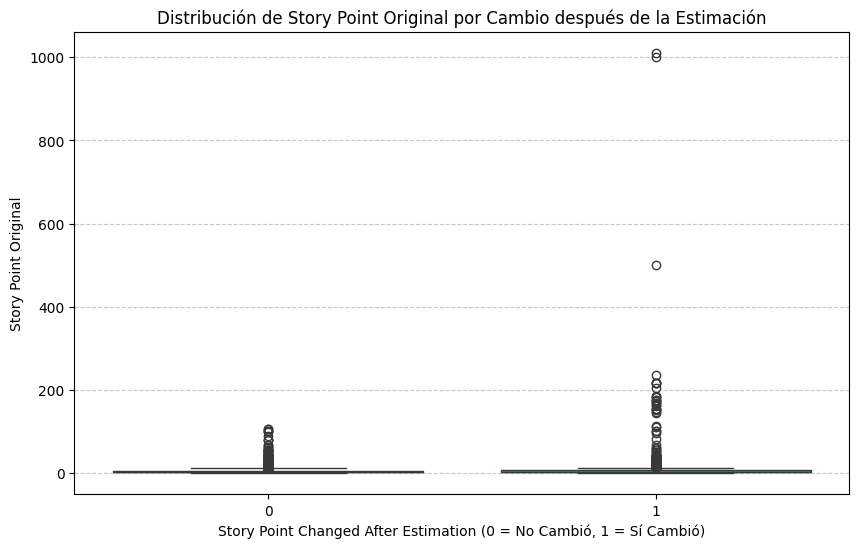

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

col_sp = 'story_point_inicial'
col_target = 'target'

print("--- ANÁLISIS DE CORRELACIÓN ENTRE STORY POINT ORIGINAL Y VARIABLE OBJETIVO ---\n")

# 1. Estadísticas descriptivas agrupadas
stats_grouped = df.groupby(col_target)[col_sp].describe()
print("Estadísticas descriptivas de Story Point Original agrupado por la variable objetivo:")
display(stats_grouped)

# 2. Correlación de Punto Biseriado
# Eliminamos nulos temporalmente en caso de que existan en estas columnas
df_clean = df[[col_sp, col_target]].dropna()

correlation, p_value = stats.pointbiserialr(df_clean[col_sp], df_clean[col_target])
print(f"\nCoeficiente de Correlación de Punto Biseriado: {correlation:.4f}")
print(f"p-valor: {p_value:.4e}")

# Interpretación
if p_value < 0.05:
  print("Existe una relación estadísticamente significativa (p < 0.05).")
else:
  print("No existe evidencia de una relación estadísticamente significativa (p >= 0.05).")

# 3. Visualización de la distribución
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x=col_target, y=col_sp, palette='viridis', hue=col_target, legend=False)
plt.title('Distribución de Story Point Original por Cambio después de la Estimación')
plt.xlabel('Story Point Changed After Estimation (0 = No Cambió, 1 = Sí Cambió)')
plt.ylabel('Story Point Original')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


In [ ]:
columns_to_keep = [
        'title',
        'description',
        'priority',
        'story_point_inicial',
        'target',
        'All_Components',
        'All_Comments',
        'assignee_id',
        'reporter_id',
        'Project_ID'

    ]
# Filter the DataFrame to keep only the specified columns
df = df[columns_to_keep]
print(f"El DataFrame ahora contiene solo las siguientes columnas: {columns_to_keep}")
print("Primeras 5 filas del DataFrame con las columnas seleccionadas:")
display(df.head())
print("Información del DataFrame actualizado:")
df.info()

El DataFrame ahora contiene solo las siguientes columnas: ['title', 'description', 'priority', 'story_point_inicial', 'target', 'All_Components', 'All_Comments', 'assignee_id', 'reporter_id', 'Project_ID']
Primeras 5 filas del DataFrame con las columnas seleccionadas:


,title,description,priority,story_point_inicial,target,All_Components,All_Comments,assignee_id,reporter_id,Project_ID
0,"""Deploy against Amazon EMR""",,Minor,NaN,0,NaN,NaN,72.0,72.0,1
1,Protect against deletion of related blob store...,"""A NXRM PM likes to ensure customers cannot de...",Major,NaN,0,NaN,NaN,NaN,472.0,3
2,"""P2 Support repository mappings""",p2 artifact repositories contain blocks which ...,Major,NaN,0,NaN,NaN,NaN,492.0,3
3,"""P2 Handle mirror.xml files""",Github issue: [https://github.com/sonatype-nex...,Major,NaN,0,NaN,NaN,NaN,492.0,3
4,"""P2 Group functionality""","""Github issue: [https://github.com/sonatype-ne...",Major,NaN,0,NaN,NaN,NaN,492.0,3


Información del DataFrame actualizado:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31394 entries, 0 to 31393
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   title                31394 non-null  object 
 1   description          30490 non-null  object 
 2   priority             31361 non-null  object 
 3   story_point_inicial  22000 non-null  float64
 4   target               31394 non-null  int64  
 5   All_Components       707 non-null    object 
 6   All_Comments         2922 non-null   object 
 7   assignee_id          21748 non-null  float64
 8   reporter_id          30524 non-null  float64
 9   Project_ID           31394 non-null  int64  
dtypes: float64(3), int64(2), object(5)
memory usage: 2.4+ MB


In [ ]:
columns_to_keep = [
        'title',
        'description',
        'priority',
        'story_point_inicial',
        'target',
        'First_Component',
        'First_Comment',
        'assignee_id',
        'reporter_id',
        'Project_ID',
        'experiencia_en_proyecto']
# Filter the DataFrame to keep only the specified columns
df = df[columns_to_keep]
print(f"El DataFrame ahora contiene solo las siguientes columnas: {columns_to_keep}")
print("Primeras 5 filas del DataFrame con las columnas seleccionadas:")
display(df.head())
print("Información del DataFrame actualizado:")
df.info()


El DataFrame ahora contiene solo las siguientes columnas: ['title', 'description', 'priority', 'story_point_inicial', 'target', 'First_Component', 'First_Comment', 'assignee_id', 'reporter_id', 'Project_ID', 'experiencia_en_proyecto']
Primeras 5 filas del DataFrame con las columnas seleccionadas:


,title,description,priority,story_point_inicial,target,First_Component,First_Comment,assignee_id,reporter_id,Project_ID,experiencia_en_proyecto
0,"""Memory-bound Space/Content iteration""","""The StorageProvider interface includes iterat...",Critical,NaN,0,NaN,NaN,NaN,146008.0,29,0.0
1,"""Meaningful response error codes needed""","""DuraStore service returns 500 error code for ...",Blocker,NaN,0,NaN,NaN,NaN,146008.0,29,0.0
2,"""ContentId / SpaceId validation library""","""May I suggest having a having a couple conven...",Minor,NaN,0,NaN,NaN,NaN,146007.0,29,0.0
3,"""Runtime configuration of duraservice & durast...","""duraservice.properties and durastore.properti...",Major,NaN,0,NaN,NaN,NaN,146007.0,29,0.0
4,"""Update Rackspace Java library""","""The Rackspace Java libraries have progressed ...",Minor,NaN,0,NaN,NaN,NaN,145992.0,29,0.0


Información del DataFrame actualizado:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31394 entries, 0 to 31393
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   title                    31394 non-null  object 
 1   description              30490 non-null  object 
 2   priority                 31361 non-null  object 
 3   story_point_inicial      22000 non-null  float64
 4   target                   31394 non-null  int64  
 5   First_Component          707 non-null    object 
 6   First_Comment            2922 non-null   object 
 7   assignee_id              21748 non-null  float64
 8   reporter_id              30524 non-null  float64
 9   Project_ID               31394 non-null  int64  
 10  experiencia_en_proyecto  31394 non-null  float64
dtypes: float64(4), int64(2), object(5)
memory usage: 2.6+ MB


Generando gráficos individuales de distribución de 'Priority' por cada 'Project_ID'...


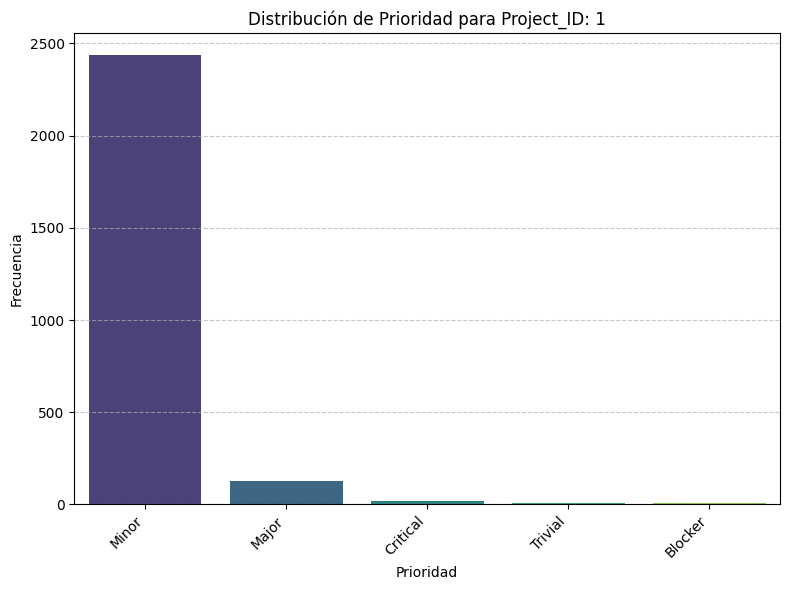

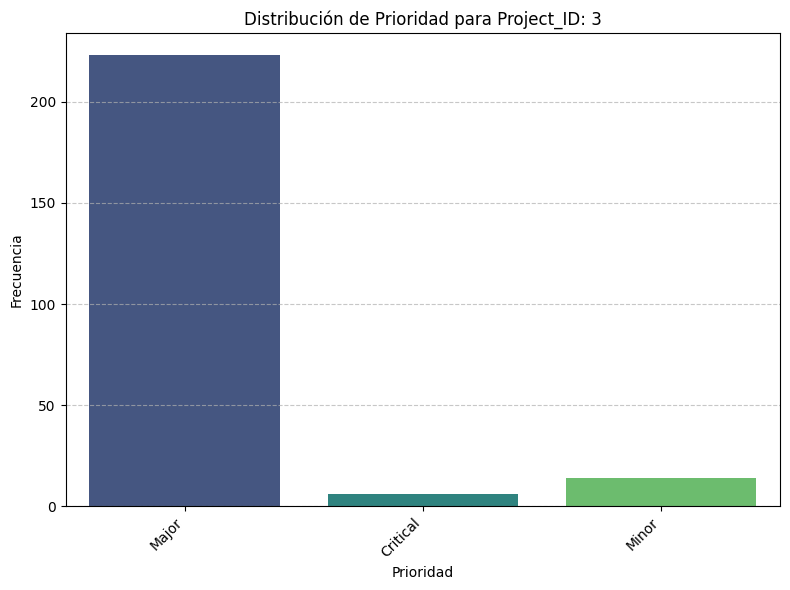

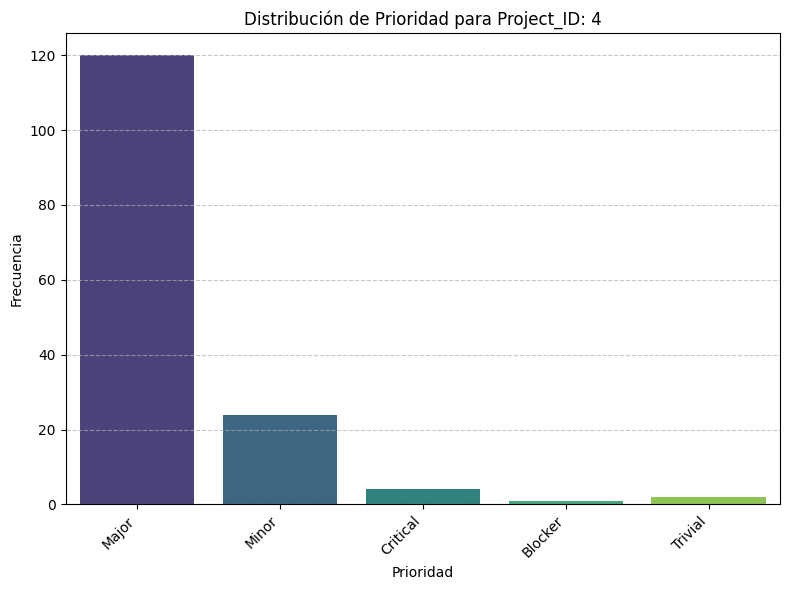

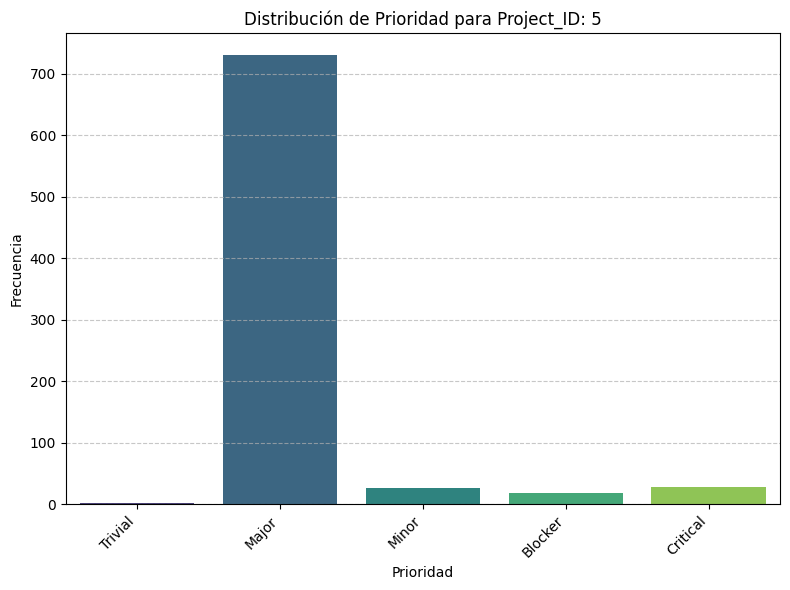

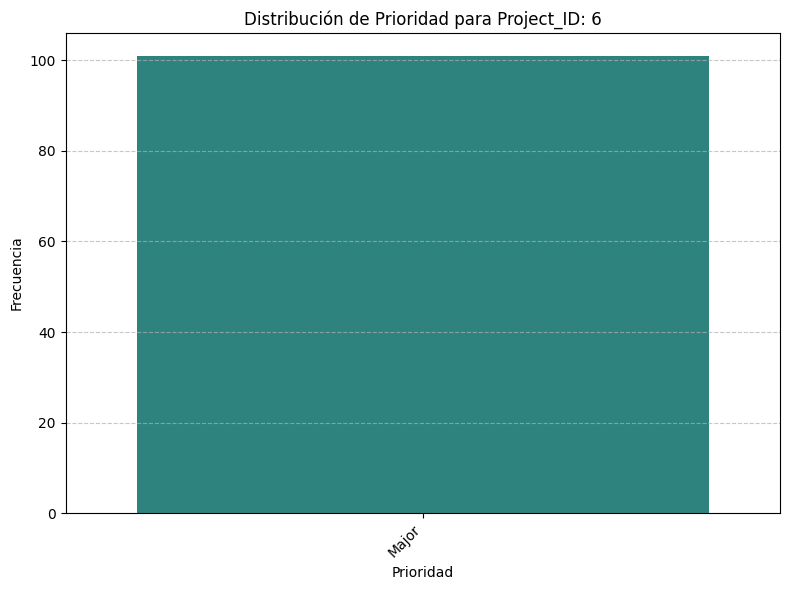

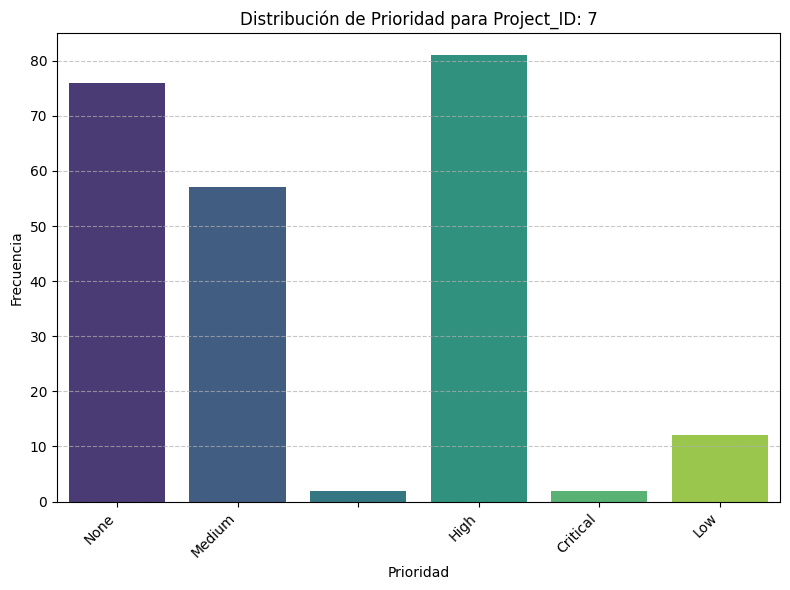

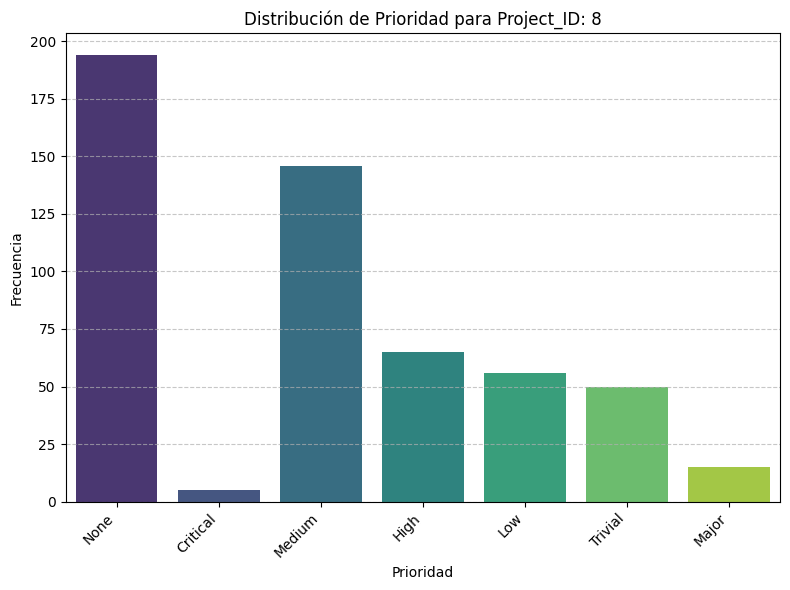

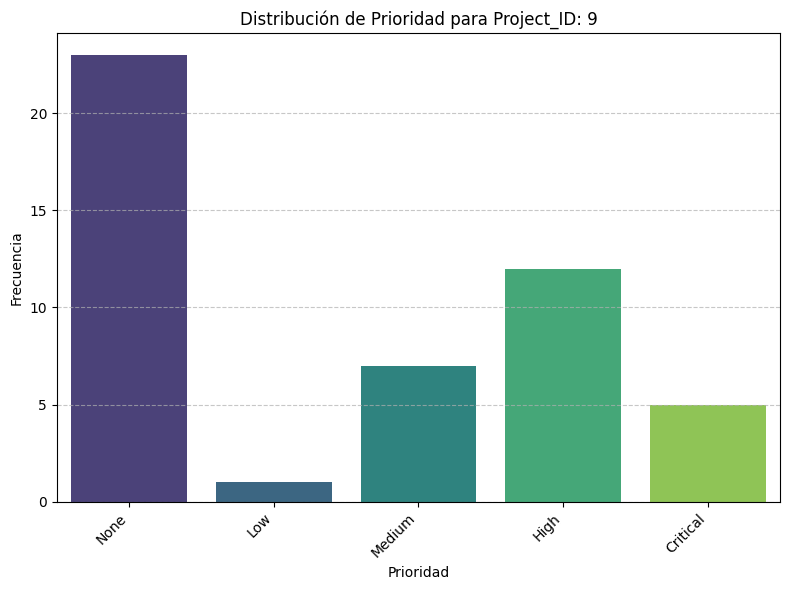

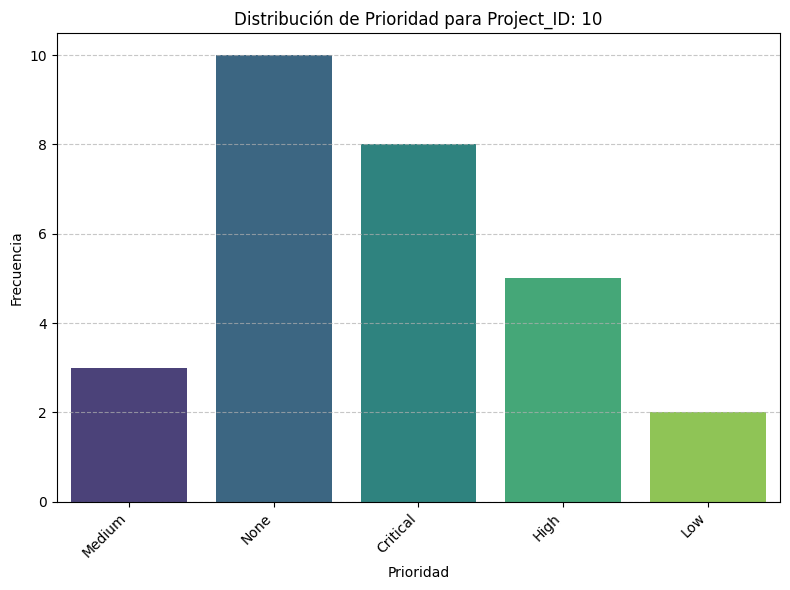

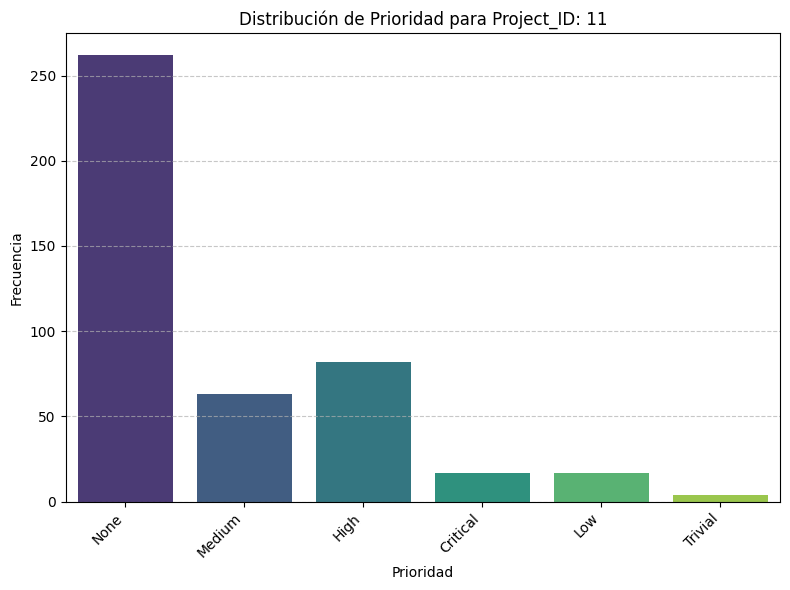

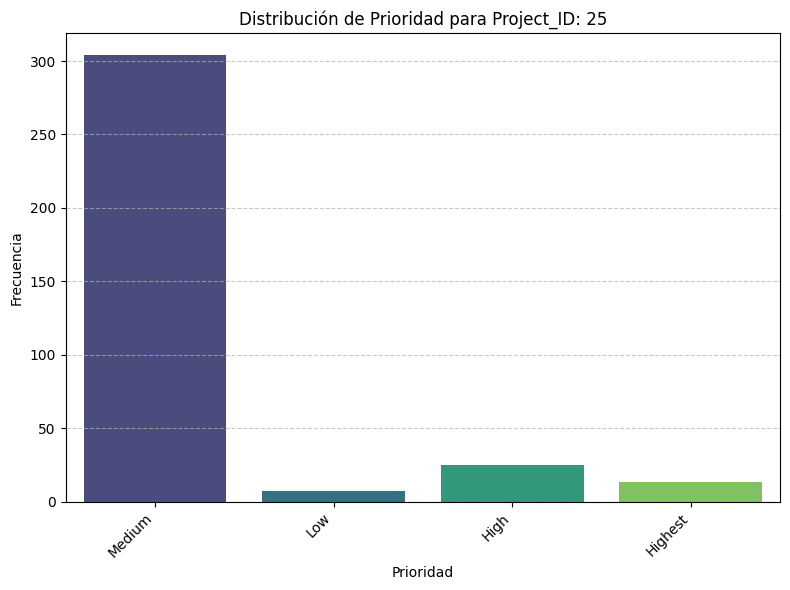

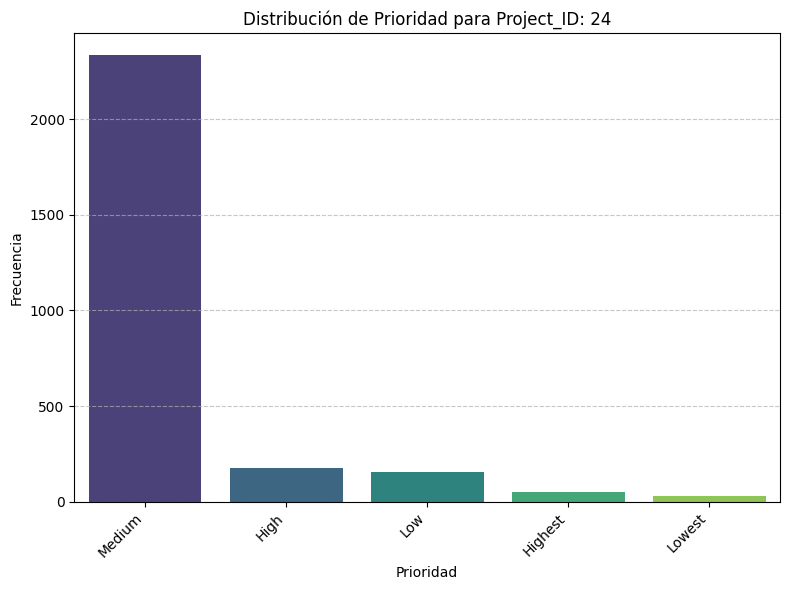

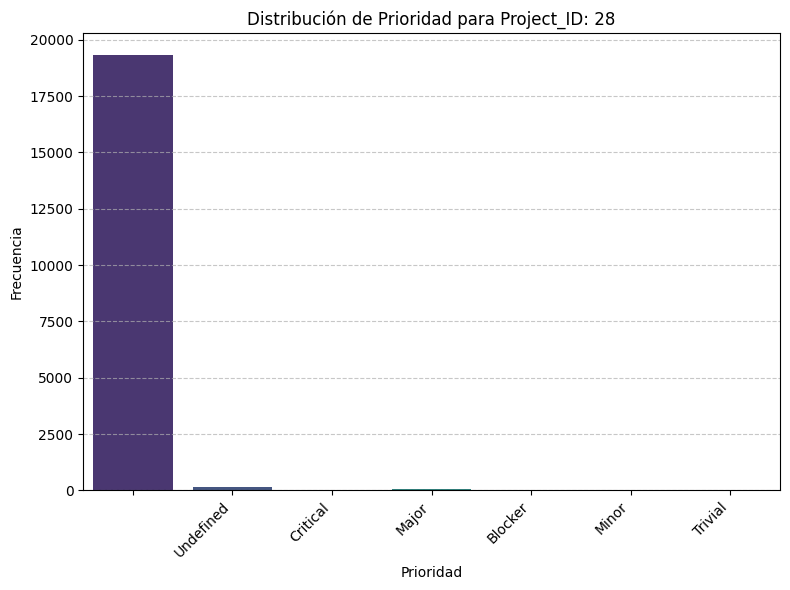

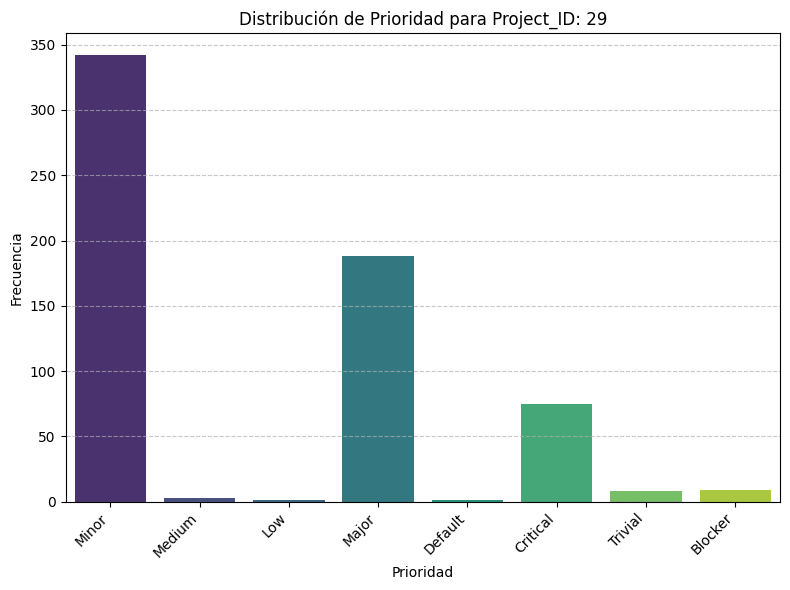

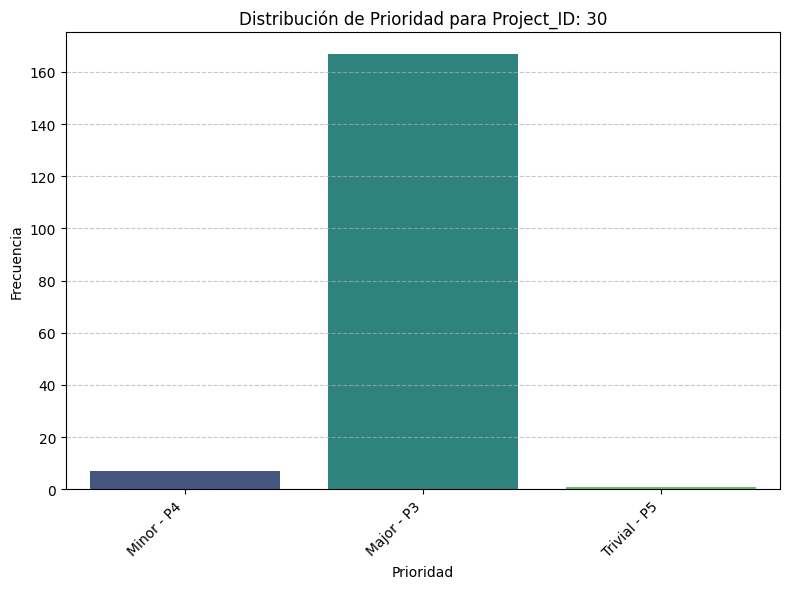

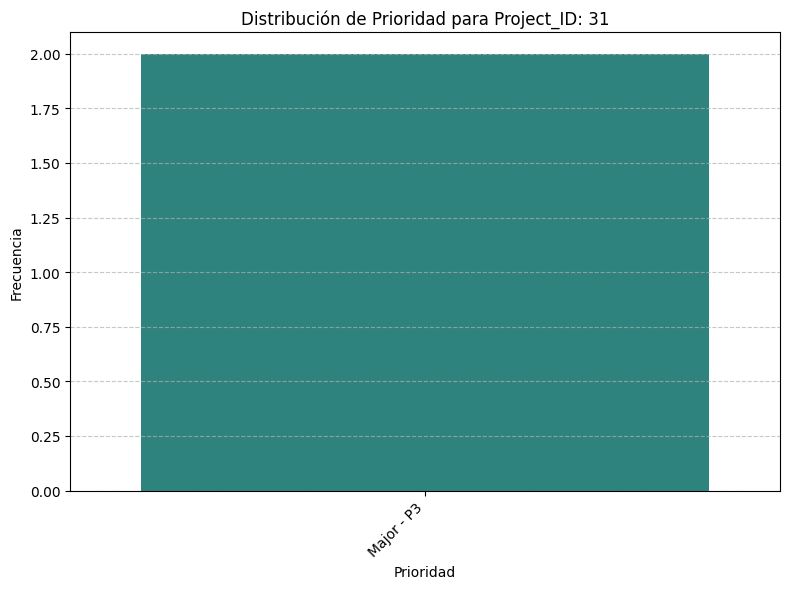

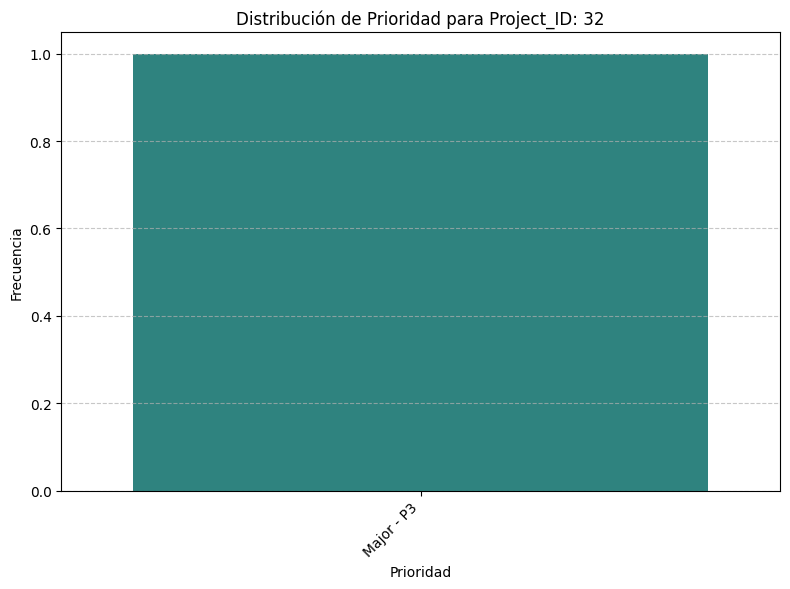

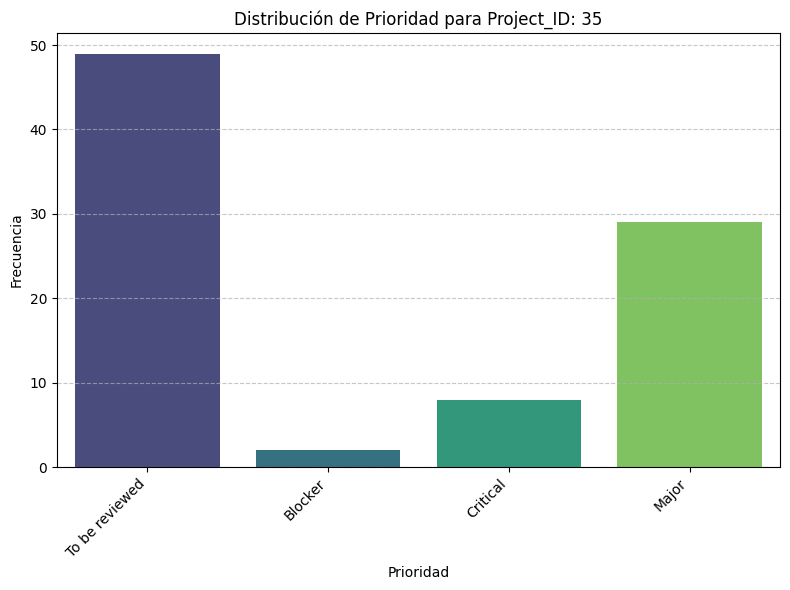

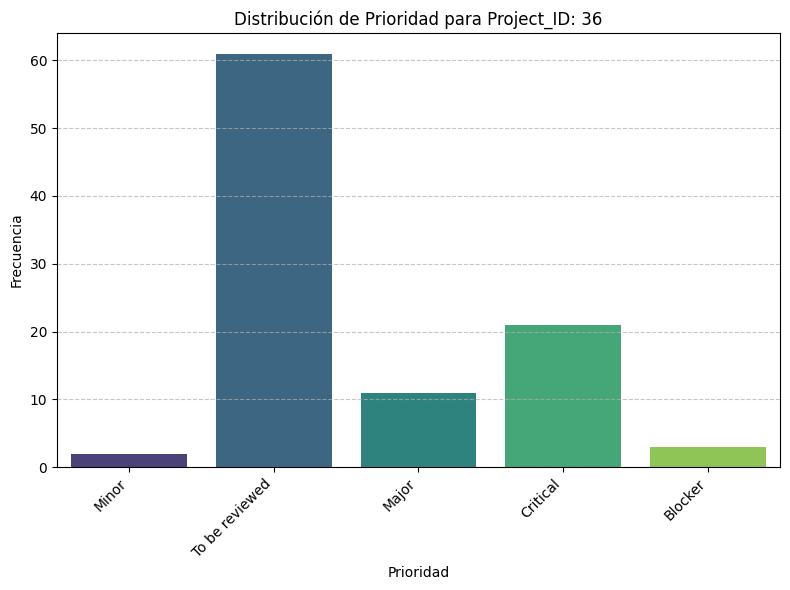

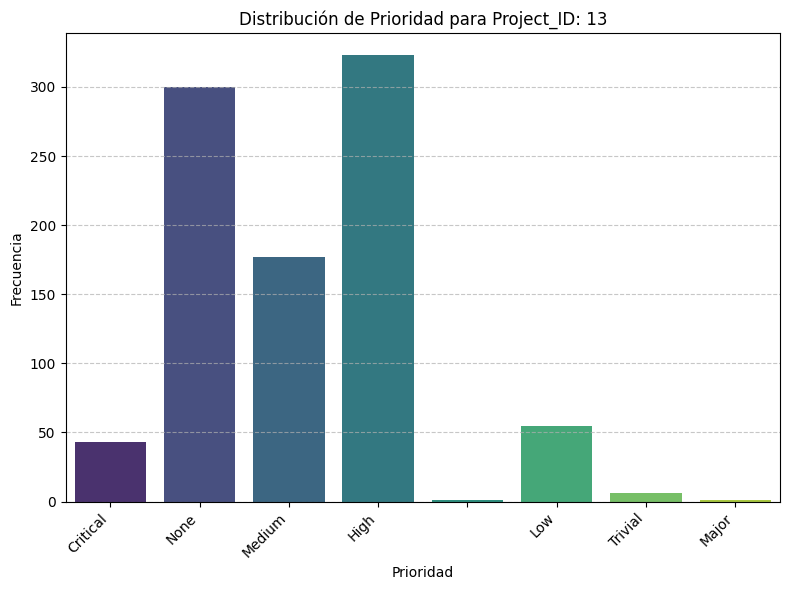

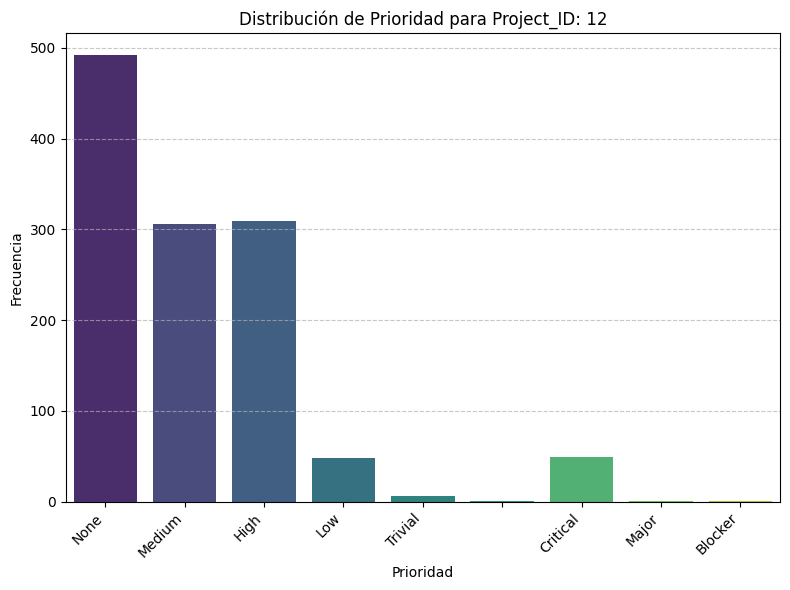

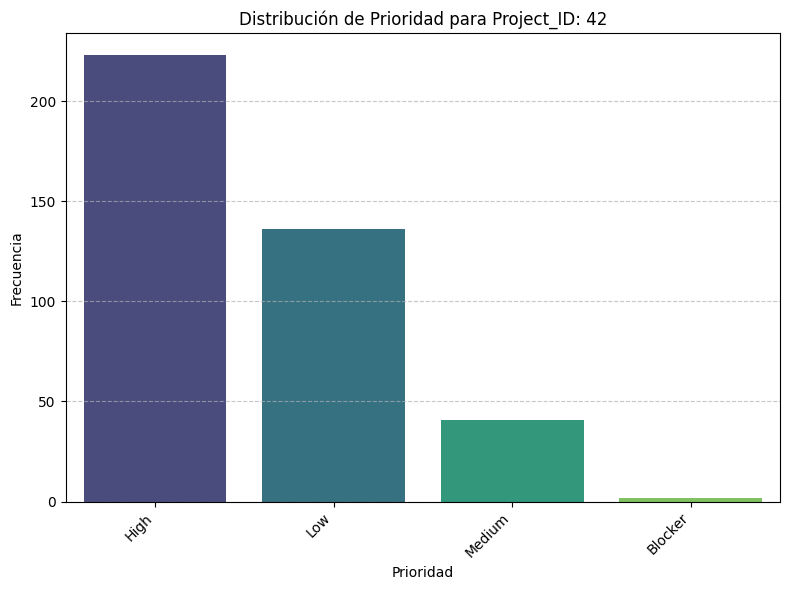

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
print("Generando gráficos individuales de distribución de 'Priority' por cada 'Project_ID'...")
unique_project_ids = df['Project_ID'].unique()

for project_id in unique_project_ids:
  subset_df = df[df['Project_ID'] == project_id]

  plt.figure(figsize=(8, 6))

  sns.countplot(x='priority', data=subset_df, palette='viridis', hue='priority', legend=False)
  plt.title(f'Distribución de Prioridad para Project_ID: {project_id}')
  plt.xlabel('Prioridad')
  plt.ylabel('Frecuencia')
  plt.xticks(rotation=45, ha='right')
  plt.grid(axis='y', linestyle='--', alpha=0.7)
  plt.tight_layout()
  plt.show()

In [ ]:
print("Consolidando 'Major - P3' en 'Major' y 'Minor - P4' en 'Minor' en la columna 'Priority'...")
# Replace 'Major - P3' with 'Major' and 'Minor - P4' with 'Minor'
df['priority'] = df['priority'].replace({
            'Major - P3': 'Major',
            'Minor - P4': 'Minor'
})
print("Consolidación completada. Mostrando el conteo de valores actualizados de 'Priority':")
display(df['priority'].value_counts(dropna=False))

Consolidando 'Major - P3' en 'Major' y 'Minor - P4' en 'Minor' en la columna 'Priority'...
Consolidación completada. Mostrando el conteo de valores actualizados de 'Priority':


,count
priority,
,15774
Minor,2684
Medium,840
Major,809
High,790
None,398
Critical,222
Low,212
Undefined,115


In [ ]:
print("Completando los valores nulos en la columna 'All_Components' con 'No Component'...")
df['All_Components'] = df['All_Components'].fillna('No Component')
print("Valores nulos en 'All_Components' completados. Mostrando el conteo de los valores más comunes:")
display(df['All_Components'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'All_Components' con 'No Component'...


KeyError: 'All_Components'

In [ ]:
print("Completando los valores nulos en la columna 'First_Component' con 'No Component'...")
df['First_Component'] = df['First_Component'].fillna('No Component')
print("Valores nulos en 'First_Component' completados. Mostrando el conteo de valores actualizado:")
display(df['First_Component'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'First_Component' con 'No Component'...
Valores nulos en 'First_Component' completados. Mostrando el conteo de valores actualizado:


,count
First_Component,
No Component,30687
Qserv,47
Documentation,22
Guides,20
Tooling,18
iOS,11
testing,11
Developer Infrastructure,11
Stack Documentation and UX,11


In [ ]:
print("Completando los valores nulos en la columna 'Priority' con 'No Priority'...")
df['priority'] = df['priority'].fillna('No Priority')
print("Valores nulos en 'Priority' completados. Mostrando el conteo de valores actualizado:")
display(df['priority'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'Priority' con 'No Priority'...
Valores nulos en 'Priority' completados. Mostrando el conteo de valores actualizado:


,count
priority,
,19341
Medium,3443
Minor,2861
Major,1616
None,1357
High,1301
Low,492
Critical,297
Major - P3,170


In [ ]:
print("Completando los valores nulos en la columna 'All_Comments' con 'No Comment'...")
df['All_Comments'] = df['All_Comments'].fillna('No Comment')
print("Valores nulos en 'All_Comments' completados. Mostrando el conteo de los valores más comunes:")
display(df['All_Comments'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'All_Comments' con 'No Comment'...
Valores nulos en 'All_Comments' completados. Mostrando el conteo de los valores más comunes:


,count
All_Comments,
No Comment,28472
Pushed to 'development' branch of ruble,14
Pushed to 'development' branch of the ruble,13
PR reviewed.,6
[~<USER> requests that we tackle this within the first couple of months of S17.,4
https://github.com/<USER>titanium_mobile_windows/pull/202,2
"This also includes efforts from [~<USER>, [~<USER>, and [~<USER>.",2
Screenshot of simulator and device icons in context,2
Merged.,2


In [ ]:
print("Completando los valores nulos en la columna 'First_Comment' con 'No Comment'...")
df['First_Comment'] = df['First_Comment'].fillna('No Comment')
print("Valores nulos en 'First_Comment' completados. Mostrando el conteo de los valores más comunes:")
display(df['First_Comment'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'First_Comment' con 'No Comment'...
Valores nulos en 'First_Comment' completados. Mostrando el conteo de los valores más comunes:


First_Comment
No Comment                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

In [ ]:
df['description'] = df['description'].fillna('No Description')
print("Valores nulos en 'Description_Estimacion_Inicial' completados. Mostrando el conteo de valores actualizado:")
display(df['description'].value_counts(dropna=False).head(10))

Valores nulos en 'Description_Estimacion_Inicial' completados. Mostrando el conteo de valores actualizado:


,count
description,
,4039
No Description,904
"""No description provided! This ticket had been created automatically Primavera ID: None""",102
"""Acceptance Criteria Needed""",26
"""Buckets for qe time tracking in JIRA""",23
No description provided!\n\nThis ticket had been created automatically\nPrimavera ID: None,16
"""h6.Reproduce Steps 1. Download any image of resolution(3264 X 2448) for testing purpose. (Attached test image) 2. Run the following example code in a default alloy app. 3. Drag the test image over to simulator. 4. Run the example app, click on the Hello World text of the application and select the testing image from the gallery. 5. Go to simulator folder, then check the saved image. For example in my test, the location is: (~/<USER>/⁨Library⁩/⁨Developer⁩/⁨CoreSimulator⁩/⁨Devices⁩/⁨9080930F-2320-4FF3-A042-D7955440EACE⁩/⁨data⁩/⁨Containers⁩/Data/⁨Application⁩/8D3292C5-4578-4B59-8956-29C36AB23BFF⁩/Documents⁩) h6.Problem Open the image, you will see the resolution is only 3073 X 2305 and it get cropped at right side and bottom side. h6.Expect The image should not get cropped.""",15
"""Collect, record, and verify financial data for the LSST Data Facility. Deliverable consists of a monthly financial report delivered to the Project Controls Specialist.""",14
"""See Summary""",13


### 7. Manejo de Outliers en 'Story_Point_Original' (Z-score)


In [ ]:
import numpy as np

# Eliminar Story Points negativos
df = df[df['story_point_inicial'] >= 0].copy()

# Z-score por proyecto
z_score_threshold = 3

media = df.groupby('Project_ID')['story_point_inicial'].transform('mean')
std = df.groupby('Project_ID')['story_point_inicial'].transform('std')

std = std.replace(0, np.nan)

z_scores = (
    (df['story_point_inicial'] - media) / std
)

mask_outlier = z_scores.abs() > z_score_threshold
mask_outlier = mask_outlier.fillna(False)

print(f"Outliers eliminados: {mask_outlier.sum()}")

df = df.loc[~mask_outlier].copy()

print("Forma final:", df.shape)

Outliers eliminados: 137
Forma final: (21862, 11)


### 7. Manejo de Outliers en 'Story_Point_Original' (elimina negativos y nulos)

In [ ]:
if 'df' in locals() and df is not None:
    # Registrar tamaño antes de filtrar
    initial_shape = df.shape[0]

    # Filtrar eliminando valores negativos de story_point_inicial
    df = df[df['story_point_inicial'] >= 0].copy()

    final_shape = df.shape[0]
    print(f"Filas iniciales: {initial_shape}")
    print(f"Filas tras eliminar Story Points negativos: {final_shape}")
    print(f"Valores eliminados: {initial_shape - final_shape}")
else:
    print("El DataFrame 'df' no está definido en el entorno.")

Filas iniciales: 31394
Filas tras eliminar Story Points negativos: 21999
Valores eliminados: 9395


### 7. Manejo de Outliers completando con la mediana


In [ ]:
import numpy as np
import pandas as pd

if 'df' in locals() and df is not None:
    print(f"Estado inicial del DataFrame: {df.shape[0]} filas.")
    print(f"Nulos iniciales en SP: {df['story_point_inicial'].isnull().sum()}")

    # 1. Convertir valores negativos a NaN
    negativos_mask = df['story_point_inicial'] < 0
    num_negativos = negativos_mask.sum()
    df.loc[negativos_mask, 'story_point_inicial'] = np.nan
    print(f"Valores negativos convertidos a NaN: {num_negativos}")

    # 2. Identificar y reemplazar outliers por proyecto usando Z-score robusto o IQR
    # Usaremos el método IQR (Rango Intercuartílico) por cada Project_ID para identificar outliers
    def replace_outliers_with_nan(group):
        q1 = group.quantile(0.25)
        q3 = group.quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        # Marcar como NaN los valores fuera de los límites (solo si no son nulos de por sí)
        is_outlier = (group < lower_bound) | (group > upper_bound)
        group[is_outlier] = np.nan
        return group

    # Aplicar la función de outliers por proyecto
    sp_antes_outliers_nulos = df['story_point_inicial'].isnull().sum()
    df['story_point_inicial'] = df.groupby('Project_ID')['story_point_inicial'].transform(replace_outliers_with_nan)
    sp_despues_outliers_nulos = df['story_point_inicial'].isnull().sum()
    print(f"Outliers detectados por proyecto y convertidos a NaN: {sp_despues_outliers_nulos - sp_antes_outliers_nulos}")

    # 3. Imputar todos los NaN (faltantes, negativos y outliers) con la mediana de su respectivo Project_ID
    df['story_point_inicial'] = df.groupby('Project_ID')['story_point_inicial'].transform(lambda x: x.fillna(x.median()))

    # Si aún quedasen nulos debido a proyectos sin ningún SP válido, imputar con la mediana global
    global_median = df['story_point_inicial'].median()
    nulos_restantes = df['story_point_inicial'].isnull().sum()
    if nulos_restantes > 0:
        df['story_point_inicial'] = df['story_point_inicial'].fillna(global_median)
        print(f"Se imputaron {nulos_restantes} valores restantes usando la mediana global ({global_median})")

    print(f"Nulos finales en la columna 'story_point_inicial': {df['story_point_inicial'].isnull().sum()}")
    display(df['story_point_inicial'].describe())
else:
    print("El DataFrame 'df' no está disponible en el entorno.")

Estado inicial del DataFrame: 31394 filas.
Nulos iniciales en SP: 9394
Valores negativos convertidos a NaN: 1
Outliers detectados por proyecto y convertidos a NaN: 1230
Se imputaron 3 valores restantes usando la mediana global (2.0)
Nulos finales en la columna 'story_point_inicial': 0


,story_point_inicial
count,31394.000000
mean,3.062380
std,2.355971
min,0.000000
25%,2.000000
50%,2.000000
75%,4.000000
max,34.000000


### 7. Manejo de Outliers en 'Story_Point_Original' completando nulos


In [ ]:
print("Imputando los valores nulos de 'story_point_inicial' con la mediana de su respectivo 'Project_ID'...")
df['story_point_inicial'] = df.groupby('Project_ID')['story_point_inicial'].transform(lambda x: x.fillna(x.median()))

# Si aún quedan nulos debido a proyectos sin ningún valor de SP registrado, completamos con la mediana global
global_median = df['story_point_inicial'].median()
df['story_point_inicial'] = df['story_point_inicial'].fillna(global_median)

print("Valores nulos en 'story_point_inicial' completados exitosamente.")
print(f"Nulos restantes en la columna: {df['story_point_inicial'].isnull().sum()}")
display(df['story_point_inicial'].describe())

Imputando los valores nulos de 'story_point_inicial' con la mediana de su respectivo 'Project_ID'...
Valores nulos en 'story_point_inicial' completados exitosamente.
Nulos restantes en la columna: 0


,story_point_inicial
count,31394.000000
mean,3.903742
std,10.683004
min,-1.000000
25%,2.000000
50%,2.000000
75%,5.000000
max,1010.000000


In [ ]:
print("Completando los valores nulos en la columna 'reporter_id' con -1.0...")
df['reporter_id'] = df['reporter_id'].fillna(-1.0)
print("Valores nulos en 'reporter_id' completados exitosamente.")
print(f"Nulos restantes en 'reporter_id': {df['reporter_id'].isnull().sum()}")
display(df['reporter_id'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'reporter_id' con -1.0...
Valores nulos en 'reporter_id' completados exitosamente.
Nulos restantes en 'reporter_id': 0


,count
reporter_id,
145778.0,854
145726.0,766
145807.0,741
78.0,595
145874.0,566
72.0,553
-1.0,507
145769.0,490
145720.0,475


# Componente, comentario, prioridad, reporter, sp, sin texto

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score, balanced_accuracy_score
import warnings
warnings.filterwarnings('ignore')

if 'df' in locals() and df is not None:
    # 1. Definir la variable objetivo
    y = df['target'].astype(int)

    # 2. Crear una copia de los datos y asegurar el formato de First_Component y First_Comment
    df_model = df.copy()

    # Asegurar que existan estas columnas o recuperarlas si no están presentes
    if 'First_Component' not in df_model.columns and 'df_first_component' in locals():
        df_model = df_model.merge(df_first_component, left_on='ID', right_on='issue_id', how='left').drop(columns=['issue_id'], errors='ignore')
    if 'First_Comment' not in df_model.columns and 'df_first_comment' in locals():
        df_model = df_model.merge(df_first_comment, left_on='ID', right_on='issue_id', how='left').drop(columns=['issue_id'], errors='ignore')

    df_model['First_Component'] = df_model['First_Component'].fillna('No Component').astype(str)
    df_model['First_Comment'] = df_model['First_Comment'].fillna('No Comment').astype(str)

    # Llenar nulos en 'priority' y 'reporter_id'
    df_model['priority'] = df_model['priority'].fillna('No Priority')
    df_model['reporter_id'] = df_model['reporter_id'].fillna('No Reporter').astype(str)

    # 3. Definir características numéricas, categóricas y de texto (sin title ni description)
    numerical_features = [
        'story_point_inicial',
    ]
    categorical_features = [
        'priority',
        'reporter_id'
    ]

    components_text_col = 'First_Component'
    comments_text_col = 'First_Comment'

    # Combinar características seleccionadas en X
    features_to_use = numerical_features + categorical_features + [components_text_col] + [comments_text_col]
    X = df_model[features_to_use]

    # 4. Dividir los datos en set de entrenamiento y prueba
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )

    print("Forma de los datos después de la división:")
    print(f"X_train_raw: {X_train_raw.shape}, X_test_raw: {X_test_raw.shape}")
    print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

    # 5. Preprocesamiento usando ColumnTransformer (sin title ni description)
    preprocessor = ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=True), categorical_features),
            ('text_tfidf_components', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=1, max_df=0.95, ngram_range=(1, 1), max_features=1000), components_text_col),
            ('text_tfidf_comments', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=2, max_df=0.95, ngram_range=(1, 2), max_features=5000), comments_text_col)
        ],
        remainder='passthrough',
        verbose_feature_names_out=False
    )

    # Ajustar y transformar
    X_train = preprocessor.fit_transform(X_train_raw)
    X_test = preprocessor.transform(X_test_raw)

    print("\nDimensiones de las características transformadas:")
    print(f"X_train: {X_train.shape}")
    print(f"X_test: {X_test.shape}")

    # Función para mostrar los resultados
    def mostrar_resultados(y_true, y_pred_values, y_pred_proba=None):
        LABELS = sorted(y_true.unique().astype(str))
        conf_matrix = confusion_matrix(y_true, y_pred_values)
        plt.figure(figsize=(12, 12))
        ax = sns.heatmap(conf_matrix, xticklabels=LABELS, yticklabels=LABELS, annot=True, fmt="d",
                    annot_kws={"size": 20})
        ax.tick_params(axis='x', labelsize=18)
        ax.tick_params(axis='y', labelsize=18)
        plt.title("Confusion matrix")
        plt.ylabel("True class", fontsize=22)
        plt.xlabel("Predicted class", fontsize=22)
        plt.show()
        print(classification_report(y_true, y_pred_values))

        balanced_acc = balanced_accuracy_score(y_true, y_pred_values)
        print(f"Balanced Accuracy: {balanced_acc:.4f}")

        if y_pred_proba is not None:
            avg_precision = average_precision_score(y_true, y_pred_proba)
            roc_auc = roc_auc_score(y_true, y_pred_proba)
            print(f"Average Precision (PR-AUC): {avg_precision:.4f}")
            print(f"ROC AUC: {roc_auc:.4f}")
            print("\nPrimeras 10 predicciones - Real vs Predicha vs Probabilidad:")
            sample_df = pd.DataFrame({
                'Real': y_true.reset_index(drop=True).head(10),
                'Predicha': pd.Series(y_pred_values).head(10),
                'Probabilidad': pd.Series(y_pred_proba).head(10)
            })
            display(sample_df)

else:
    print("El DataFrame 'df' no está disponible o no se cargó correctamente.")

Forma de los datos después de la división:
X_train_raw: (17599, 5), X_test_raw: (4400, 5)
y_train: (17599,), y_test: (4400,)

Dimensiones de las características transformadas:
X_train: (17599, 5799)
X_test: (4400, 5799)


# Componentes, comentarios, prioridad, reporter, sp, con texto

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score, balanced_accuracy_score
import warnings
warnings.filterwarnings('ignore') # Suppress warnings, especially from scikit-learn about convergence

if 'df' in locals() and df is not None:
    # 1. Definir la variable objetivo
    y = df['target'].astype(int)

    # 2. Crear la característica de texto combinado en una copia del DataFrame para X
    df_model = df.copy()
    df_model['Texto_Combinado'] = (
        df_model['title'].fillna('') + ' ' +
        df_model['description'].fillna('')
    )
    # Asegurar que componentes y comentarios estén como strings limpios
    df_model['All_Components'] = df_model['All_Components'].fillna('').astype(str)
    df_model['All_Comments'] = df_model['All_Comments'].fillna('').astype(str)

    # Fill NaN in 'Priority' with 'No Priority'
    df_model['priority'] = df_model['priority'].fillna('No Priority')

    # Fill NaN in 'reporter_id' with 'No Reporter' and convert to string to prevent numerical treatment
    df_model['reporter_id'] = df_model['reporter_id'].fillna('No Reporter').astype(str)

    # 3. Definir características numéricas, categóricas y de texto
    numerical_features = [
        'story_point_inicial',
    ]
    categorical_features = [
        'priority',
        'reporter_id'
    ]

    text_feature_col = 'Texto_Combinado'
    components_text_col = 'All_Components'
    comments_text_col = 'All_Comments'

    # Combinar todas las características en un solo DataFrame para X
    features_to_use = numerical_features + categorical_features + [text_feature_col] + [components_text_col] + [comments_text_col]
    X = df_model[features_to_use]

    # 4. Dividir los datos en sets de entrenamiento y test
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )

    print("Forma de los datos después de la división:")
    print(f"X_train_raw: {X_train_raw.shape}, X_test_raw: {X_test_raw.shape}")
    print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

    # 5. Preprocesamiento usando ColumnTransformer incluyendo componentes y comentarios independientes
    preprocessor = ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=True), categorical_features),
            ('text_tfidf_desc_title', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=3, max_df=0.95, ngram_range=(1, 2), max_features=10000), text_feature_col),
            ('text_tfidf_components', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=1, max_df=0.95, ngram_range=(1, 1), max_features=1000), components_text_col),
            ('text_tfidf_comments', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=2, max_df=0.95, ngram_range=(1, 2), max_features=5000), comments_text_col)
        ],
        remainder='passthrough',
        verbose_feature_names_out=False
    )

    # Fit and transform on training data, transform on test data
    X_train = preprocessor.fit_transform(X_train_raw)
    X_test = preprocessor.transform(X_test_raw)

    print("\nDimensiones de las características transformadas:")
    print(f"X_train: {X_train.shape}")
    print(f"X_test: {X_test.shape}")

    # Función para mostrar los resultados
    def mostrar_resultados(y_true, y_pred_values, y_pred_proba=None):
        LABELS = sorted(y_true.unique().astype(str))
        conf_matrix = confusion_matrix(y_true, y_pred_values)
        plt.figure(figsize=(12, 12))
        ax = sns.heatmap(conf_matrix, xticklabels=LABELS, yticklabels=LABELS, annot=True, fmt="d",
                    annot_kws={"size": 20})
        ax.tick_params(axis='x', labelsize=18)
        ax.tick_params(axis='y', labelsize=18)
        plt.title("Confusion matrix")
        plt.ylabel("True class", fontsize=22)
        plt.xlabel("Predicted class", fontsize=22)
        plt.show()
        print(classification_report(y_true, y_pred_values))

        balanced_acc = balanced_accuracy_score(y_true, y_pred_values)
        print(f"Balanced Accuracy: {balanced_acc:.4f}")

        if y_pred_proba is not None:
            avg_precision = average_precision_score(y_true, y_pred_proba)
            roc_auc = roc_auc_score(y_true, y_pred_proba)
            print(f"Average Precision (PR-AUC): {avg_precision:.4f}")
            print(f"ROC AUC: {roc_auc:.4f}")
            print("\nPrimeras 10 predicciones - Real vs Predicha vs Probabilidad:")
            sample_df = pd.DataFrame({
                'Real': y_true.reset_index(drop=True).head(10),
                'Predicha': pd.Series(y_pred_values).head(10),
                'Probabilidad': pd.Series(y_pred_proba).head(10)
            })
            display(sample_df)

else:
    print("El DataFrame 'df' no está disponible o no se cargó correctamente.")

Forma de los datos después de la división:
X_train_raw: (17599, 6), X_test_raw: (4400, 6)
y_train: (17599,), y_test: (4400,)

Dimensiones de las características transformadas:
X_train: (17599, 15851)
X_test: (4400, 15851)


# Componente, prioridad, reporter, sp,exp

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score, balanced_accuracy_score
import warnings
warnings.filterwarnings('ignore') # Suppress warnings, especially from scikit-learn about convergence

if 'df' in locals() and df is not None:
    # 1. Definir la variable objetivo
    y = df['target'].astype(int)

    # 2. Crear la característica de texto combinado en una copia del DataFrame para X
    df_model = df.copy()
    df_model['Texto_Combinado'] = (
        df_model['title'].fillna('') + ' ' +
        df_model['description'].fillna('')
    )
    # Ensure 'Components_Lista' is treated as a string for TfidfVectorizer
    df_model['First_Component'] = df_model['First_Component'].fillna('').astype(str)

    # Fill NaN in 'Priority' with 'No Priority'
    df_model['priority'] = df_model['priority'].fillna('No Priority')

    # Fill NaN in 'reporter_id' with 'No Reporter' and convert to string to prevent numerical treatment
    df_model['reporter_id'] = df_model['reporter_id'].fillna('No Reporter').astype(str)

    # Asegurar que 'experiencia_en_proyecto' no contenga nulos
    df_model['experiencia_en_proyecto'] = df_model['experiencia_en_proyecto'].fillna(0)

    # 3. Definir características numéricas, categóricas y de texto
    # Se incorpora 'experiencia_en_proyecto' en las características numéricas
    numerical_features = [
        'story_point_inicial',
        'experiencia_en_proyecto'
    ]
    categorical_features = [
        'priority',
        'reporter_id' # Incorporated reporter
    ]

    text_feature_col = 'Texto_Combinado'
    components_text_col = 'First_Component' # New text feature for components

    # Combinar todas las características en un solo DataFrame para X
    features_to_use = numerical_features + categorical_features + [text_feature_col] + [components_text_col] # Updated features
    X = df_model[features_to_use]

    # 4. Dividir los datos en sets de entrenamiento y test
    # Usamos test_size=0.20 y stratify=y para consistencia con el modelo previo
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )

    print("Forma de los datos después de la división:")
    print(f"X_train_raw: {X_train_raw.shape}, X_test_raw: {X_test_raw.shape}")
    print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

    # 5. Preprocesamiento usando ColumnTransformer
    # Aplicamos StandardScaler a las variables numéricas (incluyendo experiencia_en_proyecto)
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=True), categorical_features),
            ('text_tfidf_desc_title', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=3, max_df=0.95, ngram_range=(1, 2), max_features=10000), text_feature_col),
            ('text_tfidf_components', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=1, max_df=0.95, ngram_range=(1, 1), max_features=1000), components_text_col) # Added for components
        ],
        remainder='passthrough',
        verbose_feature_names_out=False
    )

    # Fit and transform on training data, transform on test data
    X_train = preprocessor.fit_transform(X_train_raw)
    X_test = preprocessor.transform(X_test_raw)

    print("\nDimensiones de las características transformadas:")
    print(f"X_train: {X_train.shape}")
    print(f"X_test: {X_test.shape}")

    # Función para mostrar los resultados
    def mostrar_resultados(y_true, y_pred_values, y_pred_proba=None):
        LABELS = sorted(y_true.unique().astype(str))
        conf_matrix = confusion_matrix(y_true, y_pred_values)
        plt.figure(figsize=(12, 12))
        # Increased font size for annotations and tick labels
        ax = sns.heatmap(conf_matrix, xticklabels=LABELS, yticklabels=LABELS, annot=True, fmt="d",
                    annot_kws={"size": 20})
        ax.tick_params(axis='x', labelsize=18)
        ax.tick_params(axis='y', labelsize=18)
        plt.title("Confusion matrix")
        plt.ylabel("True class", fontsize=22)
        plt.xlabel("Predicted class", fontsize=22)
        plt.show()
        print(classification_report(y_true, y_pred_values))

        balanced_acc = balanced_accuracy_score(y_true, y_pred_values)
        print(f"Balanced Accuracy: {balanced_acc:.4f}")

        if y_pred_proba is not None:
            avg_precision = average_precision_score(y_true, y_pred_proba)
            roc_auc = roc_auc_score(y_true, y_pred_proba)
            print(f"Average Precision (PR-AUC): {avg_precision:.4f}")
            print(f"ROC AUC: {roc_auc:.4f}")
            print("\nPrimeras 10 predicciones - Real vs Predicha vs Probabilidad:")
            sample_df = pd.DataFrame({
                'Real': y_true.reset_index(drop=True).head(10),
                'Predicha': pd.Series(y_pred_values).head(10),
                'Probabilidad': pd.Series(y_pred_proba).head(10)
            })
            display(sample_df)

else:
    print("El DataFrame 'df' no está disponible o no se cargó correctamente.")

Forma de los datos después de la división:
X_train_raw: (17599, 6), X_test_raw: (4400, 6)
y_train: (17599,), y_test: (4400,)

Dimensiones de las características transformadas:
X_train: (17599, 10800)
X_test: (4400, 10800)


# Componente, experiencia, reporter, sp con texto

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score, balanced_accuracy_score
import warnings
warnings.filterwarnings('ignore') # Suppress warnings, especially from scikit-learn about convergence

if 'df' in locals() and df is not None:
    # 1. Definir la variable objetivo
    y = df['target'].astype(int)

    # 2. Crear la característica de texto combinado en una copia del DataFrame para X
    df_model = df.copy()
    df_model['Texto_Combinado'] = (
        df_model['title'].fillna('') + ' ' +
        df_model['description'].fillna('')
    )


    # Fill NaN in 'reporter_id' with 'No Reporter' and convert to string to prevent numerical treatment
    df_model['reporter_id'] = df_model['reporter_id'].fillna('No Reporter').astype(str)

    # Asegurar que 'experiencia_en_proyecto' no contenga nulos
    df_model['experiencia_en_proyecto'] = df_model['experiencia_en_proyecto'].fillna(0)

    # 3. Definir características numéricas, categóricas y de texto
    # Se incorpora 'experiencia_en_proyecto' en las características numéricas
    numerical_features = [
        'story_point_inicial',
        'experiencia_en_proyecto'
    ]
    categorical_features = [

        'reporter_id' # Incorporated reporter
    ]

    text_feature_col = 'Texto_Combinado'
    components_text_col = 'First_Component' # New text feature for components

    # Combinar todas las características en un solo DataFrame para X
    features_to_use = numerical_features + categorical_features + [text_feature_col] + [components_text_col] # Updated features
    X = df_model[features_to_use]

    # 4. Dividir los datos en sets de entrenamiento y test
    # Usamos test_size=0.20 y stratify=y para consistencia con el modelo previo
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )

    print("Forma de los datos después de la división:")
    print(f"X_train_raw: {X_train_raw.shape}, X_test_raw: {X_test_raw.shape}")
    print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

    # 5. Preprocesamiento usando ColumnTransformer
    # Aplicamos StandardScaler a las variables numéricas (incluyendo experiencia_en_proyecto)
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=True), categorical_features),
            ('text_tfidf_desc_title', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=3, max_df=0.95, ngram_range=(1, 2), max_features=10000), text_feature_col),
            ('text_tfidf_components', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=1, max_df=0.95, ngram_range=(1, 1), max_features=1000), components_text_col) # Added for components
        ],
        remainder='passthrough',
        verbose_feature_names_out=False
    )

    # Fit and transform on training data, transform on test data
    X_train = preprocessor.fit_transform(X_train_raw)
    X_test = preprocessor.transform(X_test_raw)

    print("\nDimensiones de las características transformadas:")
    print(f"X_train: {X_train.shape}")
    print(f"X_test: {X_test.shape}")

    # Función para mostrar los resultados
    def mostrar_resultados(y_true, y_pred_values, y_pred_proba=None):
        LABELS = sorted(y_true.unique().astype(str))
        conf_matrix = confusion_matrix(y_true, y_pred_values)
        plt.figure(figsize=(12, 12))
        # Increased font size for annotations and tick labels
        ax = sns.heatmap(conf_matrix, xticklabels=LABELS, yticklabels=LABELS, annot=True, fmt="d",
                    annot_kws={"size": 20})
        ax.tick_params(axis='x', labelsize=18)
        ax.tick_params(axis='y', labelsize=18)
        plt.title("Confusion matrix")
        plt.ylabel("True class", fontsize=22)
        plt.xlabel("Predicted class", fontsize=22)
        plt.show()
        print(classification_report(y_true, y_pred_values))

        balanced_acc = balanced_accuracy_score(y_true, y_pred_values)
        print(f"Balanced Accuracy: {balanced_acc:.4f}")

        if y_pred_proba is not None:
            avg_precision = average_precision_score(y_true, y_pred_proba)
            roc_auc = roc_auc_score(y_true, y_pred_proba)
            print(f"Average Precision (PR-AUC): {avg_precision:.4f}")
            print(f"ROC AUC: {roc_auc:.4f}")
            print("\nPrimeras 10 predicciones - Real vs Predicha vs Probabilidad:")
            sample_df = pd.DataFrame({
                'Real': y_true.reset_index(drop=True).head(10),
                'Predicha': pd.Series(y_pred_values).head(10),
                'Probabilidad': pd.Series(y_pred_proba).head(10)
            })
            display(sample_df)

else:
    print("El DataFrame 'df' no está disponible o no se cargó correctamente.")

Forma de los datos después de la división:
X_train_raw: (17599, 5), X_test_raw: (4400, 5)
y_train: (17599,), y_test: (4400,)

Dimensiones de las características transformadas:
X_train: (17599, 10784)
X_test: (4400, 10784)


# Componente, prioridad, reporter, sp con texto

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score, balanced_accuracy_score
import warnings
warnings.filterwarnings('ignore') # Suppress warnings, especially from scikit-learn about convergence

if 'df' in locals() and df is not None:
    # 1. Definir la variable objetivo
    y = df['target'].astype(int)

    # 2. Crear la característica de texto combinado en una copia del DataFrame para X
    df_model = df.copy()
    df_model['Texto_Combinado'] = (
        df_model['title'].fillna('') +''+
        df_model['description'].fillna('')
    )
    # Ensure 'Components_Lista' is treated as a string for TfidfVectorizer
    df_model['First_Component'] = df_model['First_Component'].fillna('').astype(str)

    # Fill NaN in 'Priority' with 'No Priority'
    df_model['priority'] = df_model['priority'].fillna('No Priority')

    # Fill NaN in 'reporter_id' with 'No Reporter' and convert to string to prevent numerical treatment
    df_model['reporter_id'] = df_model['reporter_id'].fillna('No Reporter').astype(str)

    # 3. Definir características numéricas, categóricas y de texto
    numerical_features = [
        'story_point_inicial',
    ]
    categorical_features = [
        'priority',
        'reporter_id' # Incorporated reporter
    ]

    text_feature_col = 'Texto_Combinado'
    components_text_col = 'First_Component' # New text feature for components

    # Combinar todas las características en un solo DataFrame para X
    features_to_use = numerical_features + categorical_features + [text_feature_col] + [components_text_col] # Updated features
    X = df_model[features_to_use]

    # 4. Dividir los datos en sets de entrenamiento y test
    # Usamos test_size=0.20 y stratify=y para consistencia con el modelo previo
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )

    print("Forma de los datos después de la división:")
    print(f"X_train_raw: {X_train_raw.shape}, X_test_raw: {X_test_raw.shape}")
    print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

    # 5. Preprocesamiento usando ColumnTransformer
    preprocessor = ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=True), categorical_features),
            ('text_tfidf_desc_title', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=3, max_df=0.95, ngram_range=(1, 2), max_features=10000), text_feature_col),
            ('text_tfidf_components', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=1, max_df=0.95, ngram_range=(1, 1), max_features=1000), components_text_col) # Added for components
        ],
        remainder='passthrough',
        verbose_feature_names_out=False
    )

    # Fit and transform on training data, transform on test data
    X_train = preprocessor.fit_transform(X_train_raw)
    X_test = preprocessor.transform(X_test_raw)

    print("\nDimensiones de las características transformadas:")
    print(f"X_train: {X_train.shape}")
    print(f"X_test: {X_test.shape}")

    # Función para mostrar los resultados
    def mostrar_resultados(y_true, y_pred_values, y_pred_proba=None):
        LABELS = sorted(y_true.unique().astype(str))
        conf_matrix = confusion_matrix(y_true, y_pred_values)
        plt.figure(figsize=(12, 12))
        # Increased font size for annotations and tick labels
        ax = sns.heatmap(conf_matrix, xticklabels=LABELS, yticklabels=LABELS, annot=True, fmt="d",
                    annot_kws={"size": 20})
        ax.tick_params(axis='x', labelsize=18)
        ax.tick_params(axis='y', labelsize=18)
        plt.title("Confusion matrix")
        plt.ylabel("True class", fontsize=22)
        plt.xlabel("Predicted class", fontsize=22)
        plt.show()
        print(classification_report(y_true, y_pred_values))

        balanced_acc = balanced_accuracy_score(y_true, y_pred_values)
        print(f"Balanced Accuracy: {balanced_acc:.4f}")

        if y_pred_proba is not None:
            avg_precision = average_precision_score(y_true, y_pred_proba)
            roc_auc = roc_auc_score(y_true, y_pred_proba)
            print(f"Average Precision (PR-AUC): {avg_precision:.4f}")
            print(f"ROC AUC: {roc_auc:.4f}")
            print("\nPrimeras 10 predicciones - Real vs Predicha vs Probabilidad:")
            sample_df = pd.DataFrame({
                'Real': y_true.reset_index(drop=True).head(10),
                'Predicha': pd.Series(y_pred_values).head(10),
                'Probabilidad': pd.Series(y_pred_proba).head(10)
            })
            display(sample_df)

else:
    print("El DataFrame 'df' no está disponible o no se cargó correctamente.")

Forma de los datos después de la división:
X_train_raw: (25115, 5), X_test_raw: (6279, 5)
y_train: (25115,), y_test: (6279,)

Dimensiones de las características transformadas:
X_train: (25115, 11468)
X_test: (6279, 11468)


# Modelos


--- Entrenando Modelo Baseline (sin class_weight) ---
Modelo de Regresión Logística (baseline) entrenado.

--- Métricas de Evaluación en el Conjunto de Prueba (Modelo Baseline) ---


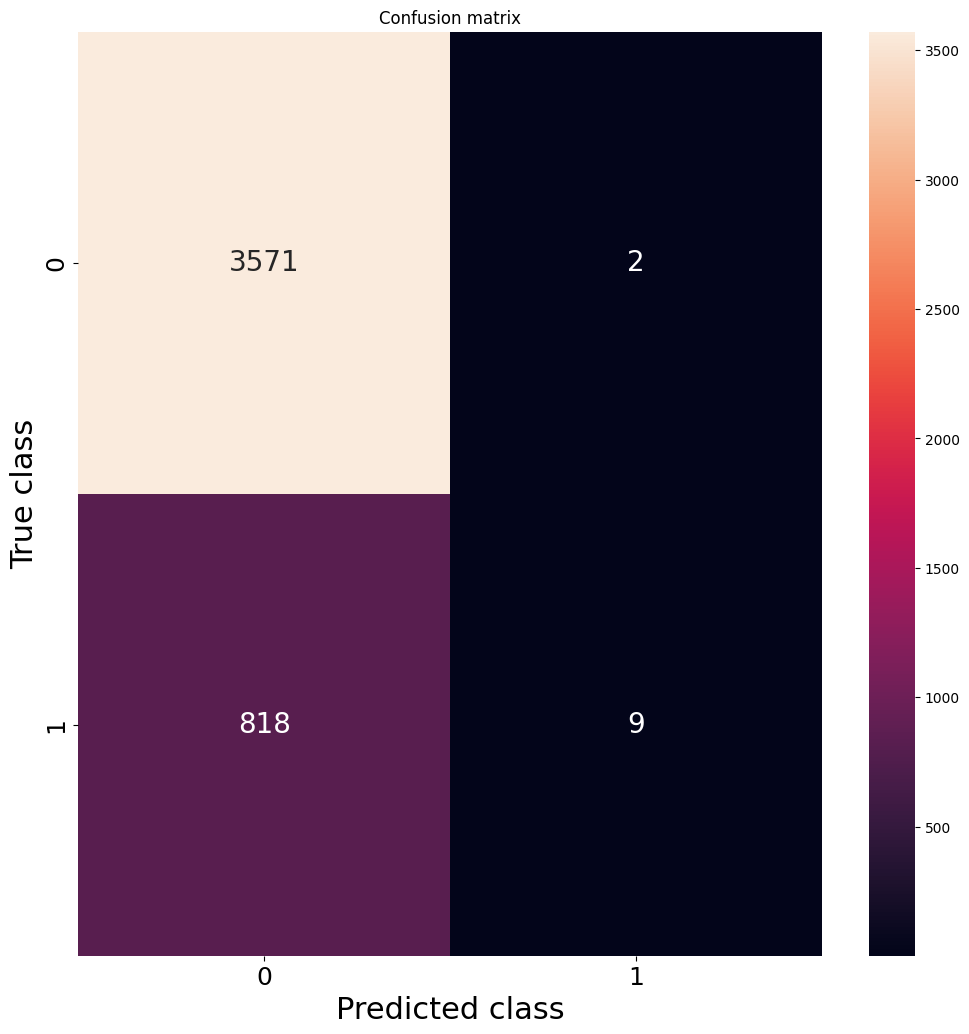

              precision    recall  f1-score   support

           0       0.81      1.00      0.90      3573
           1       0.82      0.01      0.02       827

    accuracy                           0.81      4400
   macro avg       0.82      0.51      0.46      4400
weighted avg       0.81      0.81      0.73      4400

Balanced Accuracy: 0.5052
Average Precision (PR-AUC): 0.2335
ROC AUC: 0.5800

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,1,0,0.192548
1,1,0,0.262440
2,0,0,0.160720
3,0,0,0.163609
4,0,0,0.184394
5,0,0,0.153935
6,0,0,0.175389
7,0,0,0.178816
8,0,0,0.282775
9,0,0,0.225585


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore') # Suprimir advertencias

# Asumiendo que X_train, X_test, y_train, y_test y la función mostrar_resultados
# han sido definidos en celdas anteriores, como en el código previamente adaptado.
# (Específicamente desde la celda 73171bc6 para los datos y la función mostrar_resultados)

# 1. Función para crear y entrenar el modelo baseline (sin class_weight='balanced')
def run_model(X_train_processed, y_train_data):
    clf = LogisticRegression(
        C=1.0,
        penalty='l2',
        random_state=1,
        solver="saga", # 'saga' es adecuado para datos dispersos y soporta la penalización l2.
        max_iter=2000 # Aumentar max_iter para asegurar la convergencia
    )
    clf.fit(X_train_processed, y_train_data)
    return clf

# 2. Ejecutar el modelo baseline
print("\n--- Entrenando Modelo Baseline (sin class_weight) ---")
# Usar las variables X_train, y_train disponibles globalmente que ya están preprocesadas
model_baseline = run_model(X_train, y_train)
print("Modelo de Regresión Logística (baseline) entrenado.")

# 3. Realizar predicciones y mostrar resultados
# Usar X_test y la función mostrar_resultados disponibles globalmente
pred_y_baseline = model_baseline.predict(X_test)
pred_proba_baseline = model_baseline.predict_proba(X_test)[:, 1]
print("\n--- Métricas de Evaluación en el Conjunto de Prueba (Modelo Baseline) ---")
mostrar_resultados(y_test, pred_y_baseline, pred_proba_baseline)




--- Realizando Randomized Search para Regresión Logística --- (Optimizado por Average Precision)
Fitting 3 folds for each of 10 candidates, totalling 30 fits

--- Resultados del Randomized Search ---
Mejores parámetros: {'C': np.float64(1.0129197956845732), 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'liblinear'}
Mejor puntuación (Average Precision en Validación): 0.2891

--- Optimizando el Umbral de Decisión mediante Curva Precisión-Recall ---
Umbral óptimo que maximiza el F1-Score de la clase 1: 0.5133
F1-Score máximo alcanzable estimado: 0.3645

--- Métricas de Evaluación con Umbral Optimizado por Curva PR (0.5133) ---


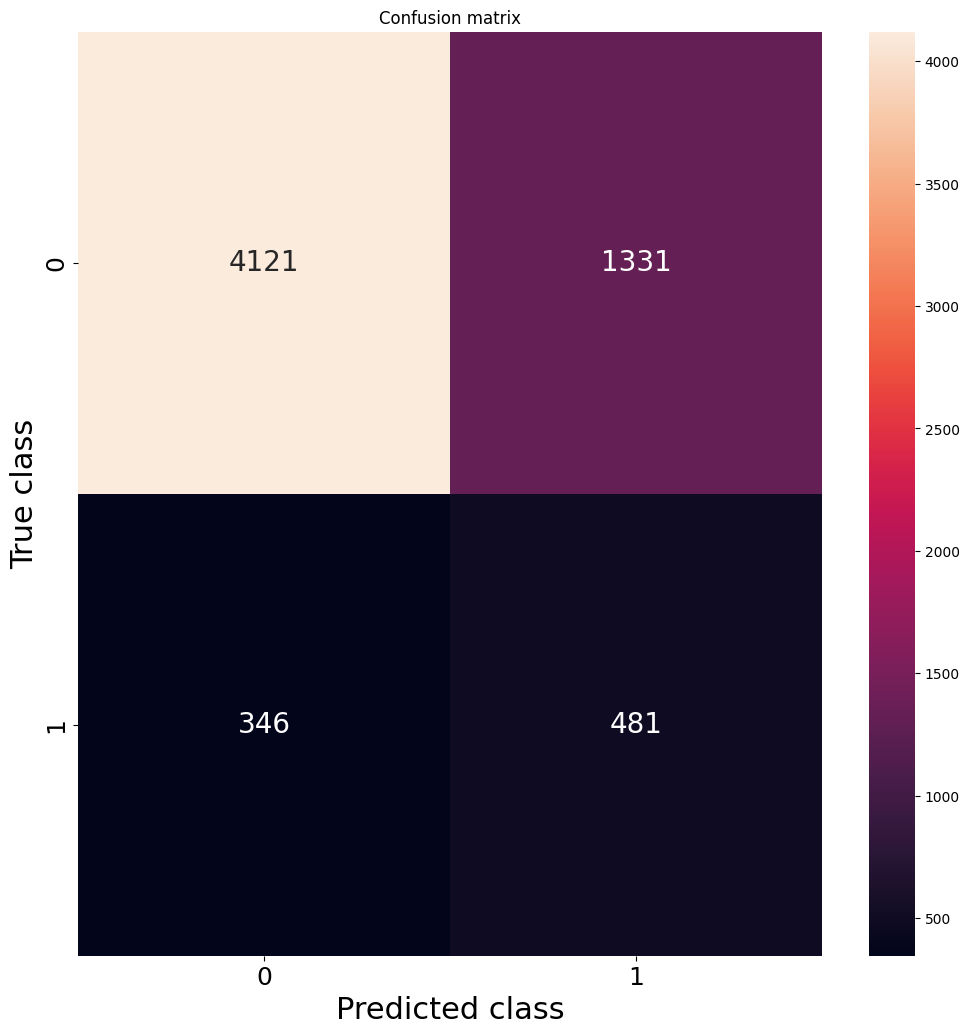

              precision    recall  f1-score   support

           0       0.92      0.76      0.83      5452
           1       0.27      0.58      0.36       827

    accuracy                           0.73      6279
   macro avg       0.59      0.67      0.60      6279
weighted avg       0.84      0.73      0.77      6279

Balanced Accuracy: 0.6687
Average Precision (PR-AUC): 0.3002
ROC AUC: 0.7324

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,0,0,0.373593
1,1,0,0.397094
2,0,0,0.127111
3,0,0,0.421581
4,0,0,0.023259
5,0,0,0.009603
6,1,0,0.264988
7,0,0,0.103414
8,0,0,0.324139
9,0,1,0.615778


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score, precision_recall_curve
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform
import warnings
warnings.filterwarnings('ignore')

if 'X_train' in locals() and 'y_train' in locals() and 'X_test' in locals() and 'y_test' in locals() and 'mostrar_resultados' in globals():
    print("\n--- Realizando Randomized Search para Regresión Logística --- (Optimizado por Average Precision)")

    # Clasificador base optimizado en velocidad
    log_reg = LogisticRegression(random_state=1, max_iter=500)

    param_distributions = {
        'C': loguniform(0.001, 100),
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear'],
        'class_weight': [None, 'balanced']
    }

    random_search = RandomizedSearchCV(
        estimator=log_reg,
        param_distributions=param_distributions,
        n_iter=10,
        cv=3,
        scoring='average_precision',
        verbose=2,
        random_state=42,
        n_jobs=-1
    )

    random_search.fit(X_train, y_train)

    print("\n--- Resultados del Randomized Search ---")
    print(f"Mejores parámetros: {random_search.best_params_}")
    print(f"Mejor puntuación (Average Precision en Validación): {random_search.best_score_:.4f}")

    best_model_rs = random_search.best_estimator_
    pred_proba_random_search = best_model_rs.predict_proba(X_test)[:, 1]

    print("\n--- Optimizando el Umbral de Decisión mediante Curva Precisión-Recall ---")
    # Obtener precisión, recall y umbrales para la curva
    precisions, recalls, thresholds = precision_recall_curve(y_test, pred_proba_random_search)

    # Calcular F1-Score para cada umbral obtenido (evitando división por cero)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)

    # El array thresholds tiene longitud len(precisions) - 1
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

    print(f"Umbral óptimo que maximiza el F1-Score de la clase 1: {best_threshold:.4f}")
    print(f"F1-Score máximo alcanzable estimado: {f1_scores[best_idx]:.4f}")

    # Generar predicciones binarias aplicando el umbral optimizado
    pred_y_opt = (pred_proba_random_search >= best_threshold).astype(int)

    print(f"\n--- Métricas de Evaluación con Umbral Optimizado por Curva PR ({best_threshold:.4f}) ---")
    mostrar_resultados(y_test, pred_y_opt, pred_proba_random_search)

else:
    print("Las variables X_train, y_train, X_test, y_test o la función mostrar_resultados no están disponibles.")


--- Realizando Randomized Search para Regresión Logística --- (Optimizado por Average Precision)
Fitting 3 folds for each of 10 candidates, totalling 30 fits

--- Resultados del Randomized Search --- (Optimizado por Average Precision)
Mejores parámetros: {'C': np.float64(1.0129197956845732), 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'liblinear'}
Mejor puntuación (Average Precision): 0.3496
Modelo de Regresión Logística (Randomized Search) entrenado con los mejores parámetros.

--- Métricas de Evaluación en el Conjunto de Prueba (Modelo Randomized Search) --- (Optimizado por Average Precision)


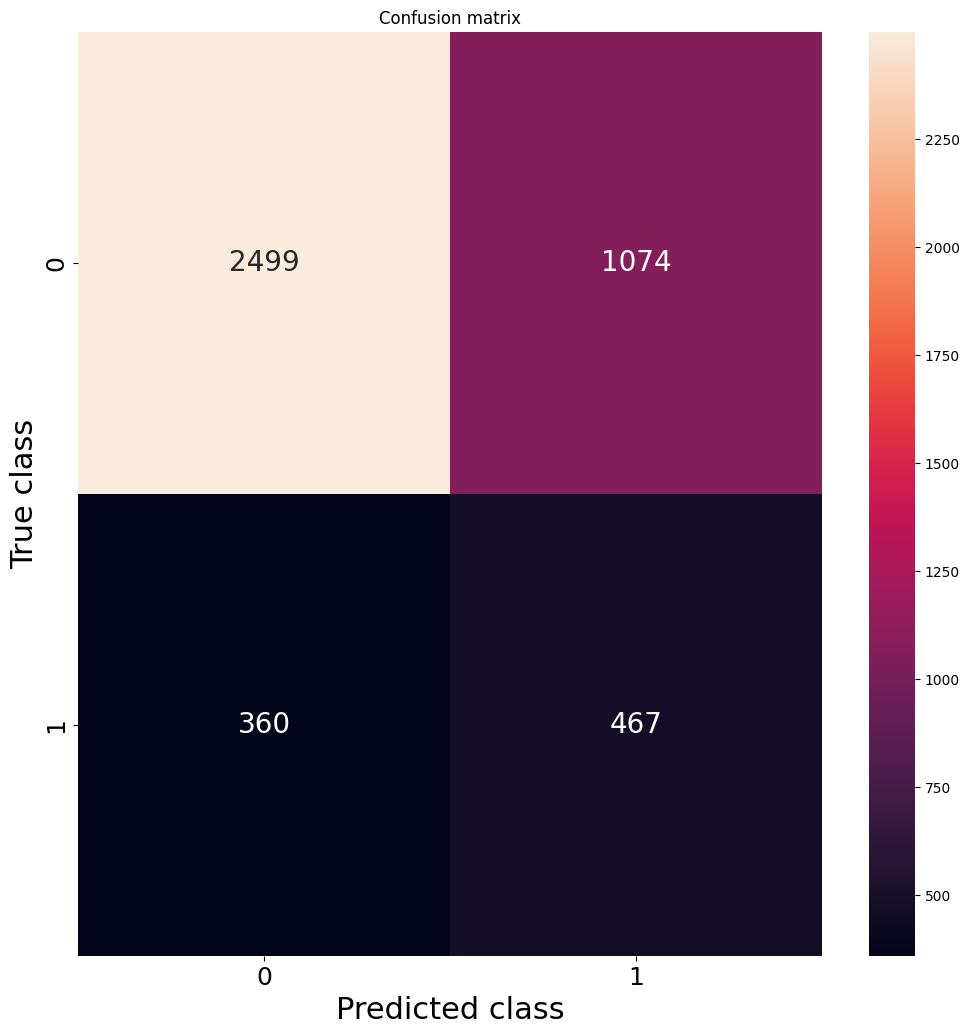

              precision    recall  f1-score   support

           0       0.87      0.70      0.78      3573
           1       0.30      0.56      0.39       827

    accuracy                           0.67      4400
   macro avg       0.59      0.63      0.59      4400
weighted avg       0.77      0.67      0.71      4400

Balanced Accuracy: 0.6321
Average Precision (PR-AUC): 0.3693
ROC AUC: 0.6917

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,1,1,0.506071
1,1,0,0.371514
2,0,0,0.165043
3,0,0,0.208188
4,0,1,0.506913
5,0,0,0.058237
6,0,1,0.656459
7,0,0,0.410017
8,0,0,0.118752
9,0,1,0.658400


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score, recall_score
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform
import warnings
warnings.filterwarnings('ignore')

if 'X_train' in locals() and 'y_train' in locals() and 'X_test' in locals() and 'y_test' in locals() and 'mostrar_resultados' in globals():
    print("\n--- Realizando Randomized Search para Regresión Logística --- (Optimizado por Average Precision)")

    # CAMBIO: solver='saga' -> 'liblinear' (el cambio de mayor impacto en velocidad).
    # liblinear soporta l1 y l2 igual que saga, pero converge mucho más rápido en
    # datos dispersos de alta dimensión (TF-IDF) mediante descenso de coordenadas.
    log_reg = LogisticRegression(random_state=1, max_iter=500)  # max_iter bajado también, liblinear lo necesita menos

    param_distributions = {
        'C': loguniform(0.001, 100),
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear'],  # CAMBIO
        'class_weight': [None, 'balanced']
    }

    random_search = RandomizedSearchCV(
        estimator=log_reg,
        param_distributions=param_distributions,
        n_iter=10,
        cv=3,
        scoring='average_precision', # REVERTIDO: Optimización por Average Precision
        verbose=2,
        random_state=42,
        n_jobs=-1
    )

    random_search.fit(X_train, y_train)

    print("\n--- Resultados del Randomized Search --- (Optimizado por Average Precision)")
    print(f"Mejores parámetros: {random_search.best_params_}")
    print(f"Mejor puntuación (Average Precision): {random_search.best_score_:.4f}")

    best_model_rs = random_search.best_estimator_
    print("Modelo de Regresión Logística (Randomized Search) entrenado con los mejores parámetros.")

    pred_y_random_search = best_model_rs.predict(X_test)
    pred_proba_random_search = best_model_rs.predict_proba(X_test)[:, 1]

    print("\n--- Métricas de Evaluación en el Conjunto de Prueba (Modelo Randomized Search) --- (Optimizado por Average Precision)")
    mostrar_resultados(y_test, pred_y_random_search, pred_proba_random_search)

else:
    print("Las variables X_train, y_train, X_test, y_test o la función mostrar_resultados no están disponibles.")


--- Entrenando Modelo con class_weight='balanced' ---
Modelo de Regresión Logística (balanced) entrenado.

--- Métricas de Evaluación en el Conjunto de Prueba (balanced) ---


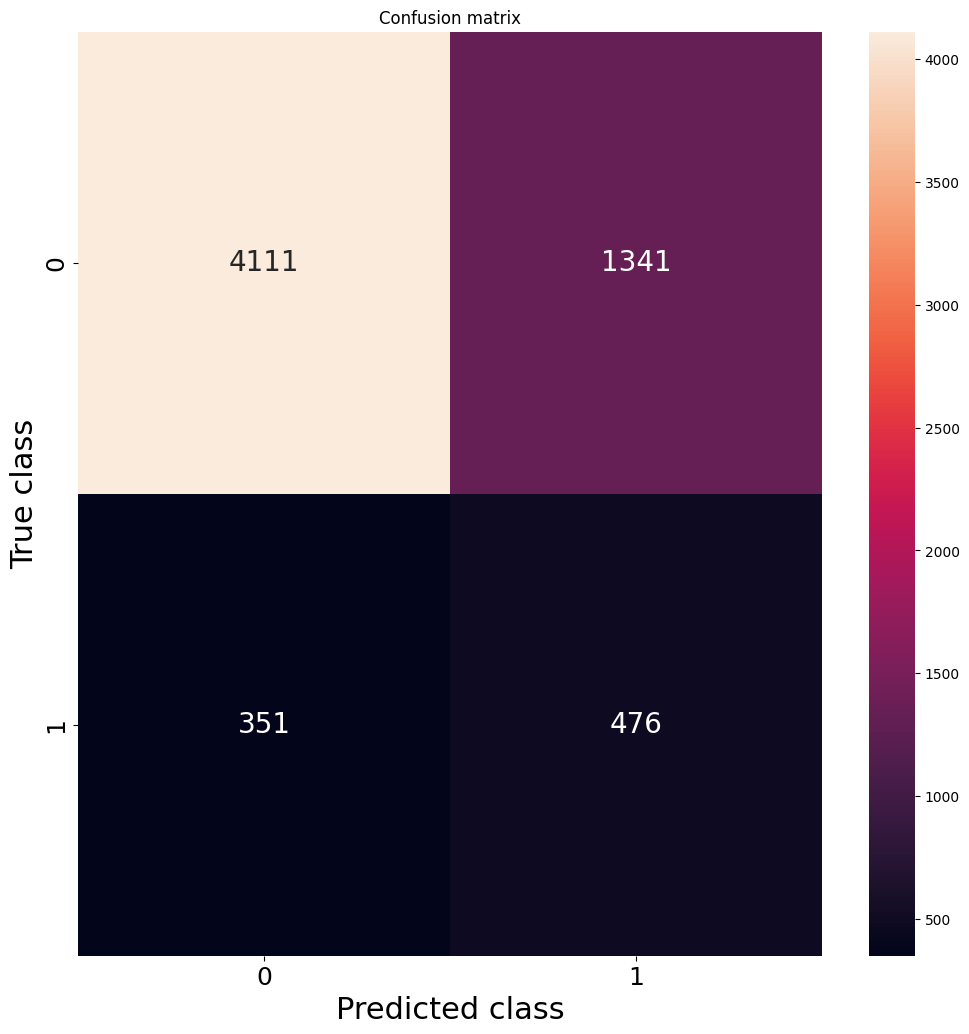

              precision    recall  f1-score   support

           0       0.92      0.75      0.83      5452
           1       0.26      0.58      0.36       827

    accuracy                           0.73      6279
   macro avg       0.59      0.66      0.59      6279
weighted avg       0.83      0.73      0.77      6279

Balanced Accuracy: 0.6648
Average Precision (PR-AUC): 0.3141
ROC AUC: 0.7405

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,0,0,0.255863
1,1,0,0.452219
2,0,0,0.152311
3,0,0,0.437319
4,0,0,0.065636
5,0,0,0.015092
6,1,0,0.227429
7,0,0,0.093179
8,0,0,0.373023
9,0,1,0.562880


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore') # Suprimir advertencias

# Asumiendo que X_train, X_test, y_train, y_test y la función mostrar_resultados
# han sido definidos en celdas anteriores, como en el código previamente adaptado.

# 1. Función para crear y entrenar el modelo con class_weight='balanced'
def run_model_balanced(X_train_processed, y_train_data):
    clf = LogisticRegression(
        C=1.0,
        penalty='l2',
        random_state=1,
        solver="saga", # Usar 'saga' para consistencia y soporte de 'balanced' class_weight
        max_iter=2000, # Aumentar max_iter para asegurar convergencia
        class_weight="balanced"
    )
    clf.fit(X_train_processed, y_train_data)
    return clf

# 2. Ejecutar el modelo con class_weight='balanced'
print("\n--- Entrenando Modelo con class_weight='balanced' ---")
model_balanced = run_model_balanced(X_train, y_train)
print("Modelo de Regresión Logística (balanced) entrenado.")

# 3. Realizar predicciones y mostrar resultados
pred_y_balanced = model_balanced.predict(X_test)
pred_proba_balanced = model_balanced.predict_proba(X_test)[:, 1]
print("\n--- Métricas de Evaluación en el Conjunto de Prueba (balanced) ---")
mostrar_resultados(y_test, pred_y_balanced, pred_proba_balanced)


Distribución antes del undersampling: Counter({0: 21806, 1: 3309})
Distribución después del undersampling: Counter({0: 6618, 1: 3309})

--- Entrenando Modelo con datos remuestreados
Modelo de Regresión Logística (NearMiss) entrenado.

--- Métricas de Evaluación en el Conjunto de Prueba


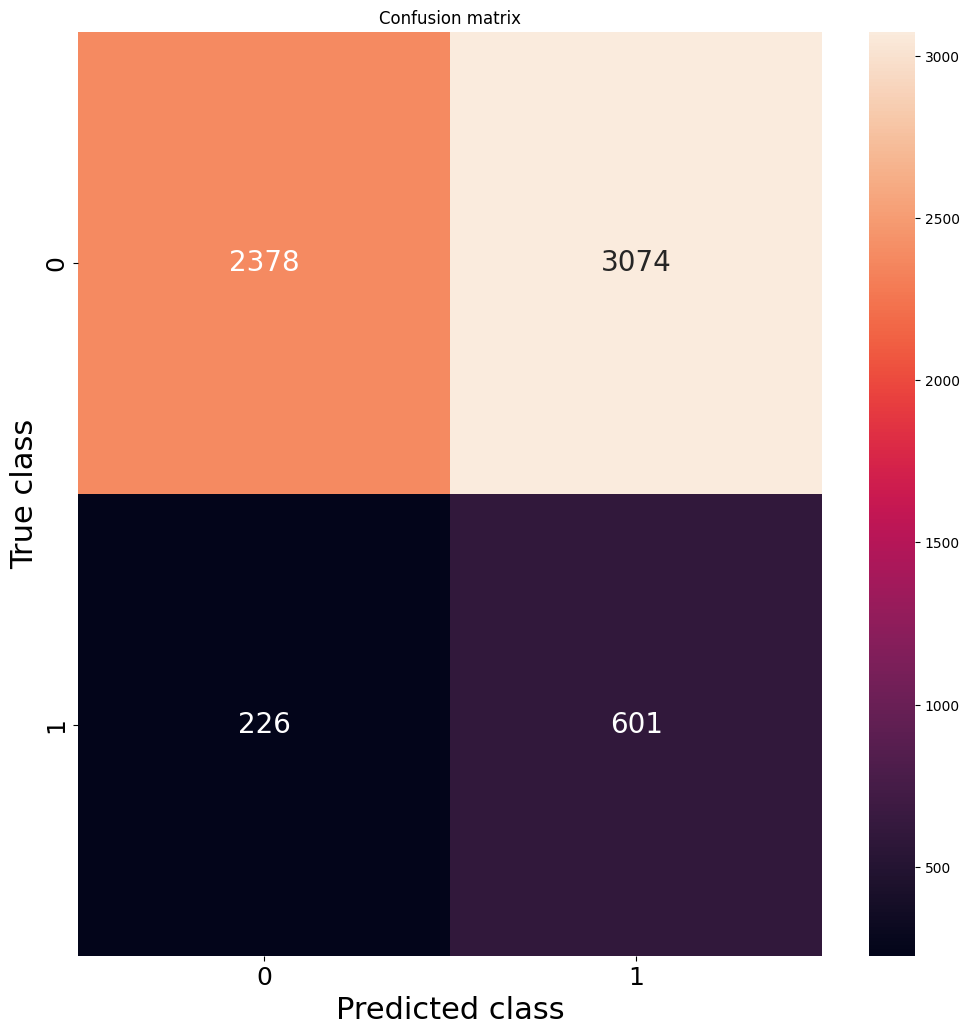

              precision    recall  f1-score   support

           0       0.91      0.44      0.59      5452
           1       0.16      0.73      0.27       827

    accuracy                           0.47      6279
   macro avg       0.54      0.58      0.43      6279
weighted avg       0.81      0.47      0.55      6279

Balanced Accuracy: 0.5814
Average Precision (PR-AUC): 0.2071
ROC AUC: 0.6328

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,0,1,0.665370
1,1,0,0.138920
2,0,1,0.515134
3,0,1,0.659587
4,0,0,0.105509
5,0,1,0.675027
6,1,1,0.523934
7,0,0,0.274963
8,0,0,0.079231
9,0,1,0.629142


In [ ]:
from imblearn.under_sampling import NearMiss
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Asegurarse de que X_train, y_train, X_test, y_test están disponibles del preprocesamiento anterior.
# Asegurarse de que run_model_balanced y mostrar_resultados están definidos en celdas anteriores.

# 1. Aplicar undersampling con NearMiss
print(f"Distribución antes del undersampling: {Counter(y_train)}")
us = NearMiss(sampling_strategy=0.5, n_neighbors=3, version=2)
X_train_res, y_train_res = us.fit_resample(X_train, y_train)
print(f"Distribución después del undersampling: {Counter(y_train_res)}")

# 2. Entrenar el modelo con los datos remuestreados
print("\n--- Entrenando Modelo con datos remuestreados")
# Usar la función run_model_balanced definida previamente
model_resampled_uv = run_model_balanced(X_train_res, y_train_res)
print("Modelo de Regresión Logística (NearMiss) entrenado.")

# 3. Realizar predicciones y mostrar resultados en el conjunto de prueba original
pred_y_resampled_uv = model_resampled_uv.predict(X_test)
pred_proba_resampled_uv = model_resampled_uv.predict_proba(X_test)[:, 1]
print("\n--- Métricas de Evaluación en el Conjunto de Prueba")
mostrar_resultados(y_test, pred_y_resampled_uv, pred_proba_resampled_uv)


Distribución antes del oversampling: Counter({0: 21806, 1: 3309})
Distribución después del oversampling: Counter({0: 21806, 1: 10903})

--- Entrenando Modelo con datos remuestreados (RandomOverSampler) ---
Modelo de Regresión Logística (RandomOverSampler) entrenado.

--- Métricas de Evaluación en el Conjunto de Prueba (Modelo RandomOverSampler) ---


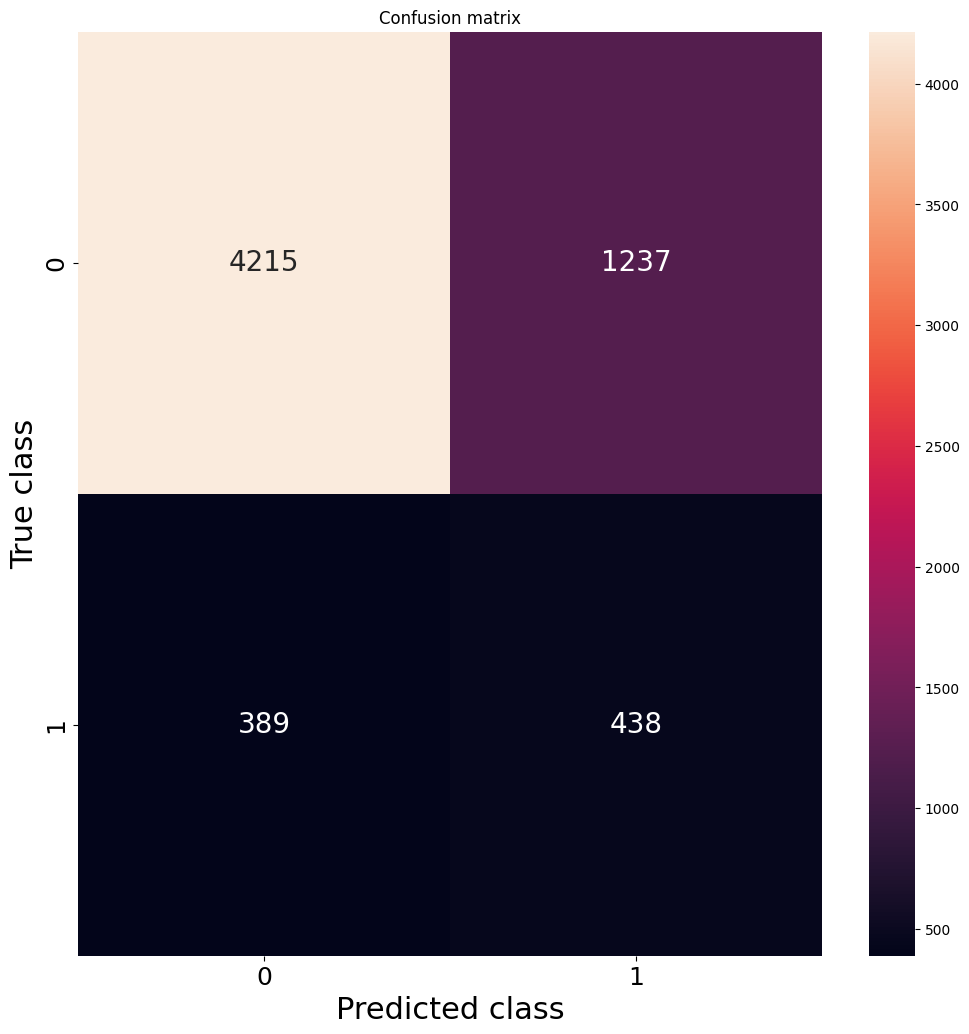

              precision    recall  f1-score   support

           0       0.92      0.77      0.84      5452
           1       0.26      0.53      0.35       827

    accuracy                           0.74      6279
   macro avg       0.59      0.65      0.59      6279
weighted avg       0.83      0.74      0.77      6279

Balanced Accuracy: 0.6514
Average Precision (PR-AUC): 0.3186
ROC AUC: 0.7352

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,0,0,0.206637
1,1,0,0.319165
2,0,0,0.119986
3,0,0,0.363301
4,0,0,0.045174
5,0,0,0.012624
6,1,0,0.213871
7,0,0,0.093543
8,0,0,0.372820
9,0,1,0.537570


In [ ]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Asegurarse de que X_train, y_train, X_test, y_test están disponibles del preprocesamiento anterior.
# Asegurarse de que run_model_balanced y mostrar_resultados están definidos en celdas anteriores.

# 1. Aplicar oversampling con RandomOverSampler
print(f"Distribución antes del oversampling: {Counter(y_train)}")
os = RandomOverSampler(sampling_strategy=0.5, random_state=42) # Usar sampling_strategy y random_state para reproducibilidad
X_train_res, y_train_res = os.fit_resample(X_train, y_train)
print(f"Distribución después del oversampling: {Counter(y_train_res)}")

# 2. Entrenar el modelo con los datos remuestreados
print("\n--- Entrenando Modelo con datos remuestreados (RandomOverSampler) ---")
# Usar la función run_model_balanced definida previamente
model_oversampled = run_model_balanced(X_train_res, y_train_res)
print("Modelo de Regresión Logística (RandomOverSampler) entrenado.")

# 3. Realizar predicciones y mostrar resultados en el conjunto de prueba original
pred_y_oversampled = model_oversampled.predict(X_test)
pred_proba_oversampled = model_oversampled.predict_proba(X_test)[:, 1]
print("\n--- Métricas de Evaluación en el Conjunto de Prueba (Modelo RandomOverSampler) ---")
mostrar_resultados(y_test, pred_y_oversampled, pred_proba_oversampled)


--- Entrenando Modelo Random Forest con Pesos de Clase Balanceados ---
Modelo Random Forest entrenado exitosamente.

--- Métricas de Evaluación para Random Forest (Test Set) ---


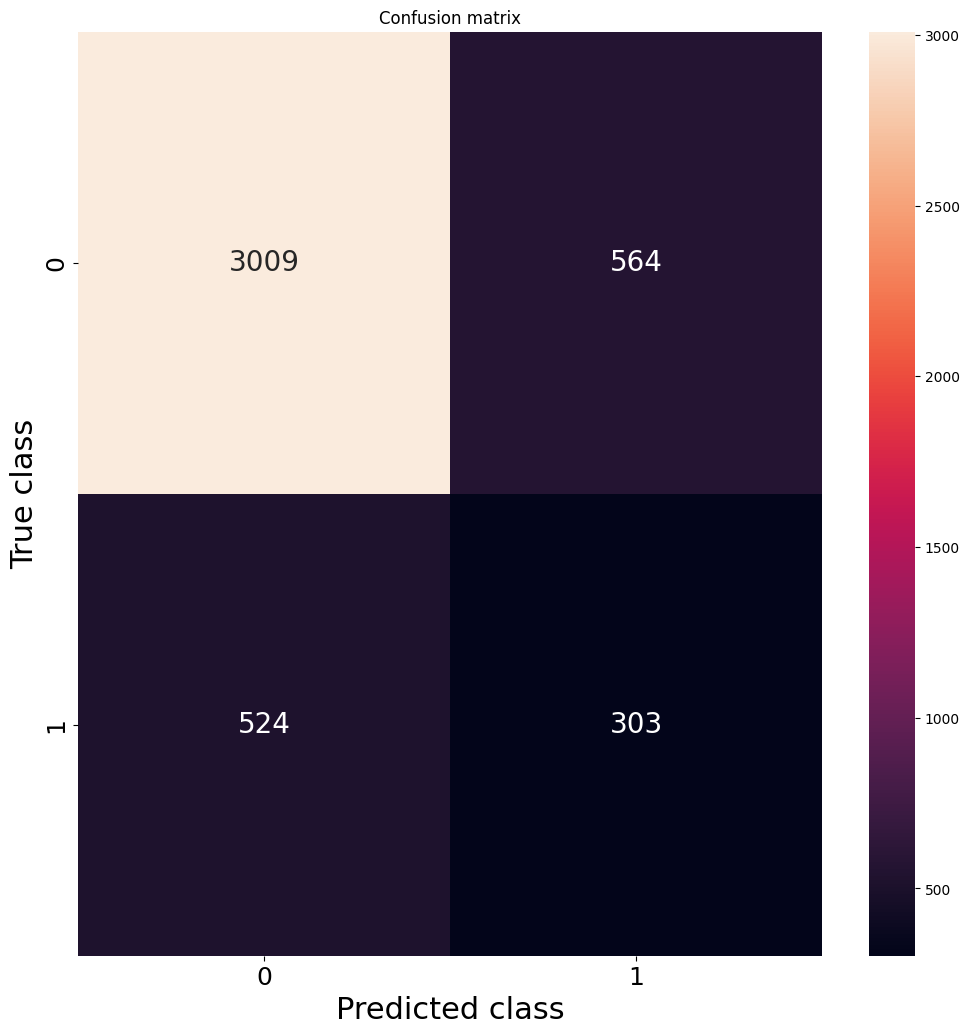

              precision    recall  f1-score   support

           0       0.85      0.84      0.85      3573
           1       0.35      0.37      0.36       827

    accuracy                           0.75      4400
   macro avg       0.60      0.60      0.60      4400
weighted avg       0.76      0.75      0.75      4400

Balanced Accuracy: 0.6043
Average Precision (PR-AUC): 0.3436
ROC AUC: 0.6575

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,1,1,0.506031
1,1,0,0.488148
2,0,0,0.482406
3,0,0,0.473587
4,0,0,0.494563
5,0,0,0.124767
6,0,0,0.483391
7,0,0,0.459169
8,0,0,0.331070
9,0,1,0.501471


In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score, balanced_accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'X_train' in locals() and 'y_train' in locals() and 'X_test' in locals() and 'y_test' in locals() and 'mostrar_resultados' in globals():
    print("--- Entrenando Modelo Random Forest con Pesos de Clase Balanceados ---")

    # Inicializar el clasificador Random Forest
    # Usamos n_estimators moderado y max_depth para controlar el sobreajuste y el tiempo de ejecución
    rf_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )

    # Ajustar el modelo
    rf_model.fit(X_train, y_train)
    print("Modelo Random Forest entrenado exitosamente.")

    # Realizar predicciones
    pred_y_rf = rf_model.predict(X_test)
    pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]

    # Evaluar los resultados
    print("\n--- Métricas de Evaluación para Random Forest (Test Set) ---")
    mostrar_resultados(y_test, pred_y_rf, pred_proba_rf)
else:
    print("Las variables preprocesadas (X_train, y_train, etc.) o la función 'mostrar_resultados' no se encuentran en el entorno.")

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'X_train' in locals() and 'y_train' in locals() and 'X_test' in locals() and 'y_test' in locals() and 'mostrar_resultados' in globals():
    print("--- Iniciando Ajuste y Optimización de Hiperparámetros para Random Forest ---")

    # Definir el estimador base
    rf_base = RandomForestClassifier(random_state=42, n_jobs=-1, class_weight='balanced')

    # Rango de parámetros a explorar de manera eficiente
    param_dist = {
        'n_estimators': [50, 100, 150],
        'max_depth': [10, 15, 20, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2', None]
    }

    # Configurar la búsqueda aleatoria optimizando por 'average_precision'
    rf_random_search = RandomizedSearchCV(
        estimator=rf_base,
        param_distributions=param_dist,
        n_iter=8,
        cv=3,
        scoring='average_precision',
        verbose=2,
        random_state=42,
        n_jobs=-1
    )

    # Ejecutar la búsqueda
    rf_random_search.fit(X_train, y_train)

    print("\n--- Resultados de la Optimización ---")
    print(f"Mejores parámetros encontrados: {rf_random_search.best_params_}")
    print(f"Mejor score de validación (PR-AUC): {rf_random_search.best_score_:.4f}")

    # Evaluar el mejor modelo en el conjunto de test
    best_rf_model = rf_random_search.best_estimator_
    pred_y_best_rf = best_rf_model.predict(X_test)
    pred_proba_best_rf = best_rf_model.predict_proba(X_test)[:, 1]

    print("\n--- Métricas de Evaluación para el Mejor Random Forest (Test Set) ---")
    mostrar_resultados(y_test, pred_y_best_rf, pred_proba_best_rf)
else:
    print("Las variables transformadas X_train o la función 'mostrar_resultados' no están definidas en el entorno.")

--- Iniciando Ajuste y Optimización de Hiperparámetros para Random Forest ---
Fitting 3 folds for each of 8 candidates, totalling 24 fits


KeyboardInterrupt: 

--- Entrenamiento con Validación Cruzada Estratificada (5 Folds) ---

Fold 1 -> PR-AUC: 0.3596 | Balanced Accuracy: 0.6307 | ROC-AUC: 0.6905
Fold 2 -> PR-AUC: 0.3565 | Balanced Accuracy: 0.6387 | ROC-AUC: 0.6962
Fold 3 -> PR-AUC: 0.3625 | Balanced Accuracy: 0.6354 | ROC-AUC: 0.7007
Fold 4 -> PR-AUC: 0.3716 | Balanced Accuracy: 0.6221 | ROC-AUC: 0.6815
Fold 5 -> PR-AUC: 0.3762 | Balanced Accuracy: 0.6391 | ROC-AUC: 0.7031

--- Métricas Promedio de la Validación Cruzada ---
Promedio PR-AUC: 0.3653 (+/- 0.0074)
Promedio Balanced Accuracy: 0.6332 (+/- 0.0063)
Promedio ROC-AUC: 0.6944 (+/- 0.0078)

--- Evaluando Modelo Final en el Conjunto de Prueba Exhaustivo ---


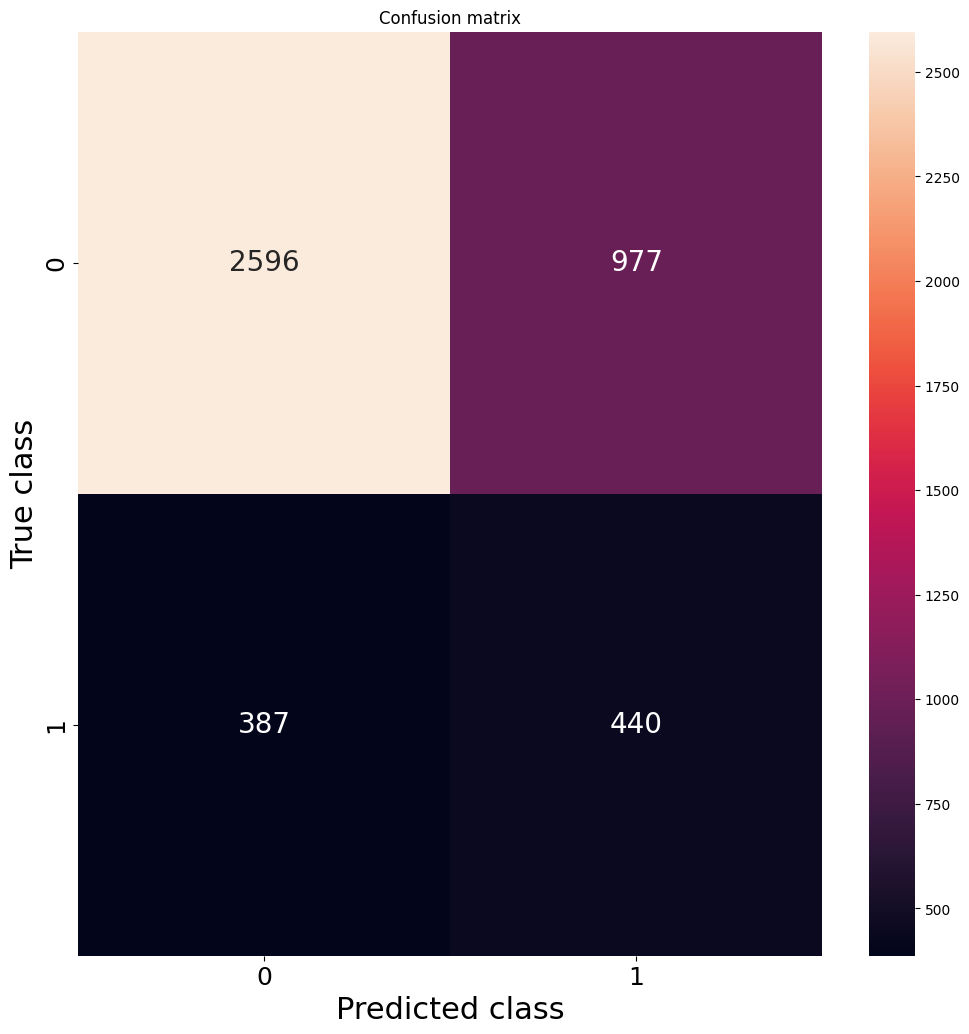

              precision    recall  f1-score   support

           0       0.87      0.73      0.79      3573
           1       0.31      0.53      0.39       827

    accuracy                           0.69      4400
   macro avg       0.59      0.63      0.59      4400
weighted avg       0.77      0.69      0.72      4400

Balanced Accuracy: 0.6293
Average Precision (PR-AUC): 0.3758
ROC AUC: 0.6893

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,1,0,0.479568
1,1,0,0.243800
2,0,0,0.126026
3,0,0,0.104225
4,0,0,0.471252
5,0,0,0.059791
6,0,1,0.678178
7,0,0,0.498667
8,0,0,0.098372
9,0,1,0.765394


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, balanced_accuracy_score, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

if 'X_train' in locals() and 'y_train' in locals() and 'X_test' in locals() and 'y_test' in locals() and 'mostrar_resultados' in globals():
    print("--- Entrenamiento con Validación Cruzada Estratificada (5 Folds) ---\n")

    # Convertir X_train a matriz dispersa CSR si no lo es para agilizar el indexado por fold
    from scipy.sparse import issparse
    if issparse(X_train):
        X_train_fold = X_train.tocsr()
    else:
        X_train_fold = np.array(X_train)

    y_train_fold = np.array(y_train)

    # Inicializar validación cruzada y listas de métricas
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    fold_pr_aucs = []
    fold_balanced_accs = []
    fold_roc_aucs = []

    # Definir el modelo base optimizado
    model_cv = LogisticRegression(
        C=1.0,
        penalty='l2',
        random_state=42,
        solver='liblinear',
        class_weight='balanced'
    )

    for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_fold, y_train_fold), 1):
        # Dividir datos del fold
        X_tr, X_val = X_train_fold[train_idx], X_train_fold[val_idx]
        y_tr, y_val = y_train_fold[train_idx], y_train_fold[val_idx]

        # Entrenar
        model_cv.fit(X_tr, y_tr)

        # Predecir probabilidades y clases
        val_preds = model_cv.predict(X_val)
        val_probs = model_cv.predict_proba(X_val)[:, 1]

        # Calcular métricas
        pr_auc = average_precision_score(y_val, val_probs)
        bal_acc = balanced_accuracy_score(y_val, val_preds)
        roc_auc = roc_auc_score(y_val, val_probs)

        fold_pr_aucs.append(pr_auc)
        fold_balanced_accs.append(bal_acc)
        fold_roc_aucs.append(roc_auc)

        print(f"Fold {fold} -> PR-AUC: {pr_auc:.4f} | Balanced Accuracy: {bal_acc:.4f} | ROC-AUC: {roc_auc:.4f}")

    print("\n--- Métricas Promedio de la Validación Cruzada ---")
    print(f"Promedio PR-AUC: {np.mean(fold_pr_aucs):.4f} (+/- {np.std(fold_pr_aucs):.4f})")
    print(f"Promedio Balanced Accuracy: {np.mean(fold_balanced_accs):.4f} (+/- {np.std(fold_balanced_accs):.4f})")
    print(f"Promedio ROC-AUC: {np.mean(fold_roc_aucs):.4f} (+/- {np.std(fold_roc_aucs):.4f})")

    # Entrenar el modelo final en todo el set de entrenamiento
    print("\n--- Evaluando Modelo Final en el Conjunto de Prueba Exhaustivo ---")
    model_cv.fit(X_train, y_train)
    final_preds = model_cv.predict(X_test)
    final_probs = model_cv.predict_proba(X_test)[:, 1]

    mostrar_resultados(y_test, final_preds, final_probs)
else:
    print("Las variables de entrenamiento X_train, y_train o la función 'mostrar_resultados' no están definidas.")

### 9. Modelo con Embeddings


--- Modelo con Sentence Embeddings de Título, Descripción y Componente ---
Forma de los datos después de la división:
X_train_raw_desc_st: (17599, 4), X_test_raw_desc_st: (4400, 4)

Cargando modelo Sentence Transformer...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Generando embeddings del texto combinado...


Batches:   0%|          | 0/275 [00:00<?, ?it/s]

Batches:   0%|          | 0/69 [00:00<?, ?it/s]


Dimensiones de las características combinadas finales:
X_train_processed_st: (17599, 977)
X_test_processed_st: (4400, 977)

--- Entrenando Modelo con las mismas variables que TF-IDF y class_weight='balanced' ---
Modelo entrenado exitosamente.


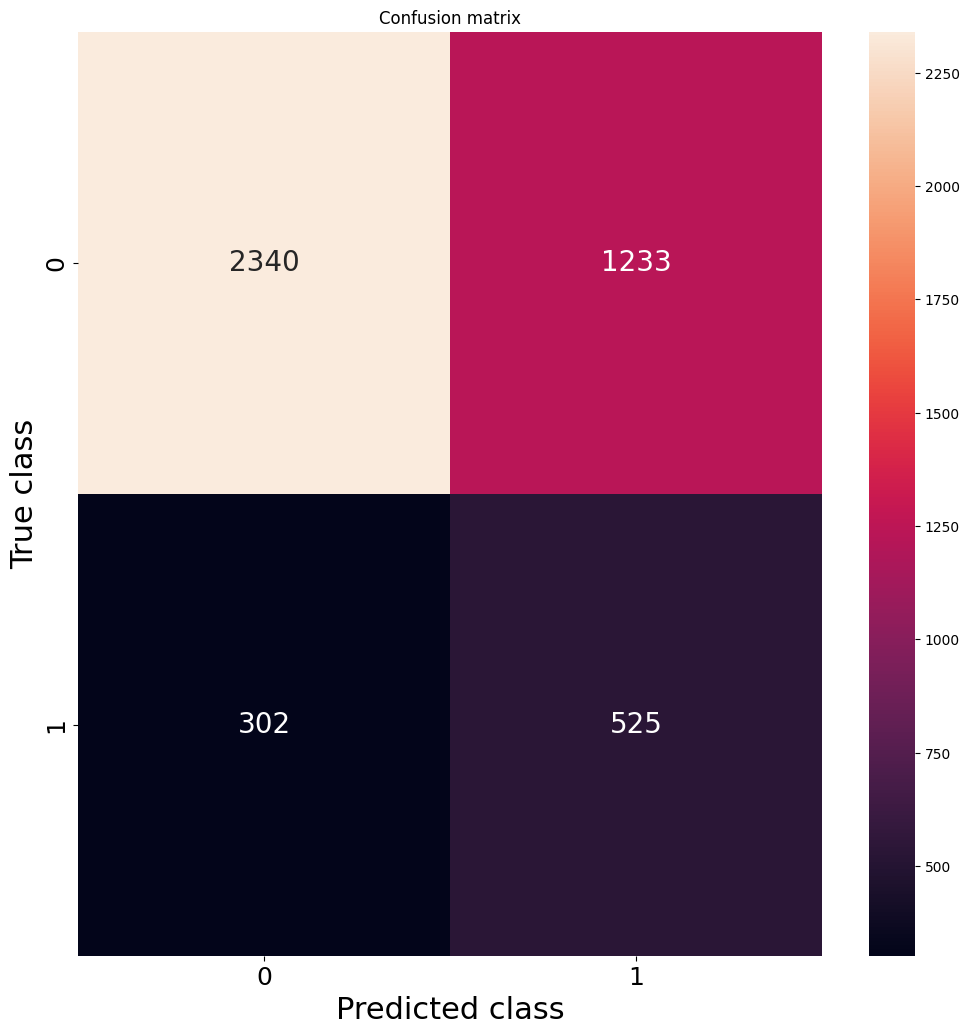

              precision    recall  f1-score   support

           0       0.89      0.65      0.75      3573
           1       0.30      0.63      0.41       827

    accuracy                           0.65      4400
   macro avg       0.59      0.64      0.58      4400
weighted avg       0.78      0.65      0.69      4400

Balanced Accuracy: 0.6449
Average Precision (PR-AUC): 0.3648
ROC AUC: 0.6985

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,1,1,0.659152
1,1,0,0.309120
2,0,0,0.188894
3,0,0,0.226831
4,0,0,0.477835
5,0,0,0.101328
6,0,1,0.574836
7,0,0,0.316087
8,0,0,0.195736
9,0,1,0.633573


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sentence_transformers import SentenceTransformer
import warnings
warnings.filterwarnings('ignore')

if 'df' in locals() and df is not None:
    print("\n--- Modelo con Sentence Embeddings de Título, Descripción y Componente ---")

    # 1. Definir la variable objetivo
    y_desc_st = df['target'].astype(int)

    # 2. Crear una copia del DataFrame para X y asegurar el manejo de NaN
    df_model_desc_only_st = df.copy()
    df_model_desc_only_st['priority'] = df_model_desc_only_st['priority'].fillna('No Priority').astype(str)
    df_model_desc_only_st['reporter_id'] = df_model_desc_only_st['reporter_id'].fillna('No Reporter').astype(str)

    # Combinar title, description y First_Component en un campo único de texto para Sentence Transformers
    df_model_desc_only_st['Texto_Combinado_ST'] = (
        df_model_desc_only_st['title'].fillna('') + ' ' +
        df_model_desc_only_st['description'].fillna('') + ' ' +
        df_model_desc_only_st['First_Component'].fillna('').astype(str)
    )

    # 3. Definir características numéricas, categóricas y de texto emulando TF-IDF
    numerical_features_desc_st = [
        'story_point_inicial',
    ]
    categorical_features_desc_st = [
        'priority',
        'reporter_id'
    ]
    combined_text_feature_col_st = 'Texto_Combinado_ST'

    # Combinar todas las características en un solo DataFrame para X
    features_to_use_desc_st = numerical_features_desc_st + categorical_features_desc_st + [combined_text_feature_col_st]
    X_st = df_model_desc_only_st[features_to_use_desc_st]

    # 4. Dividir los datos en sets de entrenamiento y test
    X_train_raw_desc_st, X_test_raw_desc_st, y_train_desc_st, y_test_desc_st = train_test_split(
        X_st, y_desc_st, test_size=0.20, random_state=42, stratify=y_desc_st
    )

    print("Forma de los datos después de la división:")
    print(f"X_train_raw_desc_st: {X_train_raw_desc_st.shape}, X_test_raw_desc_st: {X_test_raw_desc_st.shape}")

    # 5. Cargar el modelo Sentence Transformer y generar embeddings
    print("\nCargando modelo Sentence Transformer...")
    st_model = SentenceTransformer('all-MiniLM-L6-v2')
    print("Generando embeddings del texto combinado...")

    train_texts = X_train_raw_desc_st[combined_text_feature_col_st].fillna('').tolist()
    test_texts = X_test_raw_desc_st[combined_text_feature_col_st].fillna('').tolist()

    X_train_desc_embeddings = st_model.encode(train_texts, show_progress_bar=True, batch_size=64)
    X_test_desc_embeddings = st_model.encode(test_texts, show_progress_bar=True, batch_size=64)

    # 6. Preprocesamiento para características numéricas y categóricas
    preprocessor_num_cat_st = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features_desc_st),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features_desc_st)
        ],
        remainder='drop',
        verbose_feature_names_out=False
    )

    # Transformar características numéricas y categóricas
    X_train_num_cat_st = preprocessor_num_cat_st.fit_transform(X_train_raw_desc_st)
    X_test_num_cat_st = preprocessor_num_cat_st.transform(X_test_raw_desc_st)

    # 7. Concatenar todas las características (Numéricas + Categóricas transformadas + Embeddings)
    X_train_processed_st = np.hstack((X_train_num_cat_st, X_train_desc_embeddings))
    X_test_processed_st = np.hstack((X_test_num_cat_st, X_test_desc_embeddings))

    print("\nDimensiones de las características combinadas finales:")
    print(f"X_train_processed_st: {X_train_processed_st.shape}")
    print(f"X_test_processed_st: {X_test_processed_st.shape}")

    # 8. Definición del modelo
    if 'run_model_balanced' not in globals():
        def run_model_balanced(X_train_processed, y_train_data):
            clf = LogisticRegression(
                C=1.0,
                penalty='l2',
                random_state=1,
                solver="saga",
                max_iter=2000,
                class_weight="balanced"
            )
            clf.fit(X_train_processed, y_train_data)
            return clf

    # 9. Entrenar el modelo
    print("\n--- Entrenando Modelo con las mismas variables que TF-IDF y class_weight='balanced' ---")
    model_desc_only_st = run_model_balanced(X_train_processed_st, y_train_desc_st)
    print("Modelo entrenado exitosamente.")

    # 10. Realizar predicciones y mostrar resultados
    pred_y_desc_only_st = model_desc_only_st.predict(X_test_processed_st)
    pred_proba_desc_only_st = model_desc_only_st.predict_proba(X_test_processed_st)[:, 1]

    if 'mostrar_resultados' in globals():
        mostrar_resultados(y_test_desc_st, pred_y_desc_only_st, pred_proba_desc_only_st)
    else:
        LABELS_st = y_test_desc_st.unique().astype(str)
        conf_matrix_st = confusion_matrix(y_test_desc_st, pred_y_desc_only_st)
        plt.figure(figsize=(12, 12))
        sns.heatmap(conf_matrix_st, xticklabels=LABELS_st, yticklabels=LABELS_st, annot=True, fmt="d")
        plt.title("Confusion matrix")
        plt.ylabel('True class')
        plt.xlabel('Predicted class')
        plt.show()
        print(classification_report(y_test_desc_st, pred_y_desc_only_st))

else:
    print("El DataFrame 'df' no está disponible o no se cargó correctamente.")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sentence_transformers import SentenceTransformer
import warnings
warnings.filterwarnings('ignore')

if 'df' in locals() and df is not None:
    print("\n--- Modelo con Sentence Embeddings de Título, Descripción, Componentes y Comentarios ---")

    # 1. Definir la variable objetivo
    y_desc_st = df['target'].astype(int)

    # 2. Crear una copia del DataFrame para X y asegurar el manejo de NaN
    df_model_desc_only_st = df.copy()
    df_model_desc_only_st['priority'] = df_model_desc_only_st['priority'].fillna('No Priority').astype(str)
    df_model_desc_only_st['reporter_id'] = df_model_desc_only_st['reporter_id'].fillna('No Reporter').astype(str)

    # Combinar title, description, All_Components y All_Comments en un campo único de texto para Sentence Transformers
    df_model_desc_only_st['Texto_Combinado_ST'] = (
        df_model_desc_only_st['title'].fillna('') + ' ' +
        df_model_desc_only_st['description'].fillna('') + ' ' +
        df_model_desc_only_st['All_Components'].fillna('').astype(str) + ' ' +
        df_model_desc_only_st['All_Comments'].fillna('').astype(str)
    )

    # 3. Definir características numéricas, categóricas y de texto emulando TF-IDF
    numerical_features_desc_st = [
        'story_point_inicial',
    ]
    categorical_features_desc_st = [
        'priority',
        'reporter_id'
    ]
    combined_text_feature_col_st = 'Texto_Combinado_ST'

    # Combinar todas las características en un solo DataFrame para X
    features_to_use_desc_st = numerical_features_desc_st + categorical_features_desc_st + [combined_text_feature_col_st]
    X_st = df_model_desc_only_st[features_to_use_desc_st]

    # 4. Dividir los datos en sets de entrenamiento y test
    X_train_raw_desc_st, X_test_raw_desc_st, y_train_desc_st, y_test_desc_st = train_test_split(
        X_st, y_desc_st, test_size=0.20, random_state=42, stratify=y_desc_st
    )

    print("Forma de los datos después de la división:")
    print(f"X_train_raw_desc_st: {X_train_raw_desc_st.shape}, X_test_raw_desc_st: {X_test_raw_desc_st.shape}")

    # 5. Cargar el modelo Sentence Transformer y generar embeddings
    print("\nCargando modelo Sentence Transformer...")
    st_model = SentenceTransformer('all-MiniLM-L6-v2')
    print("Generando embeddings del texto combinado...")

    train_texts = X_train_raw_desc_st[combined_text_feature_col_st].fillna('').tolist()
    test_texts = X_test_raw_desc_st[combined_text_feature_col_st].fillna('').tolist()

    X_train_desc_embeddings = st_model.encode(train_texts, show_progress_bar=True, batch_size=64)
    X_test_desc_embeddings = st_model.encode(test_texts, show_progress_bar=True, batch_size=64)

    # 6. Preprocesamiento para características numéricas y categóricas
    preprocessor_num_cat_st = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features_desc_st),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features_desc_st)
        ],
        remainder='drop',
        verbose_feature_names_out=False
    )

    # Transformar características numéricas y categóricas
    X_train_num_cat_st = preprocessor_num_cat_st.fit_transform(X_train_raw_desc_st)
    X_test_num_cat_st = preprocessor_num_cat_st.transform(X_test_raw_desc_st)

    # 7. Concatenar todas las características (Numéricas + Categóricas transformadas + Embeddings)
    X_train_processed_st = np.hstack((X_train_num_cat_st, X_train_desc_embeddings))
    X_test_processed_st = np.hstack((X_test_num_cat_st, X_test_desc_embeddings))

    print("\nDimensiones de las características combinadas finales:")
    print(f"X_train_processed_st: {X_train_processed_st.shape}")
    print(f"X_test_processed_st: {X_test_processed_st.shape}")

    # 8. Definición del modelo
    if 'run_model_balanced' not in globals():
        def run_model_balanced(X_train_processed, y_train_data):
            clf = LogisticRegression(
                C=1.0,
                penalty='l2',
                random_state=1,
                solver="saga",
                max_iter=2000,
                class_weight="balanced"
            )
            clf.fit(X_train_processed, y_train_data)
            return clf

    # 9. Entrenar el modelo
    print("\n--- Entrenando Modelo con las mismas variables que TF-IDF y class_weight='balanced' ---")
    model_desc_only_st = run_model_balanced(X_train_processed_st, y_train_desc_st)
    print("Modelo entrenado exitosamente.")

    # 10. Realizar predicciones y mostrar resultados
    pred_y_desc_only_st = model_desc_only_st.predict(X_test_processed_st)
    pred_proba_desc_only_st = model_desc_only_st.predict_proba(X_test_processed_st)[:, 1]

    if 'mostrar_resultados' in globals():
        mostrar_resultados(y_test_desc_st, pred_y_desc_only_st, pred_proba_desc_only_st)
    else:
        LABELS_st = y_test_desc_st.unique().astype(str)
        conf_matrix_st = confusion_matrix(y_test_desc_st, pred_y_desc_only_st)
        plt.figure(figsize=(12, 12))
        sns.heatmap(conf_matrix_st, xticklabels=LABELS_st, yticklabels=LABELS_st, annot=True, fmt="d")
        plt.title("Confusion matrix")
        plt.ylabel('True class')
        plt.xlabel('Predicted class')
        plt.show()
        print(classification_report(y_test_desc_st, pred_y_desc_only_st))

else:
    print("El DataFrame 'df' no está disponible o no se cargó correctamente.")


--- Modelo con Sentence Embeddings de Título, Descripción, Componentes y Comentarios ---
Forma de los datos después de la división:
X_train_raw_desc_st: (25115, 4), X_test_raw_desc_st: (6279, 4)

Cargando modelo Sentence Transformer...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Generando embeddings del texto combinado...


Batches:   0%|          | 0/393 [00:00<?, ?it/s]

Batches:   0%|          | 0/99 [00:00<?, ?it/s]


Dimensiones de las características combinadas finales:
X_train_processed_st: (25115, 1653)
X_test_processed_st: (6279, 1653)

--- Entrenando Modelo con las mismas variables que TF-IDF y class_weight='balanced' ---



--- Realizando Randomized Search para Regresión Logística con Sentence Embeddings --- (Optimizado por Average Precision)
Fitting 3 folds for each of 10 candidates, totalling 30 fits

--- Resultados del Randomized Search con Sentence Embeddings --- (Optimizado por Average Precision)
Mejores parámetros: {'C': np.float64(1.0129197956845732), 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'liblinear'}
Mejor puntuación (Average Precision): 0.3528
Modelo de Regresión Logística (Randomized Search con Sentence Embeddings) entrenado con los mejores parámetros.

--- Métricas de Evaluación en el Conjunto de Prueba (Modelo Randomized Search con Sentence Embeddings) --- (Optimizado por Average Precision)


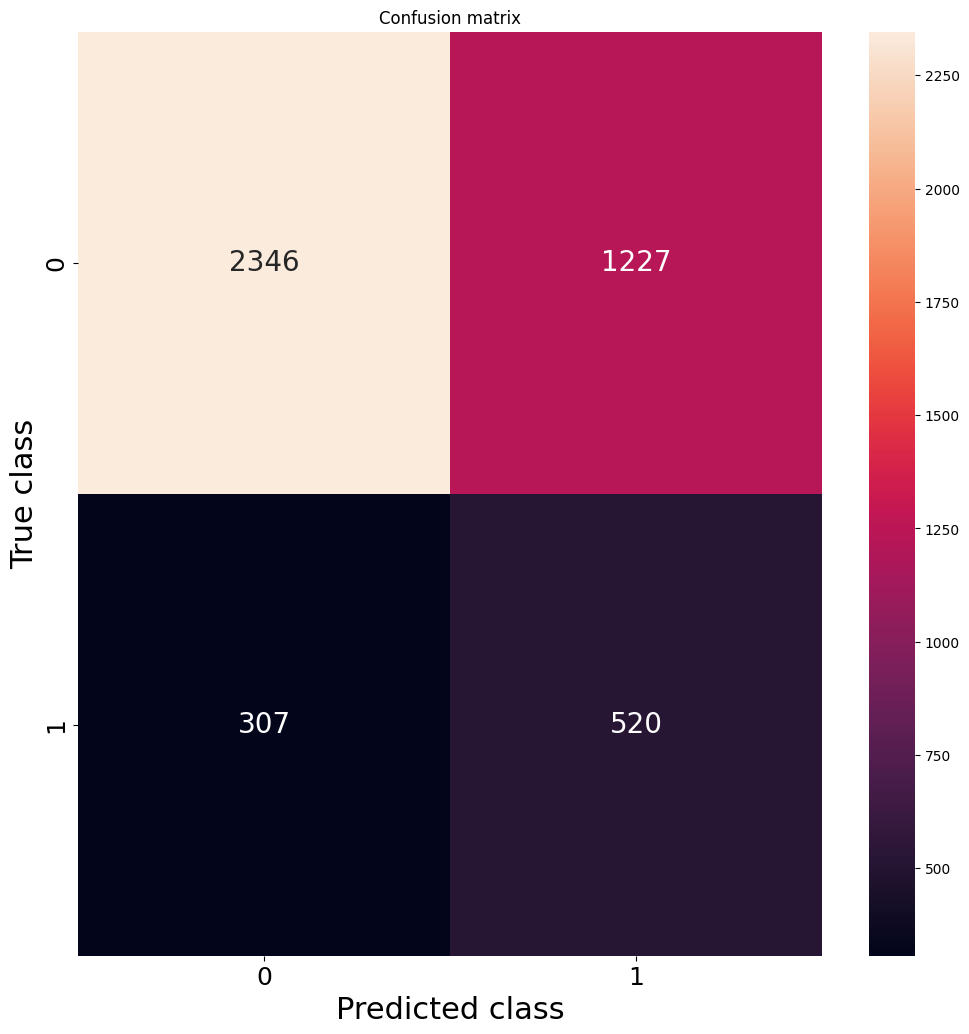

              precision    recall  f1-score   support

           0       0.88      0.66      0.75      3573
           1       0.30      0.63      0.40       827

    accuracy                           0.65      4400
   macro avg       0.59      0.64      0.58      4400
weighted avg       0.77      0.65      0.69      4400

Balanced Accuracy: 0.6427
Average Precision (PR-AUC): 0.3648
ROC AUC: 0.6978

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,1,1,0.650207
1,1,0,0.254349
2,0,0,0.184538
3,0,0,0.217058
4,0,0,0.472160
5,0,0,0.098401
6,0,1,0.553338
7,0,0,0.315144
8,0,0,0.207507
9,0,1,0.625770


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score, recall_score
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform
import warnings
warnings.filterwarnings('ignore')

# Modificar la condición para usar las variables del modelo con Sentence Transformers
if 'X_train_processed_st' in locals() and 'y_train_desc_st' in locals() and \
   'X_test_processed_st' in locals() and 'y_test_desc_st' in locals() and 'mostrar_resultados' in globals():
    print("\n--- Realizando Randomized Search para Regresión Logística con Sentence Embeddings --- (Optimizado por Average Precision)")

    # CAMBIO: solver='saga' -> 'liblinear' (el cambio de mayor impacto en velocidad).
    # liblinear soporta l1 y l2 igual que saga, pero converge mucho más rápido en
    # datos dispersos de alta dimensión (TF-IDF) mediante descenso de coordenadas.
    log_reg = LogisticRegression(random_state=1, max_iter=500)  # max_iter bajado también, liblinear lo necesita menos

    param_distributions = {
        'C': loguniform(0.001, 100),
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear'],  # CAMBIO
        'class_weight': [None, 'balanced']
    }

    random_search = RandomizedSearchCV(
        estimator=log_reg,
        param_distributions=param_distributions,
        n_iter=10,
        cv=3,
        scoring='average_precision', # REVERTIDO: Optimización por Average Precision
        verbose=2,
        random_state=42,
        n_jobs=-1
    )

    # Usar los datos con Sentence Transformers para el ajuste
    random_search.fit(X_train_processed_st, y_train_desc_st)

    print("\n--- Resultados del Randomized Search con Sentence Embeddings --- (Optimizado por Average Precision)")
    print(f"Mejores parámetros: {random_search.best_params_}")
    print(f"Mejor puntuación (Average Precision): {random_search.best_score_:.4f}")

    best_model_rs = random_search.best_estimator_
    print("Modelo de Regresión Logística (Randomized Search con Sentence Embeddings) entrenado con los mejores parámetros.")

    # Realizar predicciones usando los datos de prueba con Sentence Transformers
    pred_y_random_search = best_model_rs.predict(X_test_processed_st)
    pred_proba_random_search = best_model_rs.predict_proba(X_test_processed_st)[:, 1]

    print("\n--- Métricas de Evaluación en el Conjunto de Prueba (Modelo Randomized Search con Sentence Embeddings) --- (Optimizado por Average Precision)")
    mostrar_resultados(y_test_desc_st, pred_y_random_search, pred_proba_random_search)

else:
    print("Las variables para el modelo con Sentence Embeddings (X_train_processed_st, y_train_desc_st, X_test_processed_st, y_test_desc_st) o la función mostrar_resultados no están disponibles.")

Distribución antes del undersampling (ST): Counter({0: 14291, 1: 3308})
Distribución después del undersampling (ST): Counter({0: 6616, 1: 3308})

--- Entrenando Modelo con datos remuestreados (NearMiss con ST) ---
Modelo de Regresión Logística (NearMiss con ST) entrenado.

--- Métricas de Evaluación en el Conjunto de Prueba (Modelo NearMiss con ST) ---


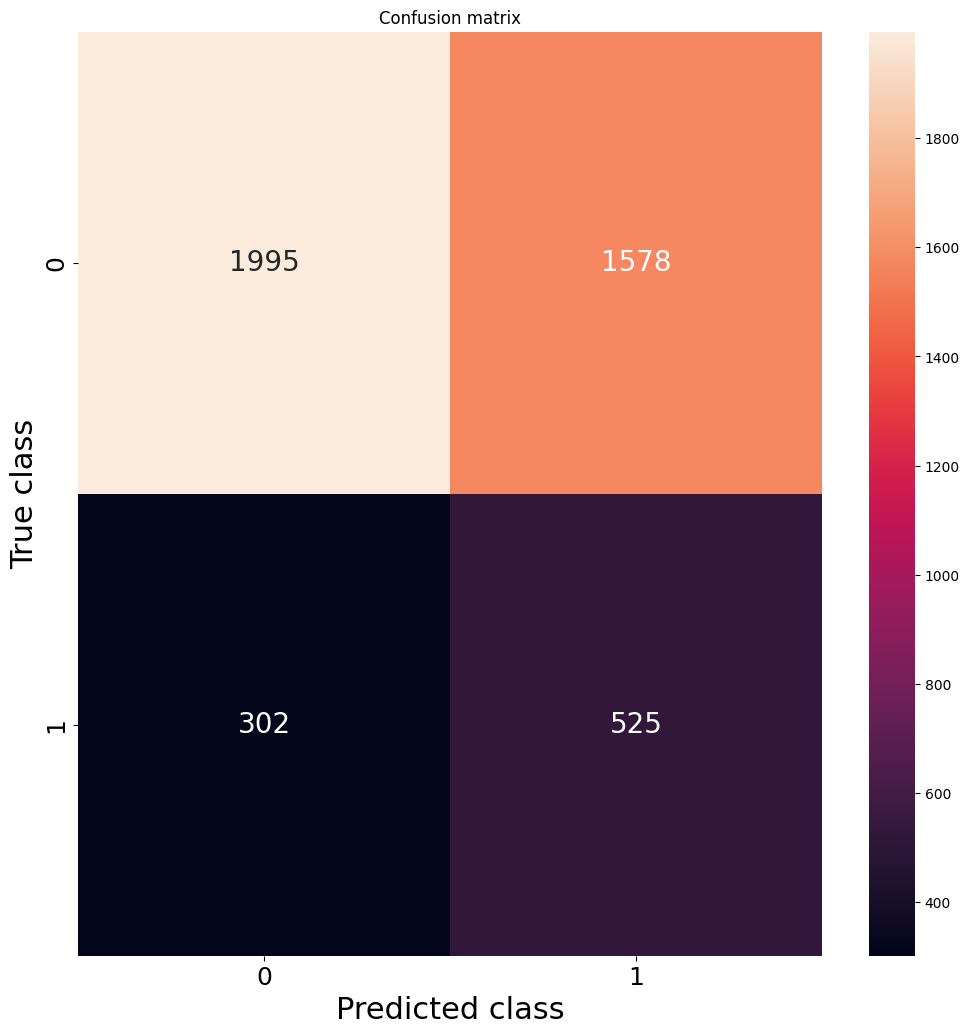

              precision    recall  f1-score   support

           0       0.87      0.56      0.68      3573
           1       0.25      0.63      0.36       827

    accuracy                           0.57      4400
   macro avg       0.56      0.60      0.52      4400
weighted avg       0.75      0.57      0.62      4400

Balanced Accuracy: 0.5966
Average Precision (PR-AUC): 0.2832
ROC AUC: 0.6430

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,1,1,0.747228
1,1,1,0.569882
2,0,0,0.257464
3,0,0,0.303555
4,0,0,0.392385
5,0,0,0.103966
6,0,1,0.542490
7,0,0,0.286179
8,0,0,0.151047
9,0,1,0.523594


In [ ]:
from imblearn.under_sampling import NearMiss
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Asegurarse de que X_train_processed_st, y_train_desc_st, X_test_processed_st, y_test_desc_st están disponibles del preprocesamiento anterior.
# Asegurarse de que run_model_balanced y mostrar_resultados están definidos en celdas anteriores.

# 1. Aplicar undersampling con NearMiss
print(f"Distribución antes del undersampling (ST): {Counter(y_train_desc_st)}")
us = NearMiss(sampling_strategy=0.5, n_neighbors=3, version=2)
X_train_res_st, y_train_res_st = us.fit_resample(X_train_processed_st, y_train_desc_st)
print(f"Distribución después del undersampling (ST): {Counter(y_train_res_st)}")

# 2. Entrenar el modelo con los datos remuestreados
print("\n--- Entrenando Modelo con datos remuestreados (NearMiss con ST) ---")
# Usar la función run_model_balanced definida previamente
model_resampled_st = run_model_balanced(X_train_res_st, y_train_res_st)
print("Modelo de Regresión Logística (NearMiss con ST) entrenado.")

# 3. Realizar predicciones y mostrar resultados en el conjunto de prueba original
pred_y_resampled_st = model_resampled_st.predict(X_test_processed_st)
pred_proba_resampled_st = model_resampled_st.predict_proba(X_test_processed_st)[:, 1]
print("\n--- Métricas de Evaluación en el Conjunto de Prueba (Modelo NearMiss con ST) ---")
mostrar_resultados(y_test_desc_st, pred_y_resampled_st, pred_proba_resampled_st)


Distribución antes del oversampling (ST): Counter({0: 14291, 1: 3308})
Distribución después del oversampling (ST): Counter({0: 14291, 1: 7145})

--- Entrenando Modelo con datos remuestreados (RandomOverSampler con ST) ---
Modelo de Regresión Logística (RandomOverSampler con ST) entrenado.

--- Métricas de Evaluación en el Conjunto de Prueba (Modelo RandomOverSampler con ST) ---


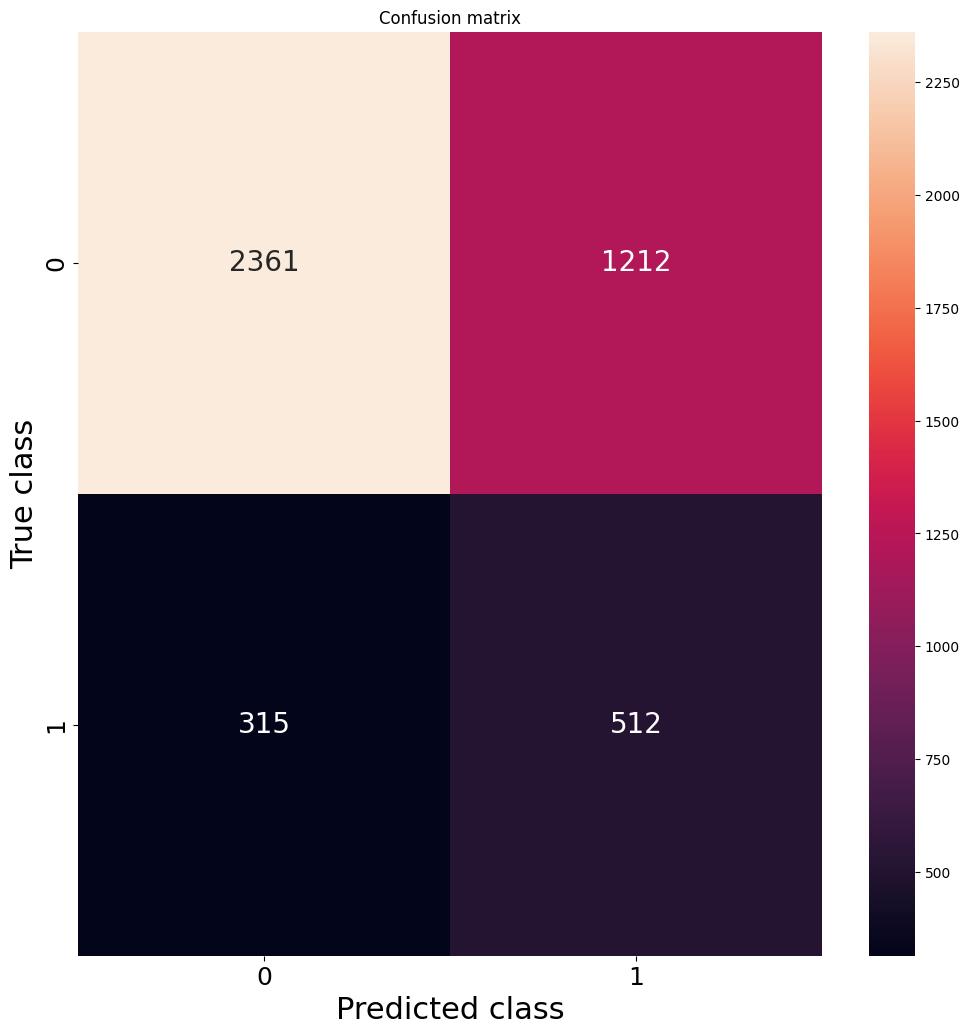

              precision    recall  f1-score   support

           0       0.88      0.66      0.76      3573
           1       0.30      0.62      0.40       827

    accuracy                           0.65      4400
   macro avg       0.59      0.64      0.58      4400
weighted avg       0.77      0.65      0.69      4400

Balanced Accuracy: 0.6399
Average Precision (PR-AUC): 0.3616
ROC AUC: 0.6964

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,1,1,0.696000
1,1,0,0.235934
2,0,0,0.187915
3,0,0,0.231959
4,0,0,0.441555
5,0,0,0.083330
6,0,1,0.605472
7,0,0,0.371670
8,0,0,0.208258
9,0,1,0.681910


In [ ]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Asegurarse de que X_train_processed_st, y_train_desc_st, X_test_processed_st, y_test_desc_st están disponibles del preprocesamiento anterior.
# Asegurarse de que run_model_balanced y mostrar_resultados están definidos en celdas anteriores.

# 1. Aplicar oversampling con RandomOverSampler
print(f"Distribución antes del oversampling (ST): {Counter(y_train_desc_st)}")
os = RandomOverSampler(sampling_strategy=0.5, random_state=42) # Usar sampling_strategy y random_state para reproducibilidad
X_train_res_st_os, y_train_res_st_os = os.fit_resample(X_train_processed_st, y_train_desc_st)
print(f"Distribución después del oversampling (ST): {Counter(y_train_res_st_os)}")

# 2. Entrenar el modelo con los datos remuestreados
print("\n--- Entrenando Modelo con datos remuestreados (RandomOverSampler con ST) ---")
# Usar la función run_model_balanced definida previamente
model_oversampled_st = run_model_balanced(X_train_res_st_os, y_train_res_st_os)
print("Modelo de Regresión Logística (RandomOverSampler con ST) entrenado.")

# 3. Realizar predicciones y mostrar resultados en el conjunto de prueba original
pred_y_oversampled_st = model_oversampled_st.predict(X_test_processed_st)
pred_proba_oversampled_st = model_oversampled_st.predict_proba(X_test_processed_st)[:, 1]
print("\n--- Métricas de Evaluación en el Conjunto de Prueba (Modelo RandomOverSampler con ST) ---")
mostrar_resultados(y_test_desc_st, pred_y_oversampled_st, pred_proba_oversampled_st)
